# Main notebook — Cross-Room CSI Human Activity Recognition

This is the **orchestration notebook** for the project. Reusable implementation belongs in `App/scripts/`; this notebook configures paths, calls those functions, checks their outputs, and records the current stage of the pipeline.

## Roadmap

1. Configure project and dataset paths.
2. Import reusable helper functions.
3. Inspect archive contents and verify capture counts.
4. Inspect one Room B CSV and create its capture-level validation split.
5. Inspect Room A PCAP structure.
6. Run Room A decoder sanity checks on one capture and across activities.
7. Export common intermediate CSVs, then check the required 150 × 256 window shape.
8. Record the remaining pipeline stages before model training.

**Leakage rule:** split original captures before generating windows. Never put windows from the same original capture in different splits.

**Implementation rule:** do not use supplied MATLAB code as the Python implementation, `.mat` processed artifacts, or the supplied Experiment-3 LSTM notebook. Keep dataset ZIPs out of version control.

**Current limitation:** Room A decoder checks below establish structural and numerical sanity, not independent physical calibration of the amplitude scale.


## 1. Configure project, source data, and intermediate CSV paths

The project keeps original data separate from generated files:

- `Source_Data/`: original challenge data (read-only; do not commit to Git).
- `Intermediate_CSV/room_A/{development,validation}/`: Room A amplitude CSVs decoded from PCAP.
- `Intermediate_CSV/room_B/{development,validation}/`: Room B amplitude CSVs copied/normalized from the supplied CSVs after the fixed capture-level split.
- `App/results/`: manifests, audits, windows, model outputs, and figures.
- `App/configs/`, `App/scripts/`, and `App/src/`: configuration, reusable preprocessing, and model code.

The cell supports running Jupyter from the project root or `App/`. It checks the new `Source_Data/` location first and falls back to the older `datasets/` location for compatibility. The source archives are never modified.

In [27]:
from pathlib import Path
import sys
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CWD = Path.cwd().resolve()

# Detect whether Jupyter was launched from the project root or App/.
if CWD.name.lower() == "app" and (CWD / "scripts").is_dir():
    APP_DIR = CWD
    PROJECT_ROOT = APP_DIR.parent
elif (CWD / "App").is_dir():
    PROJECT_ROOT = CWD
    APP_DIR = PROJECT_ROOT / "App"
else:
    raise FileNotFoundError(
        "Could not locate App/ from the current directory. "
        f"Current directory: {CWD}. Open main.ipynb from Hackathon-2/ "
        "or Hackathon-2/App/."
    )

# Recommended project folders
SOURCE_DATA_DIR = PROJECT_ROOT / "Source_Data"
INTERMEDIATE_DIR = PROJECT_ROOT / "Intermediate_CSV"
ROOM_A_DIR = INTERMEDIATE_DIR / "room_A"
ROOM_B_DIR = INTERMEDIATE_DIR / "room_B"

ROOM_A_DEV_DIR = ROOM_A_DIR / "development"
ROOM_A_VAL_DIR = ROOM_A_DIR / "validation"
ROOM_B_DEV_DIR = ROOM_B_DIR / "development"
ROOM_B_VAL_DIR = ROOM_B_DIR / "validation"

RESULTS_DIR = APP_DIR / "results"
CONFIGS_DIR = APP_DIR / "configs"
SCRIPTS_DIR = APP_DIR / "scripts"
SRC_DIR = APP_DIR / "src"

# Create only project/output directories; never move or delete source data.
for directory in [
    ROOM_A_DEV_DIR, ROOM_A_VAL_DIR, ROOM_B_DEV_DIR, ROOM_B_VAL_DIR,
    RESULTS_DIR, CONFIGS_DIR, SCRIPTS_DIR, SRC_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

if str(APP_DIR) not in sys.path:
    sys.path.insert(0, str(APP_DIR))


EXPERIMENT_2_ZIP = SOURCE_DATA_DIR / "Experiment-2.zip"
EXPERIMENT_3_ZIP = SOURCE_DATA_DIR / "Experiment-3.zip"

# Backwards-compatible variable name used by existing notebook cells.
OUTPUT_DIR = RESULTS_DIR

print("Current directory:", CWD)
print("Project root:", PROJECT_ROOT)
print("App directory:", APP_DIR)
print("Source data directory:", SOURCE_DATA_DIR, "| exists:", SOURCE_DATA_DIR.exists())
print("Experiment-2 ZIP:", EXPERIMENT_2_ZIP, "| exists:", EXPERIMENT_2_ZIP.is_file())
print("Experiment-3 ZIP:", EXPERIMENT_3_ZIP, "| exists:", EXPERIMENT_3_ZIP.is_file())
print("\nIntermediate CSV directories:")
for directory in [ROOM_A_DEV_DIR, ROOM_A_VAL_DIR, ROOM_B_DEV_DIR, ROOM_B_VAL_DIR]:
    print(f"  {directory.relative_to(PROJECT_ROOT)} | CSV files: {len(list(directory.glob('*.csv')))}")
print("\nApp directories:")
for directory in [RESULTS_DIR, CONFIGS_DIR, SCRIPTS_DIR, SRC_DIR]:
    print(f"  {directory.relative_to(PROJECT_ROOT)} | exists: {directory.is_dir()}")

Current directory: C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation\App
Project root: C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation
App directory: C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation\App
Source data directory: C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation\Source_Data | exists: True
Experiment-2 ZIP: C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation\Source_Data\Experiment-2.zip | exists: True
Experiment-3 ZIP: C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation\Source_Data\Experiment-3.zip | exists: True

Intermediate CSV directories:
  Intermediate_CSV\room_A\development | CSV files: 934
  Intermediate_CSV\room_A\validation | CSV files: 150
  Intermediate_CSV\room_B\development | CSV files: 2152
  Intermediate_CSV\room_B\validation | CSV files: 250

App directories:
  App\results | exists: True
  App\configs | exists: True
  App\scripts | exists: True
  App\src | exists: True


## 2. Import reusable functions

Keep parsing, archive inspection, split creation, and decoding in helper modules. The notebook should call those functions rather than duplicate their implementation.


In [28]:
from scripts.archive_inspection import (
    list_archive_summary,
    inspect_room_a_counts,
    inspect_room_b_counts,
    inspect_csv_inside_zip,
)
from scripts.room_b_split import (
    create_room_b_split,
    collect_room_b_captures,
)
from scripts.pcap_inspection import (
    inspect_pcap_header,
    inspect_first_packet_payload,
    inspect_packet_sequence,
)
from scripts.room_a_pcap import (
    list_pcap_members,
    read_room_a_capture,
    iter_room_a_csi
)

print("Helper imports completed.")


Helper imports completed.


## 3. Inspect dataset archives and verify capture counts

These checks inspect files inside the ZIPs without extracting the datasets. The expected totals are 1,084 Room A PCAP captures and 1,201 Room B CSV captures.


In [30]:
assert EXPERIMENT_2_ZIP.is_file(), f"Experiment-2 ZIP not found: {EXPERIMENT_2_ZIP}"
assert EXPERIMENT_3_ZIP.is_file(), f"Experiment-3 ZIP not found: {EXPERIMENT_3_ZIP}"

print("Room A archive summary")
room_a_files = list_archive_summary(EXPERIMENT_2_ZIP)

print("\nRoom B archive summary")
room_b_files = list_archive_summary(EXPERIMENT_3_ZIP)


Room A archive summary
Archive: Experiment-2.zip
Files excluding macOS metadata: 1149
File types:
  .asv: 5
  .c: 1
  .m: 25
  .mat: 2
  .mexa64: 1
  .mexw64: 1
  .pcap: 1084
  .pdf: 7
  .png: 5
  [no extension]: 18

Room B archive summary
Archive: Experiment-3.zip
Files excluding macOS metadata: 1208
File types:
  .csv: 1201
  .ipynb: 1
  .pdf: 1
  .png: 4
  [no extension]: 1


### 3.1 Room A counts

Inspect the development and supplied validation capture counts by activity.


In [31]:
room_a_counts = inspect_room_a_counts(EXPERIMENT_2_ZIP)


Room A — Experiment-2

Development:
  fall: 177
  sit: 178
  sitdown: 155
  stand: 115
  standup: 155
  walk: 154
  Total: 934

Validation:
  fall: 25
  sit: 25
  sitdown: 25
  stand: 25
  standup: 25
  walk: 25
  Total: 150


### 3.2 Room B counts and filename coverage

Room B contains five filename-derived activity groups. The filename patterns should also recognize the alternate filenames `Empty_11.csv`, `Lying_0.csv`, `Sitting_0.csv`, and `Standing_0.csv`.


In [32]:
room_b_counts, room_b_members, room_b_unmatched = inspect_room_b_counts(
    EXPERIMENT_3_ZIP
)

print("Room B total captures:", sum(room_b_counts.values()))
print("Unmatched Room B CSV files:", room_b_unmatched)

assert sum(room_b_counts.values()) == 1201, (
    f"Expected 1,201 Room B captures; found {sum(room_b_counts.values())}."
)
assert not room_b_unmatched, f"Unmatched Room B CSV files: {room_b_unmatched}"


Room B — Experiment-3
Capture counts before creating validation split:
  empty: 267
  lying: 351
  sitting: 153
  standing: 221
  walking: 209
  Total matched: 1201
Unmatched CSV files: 0
Room B total captures: 1201
Unmatched Room B CSV files: []


## 4. Inspect a representative Room B CSV

First inspect one file to confirm that the CSV-reading logic works. This is only a **smoke test**. The next subsection audits every matched Room B capture, so conclusions about data quality will not be based on one sitting capture.


In [33]:
example_candidates = room_b_members.get("sitting", [])
assert example_candidates, "No Room B 'sitting' CSV found."

example_csv_path = next(
    (p for p in example_candidates if p.lower().endswith("sitting_amp_34.csv")),
    example_candidates[0],
)
print("Example Room B CSV:", example_csv_path)
example_frame = inspect_csv_inside_zip(EXPERIMENT_3_ZIP, example_csv_path)
display(example_frame.head())


Example Room B CSV: Experiment-3/Data/Sitting_Amp_34.csv
File: Experiment-3/Data/Sitting_Amp_34.csv
Shape: (500, 256)
Columns: 256
Data types:
int64    256
Name: count, dtype: int64
Missing values: 0
Infinite values: 0
Duplicate rows: 0
All-zero rows: 0
Overall numeric min: 0
Overall numeric max: 2043


,Subcarrier_1,Subcarrier_2,Subcarrier_3,Subcarrier_4,Subcarrier_5,Subcarrier_6,Subcarrier_7,Subcarrier_8,Subcarrier_9,Subcarrier_10,...,Subcarrier_247,Subcarrier_248,Subcarrier_249,Subcarrier_250,Subcarrier_251,Subcarrier_252,Subcarrier_253,Subcarrier_254,Subcarrier_255,Subcarrier_256
0,2,1,6,1,9,2,13,691,843,445,...,3,0,10,0,2,1,2,3,1,1
1,56,7,148,552,747,188,1283,605,302,847,...,4,16,1032,39,466,424,73,234,359,217
2,2,39,25,91,108,64,1468,845,331,1236,...,11,104,299,30,155,193,77,161,65,12
3,402,213,164,209,212,163,16,171,378,586,...,451,387,320,229,154,48,14,78,87,90
4,99,325,269,151,383,1279,251,625,942,631,...,4,564,332,631,555,265,537,965,47,15


### 4.1 Audit data quality across **all** Room B captures

This cell reads every matched CSV directly from the ZIP and records one row per original capture. It does not edit or delete source data.

Checks include:
- row/column counts and unexpected column counts (expected: 256 subcarriers);
- missing values, infinite values, and non-numeric cells;
- duplicate rows and all-zero rows;
- per-file numeric minimum and maximum;
- data types and whether a file contains any numeric values.

A finding is a **flag for review**, not an instruction to delete data. Different capture lengths may be valid, so row count is summarized and plotted rather than automatically treated as an error.

In [34]:
from zipfile import ZipFile
import matplotlib.pyplot as plt

EXPECTED_SUBCARRIERS = 256
room_b_paths = sorted(
    {path for paths in room_b_members.values() for path in paths},
    key=str.lower,
)
audit_rows = []

with ZipFile(EXPERIMENT_3_ZIP) as archive:
    for member_path in room_b_paths:
        with archive.open(member_path) as file_obj:
            raw = pd.read_csv(file_obj)

        # Convert cells only for numeric diagnostics; retain raw data unchanged.
        numeric = raw.apply(pd.to_numeric, errors="coerce")
        raw_missing = int(raw.isna().sum().sum())
        nonnumeric_cells = int((raw.notna() & numeric.isna()).sum().sum())
        numeric_array = numeric.to_numpy(dtype=np.float64, na_value=np.nan)
        infinite_count = int(np.isinf(numeric_array).sum())
        duplicate_rows = int(raw.duplicated().sum())
        all_zero_rows = int(
            (numeric.fillna(0).eq(0).all(axis=1)).sum()
        )

        finite_values = numeric_array[np.isfinite(numeric_array)]
        numeric_min = float(finite_values.min()) if finite_values.size else np.nan
        numeric_max = float(finite_values.max()) if finite_values.size else np.nan

        # Infer activity from the already-checked filename mapping.
        activity = next(
            label for label, paths in room_b_members.items()
            if member_path in paths
        )
        audit_rows.append({
            "capture_path": member_path,
            "activity": activity,
            "rows": int(raw.shape[0]),
            "columns": int(raw.shape[1]),
            "missing_values": raw_missing,
            "infinite_values": infinite_count,
            "nonnumeric_cells": nonnumeric_cells,
            "duplicate_rows": duplicate_rows,
            "all_zero_rows": all_zero_rows,
            "numeric_min": numeric_min,
            "numeric_max": numeric_max,
            "dtype_summary": ", ".join(
                f"{dtype}:{count}" for dtype, count
                in raw.dtypes.astype(str).value_counts().items()
            ),
            "no_numeric_values": not bool(finite_values.size),
        })

room_b_quality = pd.DataFrame(audit_rows).sort_values(
    ["activity", "capture_path"]
).reset_index(drop=True)

assert len(room_b_quality) == len(room_b_paths), (
    "The audit should contain exactly one row per matched CSV capture."
)

issue_columns = [
    "missing_values", "infinite_values", "nonnumeric_cells",
    "duplicate_rows", "all_zero_rows",
]
room_b_quality["unexpected_columns"] = (
    room_b_quality["columns"] != EXPECTED_SUBCARRIERS
)
room_b_quality["has_any_flag"] = (
    room_b_quality[issue_columns].gt(0).any(axis=1)
    | room_b_quality["unexpected_columns"]
    | room_b_quality["no_numeric_values"]
)

print(f"Room B captures audited: {len(room_b_quality)}")
print(f"Expected subcarrier columns per capture: {EXPECTED_SUBCARRIERS}")
print(f"Captures with one or more flags: {int(room_b_quality['has_any_flag'].sum())}")
print("\nOverall quality summary:")
display(pd.DataFrame({
    "metric": [
        "Captures audited",
        "Captures with missing values",
        "Captures with infinite values",
        "Captures with non-numeric cells",
        "Captures with duplicate rows",
        "Captures with all-zero rows",
        "Captures with unexpected column count",
        "Captures with no finite numeric values",
    ],
    "count": [
        len(room_b_quality),
        int((room_b_quality["missing_values"] > 0).sum()),
        int((room_b_quality["infinite_values"] > 0).sum()),
        int((room_b_quality["nonnumeric_cells"] > 0).sum()),
        int((room_b_quality["duplicate_rows"] > 0).sum()),
        int((room_b_quality["all_zero_rows"] > 0).sum()),
        int(room_b_quality["unexpected_columns"].sum()),
        int(room_b_quality["no_numeric_values"].sum()),
    ],
}))

print("\nCapture counts by activity:")
display(room_b_quality.groupby("activity").size().rename("captures").to_frame())

print("\nRow/column count distribution:")
display(
    room_b_quality.groupby("activity")[["rows", "columns"]]
    .agg(["min", "median", "max"])
)

print("\nFiles with any flags (empty table means no flags were found):")
display(
    room_b_quality.loc[
        room_b_quality["has_any_flag"],
        ["capture_path", "activity", "rows", "columns", *issue_columns,
         "numeric_min", "numeric_max", "unexpected_columns", "no_numeric_values"]
    ]
)

print("\nPer-file audit table (first 20 rows):")
display(room_b_quality.head(20))

# Keep a complete CSV report in results/ for later review.
QUALITY_REPORT = OUTPUT_DIR / "room_b_quality_audit.csv"
room_b_quality.to_csv(QUALITY_REPORT, index=False)
print("Full per-file audit saved to:", QUALITY_REPORT)

Room B captures audited: 1201
Expected subcarrier columns per capture: 256
Captures with one or more flags: 0

Overall quality summary:


,metric,count
0,Captures audited,1201
1,Captures with missing values,0
2,Captures with infinite values,0
3,Captures with non-numeric cells,0
4,Captures with duplicate rows,0
5,Captures with all-zero rows,0
6,Captures with unexpected column count,0
7,Captures with no finite numeric values,0



Capture counts by activity:


,captures
activity,
empty,267
lying,351
sitting,153
standing,221
walking,209



Row/column count distribution:


...


Files with any flags (empty table means no flags were found):


,capture_path,activity,rows,columns,missing_values,infinite_values,nonnumeric_cells,duplicate_rows,all_zero_rows,numeric_min,numeric_max,unexpected_columns,no_numeric_values



Per-file audit table (first 20 rows):


,capture_path,activity,rows,columns,missing_values,infinite_values,nonnumeric_cells,duplicate_rows,all_zero_rows,numeric_min,numeric_max,dtype_summary,no_numeric_values,unexpected_columns,has_any_flag
0,Experiment-3/Data/Empty_11.csv,empty,500,256,0,0,0,0,0,0.0,2044.0,int64:256,False,False,False
1,Experiment-3/Data/Empty_Amp_1.csv,empty,500,256,0,0,0,0,0,0.0,2045.0,int64:256,False,False,False
2,Experiment-3/Data/Empty_Amp_10.csv,empty,500,256,0,0,0,0,0,0.0,2041.0,int64:256,False,False,False
3,Experiment-3/Data/Empty_Amp_100.csv,empty,500,256,0,0,0,0,0,0.0,2047.0,int64:256,False,False,False
4,Experiment-3/Data/Empty_Amp_101.csv,empty,500,256,0,0,0,0,0,0.0,2045.0,int64:256,False,False,False
5,Experiment-3/Data/Empty_Amp_102.csv,empty,500,256,0,0,0,0,0,0.0,2044.0,int64:256,False,False,False
6,Experiment-3/Data/Empty_Amp_103.csv,empty,500,256,0,0,0,0,0,0.0,2046.0,int64:256,False,False,False
7,Experiment-3/Data/Empty_Amp_104.csv,empty,500,256,0,0,0,0,0,0.0,2047.0,int64:256,False,False,False
8,Experiment-3/Data/Empty_Amp_105.csv,empty,500,256,0,0,0,0,0,0.0,2044.0,int64:256,False,False,False
9,Experiment-3/Data/Empty_Amp_106.csv,empty,500,256,0,0,0,0,0,0.0,2042.0,int64:256,False,False,False


Full per-file audit saved to: C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation\App\results\room_b_quality_audit.csv


### 4.2 Plot the Room B audit results

These plots help spot unusual capture lengths, activity-specific range differences, and the frequency of quality flags. They are diagnostic summaries; a visual outlier is not automatically an error.

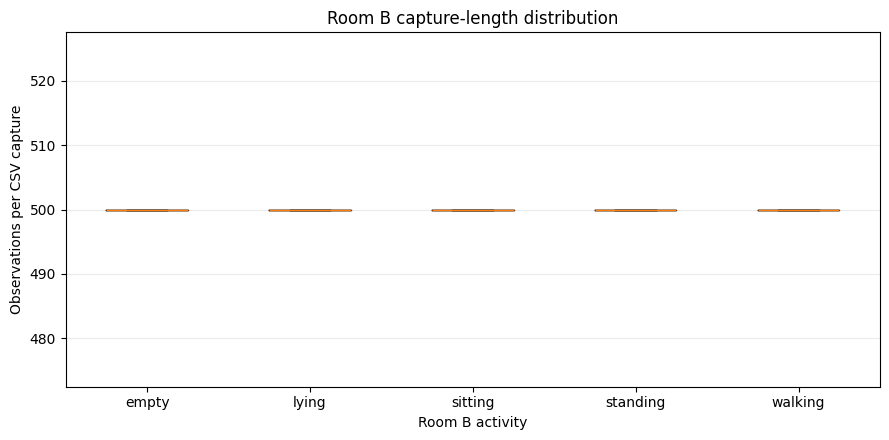

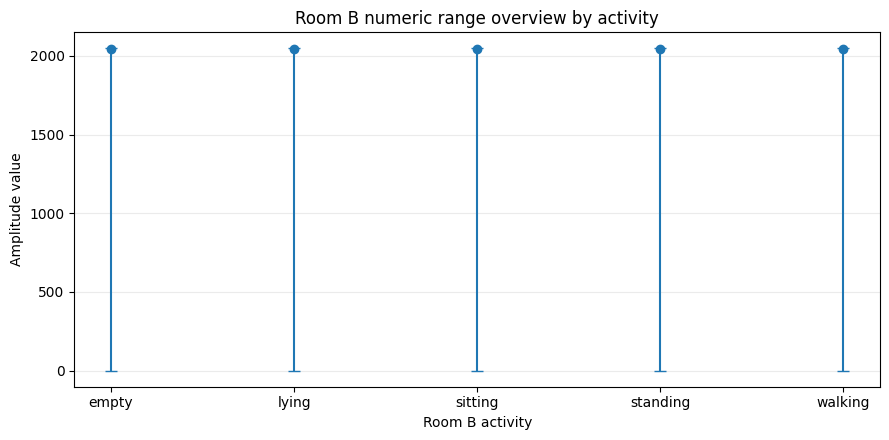

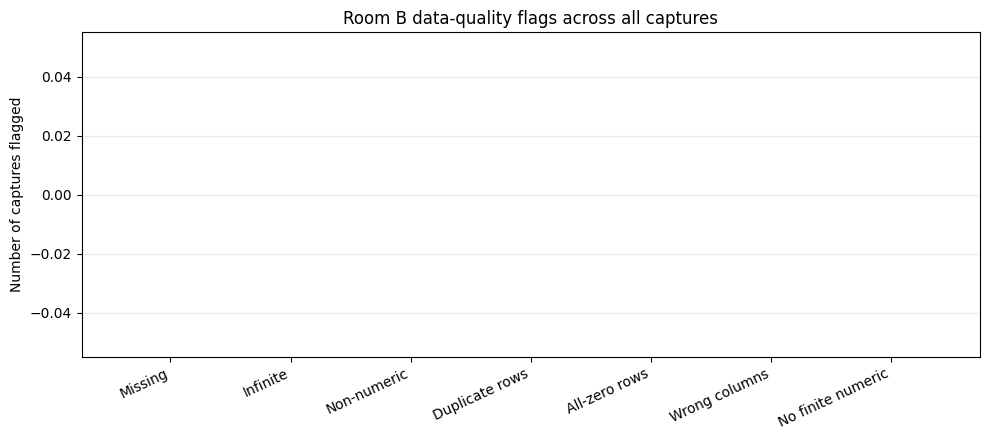

In [35]:
# Plot 1: distribution of observation counts per capture by activity.
activity_order = sorted(room_b_quality["activity"].unique())
row_groups = [
    room_b_quality.loc[room_b_quality["activity"] == activity, "rows"].to_numpy()
    for activity in activity_order
]
plt.figure(figsize=(9, 4.5))
plt.boxplot(row_groups, tick_labels=activity_order, showfliers=True)
plt.xlabel("Room B activity")
plt.ylabel("Observations per CSV capture")
plt.title("Room B capture-length distribution")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Plot 2: per-capture numeric ranges (min/max), grouped by activity.
range_summary = room_b_quality.groupby("activity").agg(
    median_min=("numeric_min", "median"),
    median_max=("numeric_max", "median"),
    min_of_min=("numeric_min", "min"),
    max_of_max=("numeric_max", "max"),
).reindex(activity_order)
x = np.arange(len(activity_order))
plt.figure(figsize=(9, 4.5))
plt.errorbar(
    x, range_summary["median_max"],
    yerr=[
        range_summary["median_max"] - range_summary["median_min"],
        range_summary["max_of_max"] - range_summary["median_max"],
    ],
    fmt="o", capsize=4, label="Median maximum with range indicator"
)
plt.xticks(x, activity_order)
plt.xlabel("Room B activity")
plt.ylabel("Amplitude value")
plt.title("Room B numeric range overview by activity")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Plot 3: number of captures with each quality flag.
flag_counts = pd.Series({
    "Missing": int((room_b_quality["missing_values"] > 0).sum()),
    "Infinite": int((room_b_quality["infinite_values"] > 0).sum()),
    "Non-numeric": int((room_b_quality["nonnumeric_cells"] > 0).sum()),
    "Duplicate rows": int((room_b_quality["duplicate_rows"] > 0).sum()),
    "All-zero rows": int((room_b_quality["all_zero_rows"] > 0).sum()),
    "Wrong columns": int(room_b_quality["unexpected_columns"].sum()),
    "No finite numeric": int(room_b_quality["no_numeric_values"].sum()),
})
plt.figure(figsize=(10, 4.5))
plt.bar(flag_counts.index, flag_counts.values)
plt.ylabel("Number of captures flagged")
plt.title("Room B data-quality flags across all captures")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 4.3 Per-subcarrier mean of one Room A and one Room B capture

This step takes **one capture from each room** in `Intermediate_CSV/` (the common 256-column amplitude form) and computes the **mean amplitude of every subcarrier** over all observations of that capture. Both captures show the same activity (sitting) and come from the development split.

- **Left plot:** the mean of each of the 256 subcarriers, with a band of ± 1 standard deviation (how much that subcarrier varies within the capture).
- **Right plot:** the distribution of those 256 means (how many subcarriers have a low, medium or high mean).
- **Table:** summary statistics of the 256 means per capture.

To compare other captures, change `ROOM_A_CAPTURE` and `ROOM_B_CAPTURE` to another original capture name (for example `walk1` or `Walking_0`). Both intermediate-CSV naming styles are found (`...__sit1.csv` from `build_dataset.py` and `...__sit1__<hash>.csv` from Section 7.a).

Room A: Intermediate_CSV\room_A\development\A__development__sit__sit1.csv -> 218 observations x 256 subcarriers
Room B: Intermediate_CSV\room_B\development\B__development__sitting__Sitting_0.csv -> 500 observations x 256 subcarriers

Distribution of the 256 per-subcarrier means:


,Room A,Room B
subcarriers,256.0,256.0
mean of means,364.5,277.7
std of means,408.8,110.3
min,3.3,40.8
25%,141.4,203.1
median,209.5,256.1
75%,288.5,352.0
max,1530.9,533.8


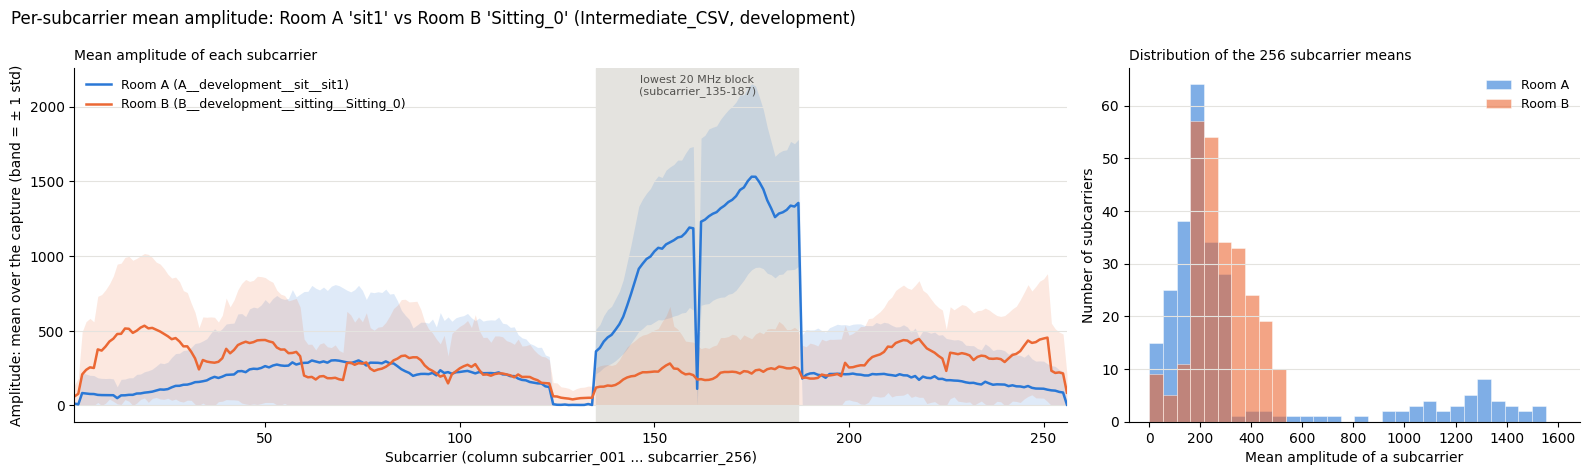

In [36]:
# ============================================================
# 4.3 Per-subcarrier mean of one Room A and one Room B capture
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Original capture names to compare (same activity, development split).
ROOM_A_CAPTURE = "sit1"         # Room A: sit/sit1.pcap
ROOM_B_CAPTURE = "Sitting_0"    # Room B: Data/Sitting_0.csv


def find_intermediate_csv(folder, capture_name):
    """Return the intermediate CSV of one original capture.

    Accepts both naming styles: `<...>__sit1.csv` and `<...>__sit1__<hash>.csv`.
    """
    matches = sorted(
        path for path in folder.glob("*.csv")
        if path.stem == capture_name
        or path.stem.endswith(f"__{capture_name}")
        or f"__{capture_name}__" in path.stem
    )
    if not matches:
        raise FileNotFoundError(f"No intermediate CSV for capture {capture_name!r} in {folder}")
    return matches[0]


captures = {
    "Room A": find_intermediate_csv(ROOM_A_DEV_DIR, ROOM_A_CAPTURE),
    "Room B": find_intermediate_csv(ROOM_B_DEV_DIR, ROOM_B_CAPTURE),
}
ROOM_COLORS = {"Room A": "#2a78d6", "Room B": "#eb6834"}

subcarrier_stats = {}
for room, csv_path in captures.items():
    amplitudes = pd.read_csv(csv_path)
    assert amplitudes.shape[1] == 256, f"{csv_path.name}: expected 256 columns, got {amplitudes.shape[1]}"
    # Mean and standard deviation of every subcarrier over all observations of the capture.
    subcarrier_stats[room] = pd.DataFrame({
        "mean": amplitudes.mean(axis=0),
        "std": amplitudes.std(axis=0),
    })
    print(f"{room}: {csv_path.relative_to(PROJECT_ROOT)} -> {amplitudes.shape[0]} observations x 256 subcarriers")

# Summary of the 256 per-subcarrier means of each capture.
mean_summary = pd.DataFrame({room: stats["mean"].describe() for room, stats in subcarrier_stats.items()}).round(1)
mean_summary.index = ["subcarriers", "mean of means", "std of means", "min", "25%", "median", "75%", "max"]
print("\nDistribution of the 256 per-subcarrier means:")
display(mean_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
subcarrier_number = np.arange(1, 257)       # matches the column names subcarrier_001 ... subcarrier_256

# Left: mean of each subcarrier, with a +/- 1 standard deviation band over the capture.
ax = axes[0]
for room, stats in subcarrier_stats.items():
    ax.plot(subcarrier_number, stats["mean"], color=ROOM_COLORS[room], linewidth=1.8,
            label=f"{room} ({captures[room].stem})")
    ax.fill_between(subcarrier_number, (stats["mean"] - stats["std"]).clip(lower=0),
                    stats["mean"] + stats["std"], color=ROOM_COLORS[room], alpha=0.15, linewidth=0)
ax.axvspan(135, 187, color="#e4e3df", zorder=0)
ax.text(161, ax.get_ylim()[1] * 0.98, "lowest 20 MHz block\n(subcarrier_135-187)", ha="center", va="top",
        fontsize=8, color="#52514e")
ax.set_xlim(1, 256)
ax.set_xlabel("Subcarrier (column subcarrier_001 ... subcarrier_256)")
ax.set_ylabel("Amplitude: mean over the capture (band = ± 1 std)")
ax.set_title("Mean amplitude of each subcarrier", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9, loc="upper left")

# Right: how the 256 subcarrier means are distributed.
ax = axes[1]
bins = np.linspace(0, max(stats["mean"].max() for stats in subcarrier_stats.values()) * 1.05, 31)
for room, stats in subcarrier_stats.items():
    ax.hist(stats["mean"], bins=bins, color=ROOM_COLORS[room], alpha=0.6, label=room,
            edgecolor="white", linewidth=0.5)
ax.set_xlabel("Mean amplitude of a subcarrier")
ax.set_ylabel("Number of subcarriers")
ax.set_title("Distribution of the 256 subcarrier means", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9)

for ax in axes:
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle(f"Per-subcarrier mean amplitude: Room A '{ROOM_A_CAPTURE}' vs Room B '{ROOM_B_CAPTURE}' "
             "(Intermediate_CSV, development)", x=0.01, ha="left")
fig.tight_layout()
plt.show()


**Findings — per-subcarrier means (Room A `sit1`, 218 observations; Room B `Sitting_0`, 500 observations)**

| Statistic of the 256 subcarrier means | Room A `sit1` | Room B `Sitting_0` |
|---|---:|---:|
| Median | 210 | 256 |
| Minimum | 3 | 41 |
| Maximum | 1,531 | 534 |
| Standard deviation | 409 | 110 |

1. **Room A has two groups of subcarriers.** Most means lie between 0 and 400, but about 50 subcarriers have means of 900–1,550. These are the lowest 20 MHz block (`subcarrier_135`–`subcarrier_187`). About 70% of Room A packets fill only this block, and the chip's autoscaling makes their values large there. The dip at `subcarrier_161` is the centre (null) of that 20 MHz block.
2. **Room B has one group.** Its means lie between 41 and 534 with no special block; the profile varies smoothly across the channel.
3. **Both rooms have low values at the same positions**: `subcarrier_001`–`002`, `subcarrier_124`–`134` and `subcarrier_256`. These are the null and guard subcarriers of the 80 MHz channel, so both rooms use the same subcarrier order.
4. **Values vary strongly within each capture** (wide bands). In Room A this mostly comes from alternating narrow and full packets; in Room B from the weak consistency between consecutive rows.

These two captures illustrate the room-level pattern seen across all captures: Room A's subcarrier profile is dominated by the packet-width difference, which must be handled before comparing rooms (see Task 1).

## 5. Create the Room B capture-level validation manifest

Select 25 original captures per activity using sorted filenames and seed `42`. This manifest must be created **before windowing**. It contains one row per original capture and defines 125 validation captures plus 1,076 development captures.


In [37]:
ROOM_B_MANIFEST = OUTPUT_DIR / "room_b_capture_split.csv"

create_room_b_split(
    zip_path=EXPERIMENT_3_ZIP,
    output_csv=ROOM_B_MANIFEST,
    validation_per_class=25,
    seed=42,
)

room_b_manifest = pd.read_csv(ROOM_B_MANIFEST)
display(room_b_manifest.groupby(["split", "activity"]).size().unstack(fill_value=0))
print("\nManifest saved to:", ROOM_B_MANIFEST)


Saved capture manifest: C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation\App\results\room_b_capture_split.csv
Total captures: 1201

Validation: 125
  empty: 25
  lying: 25
  sitting: 25
  standing: 25
  walking: 25

Development: 1076
  empty: 242
  lying: 326
  sitting: 128
  standing: 196
  walking: 184


activity,empty,lying,sitting,standing,walking
split,,,,,
development,242,326,128,196,184
validation,25,25,25,25,25



Manifest saved to: C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation\App\results\room_b_capture_split.csv


### 5.1 Check split integrity

Confirm the manifest has one row per capture, exactly 25 validation captures per activity, and the expected overall totals.


In [40]:
assert len(room_b_manifest) == 1201
assert room_b_manifest["capture_path"].is_unique
assert set(room_b_manifest["split"].unique()) == {"development", "validation"}
assert (
    room_b_manifest.groupby("activity")["split"]
    .apply(lambda values: (values == "validation").sum())
    == 25
).all()
assert (room_b_manifest["split"] == "validation").sum() == 125
assert (room_b_manifest["split"] == "development").sum() == 1076

print("All Room B split integrity checks passed.")


All Room B split integrity checks passed.


## 5.a Create Room B intermediate CSV folders

Room B already contains amplitude CSV files with 256 subcarrier columns. This step uses the fixed capture-level split manifest and writes a normalized copy of each source CSV into `Intermediate_CSV/room_B/development/` or `validation/`. Source data remains untouched.

Each output CSV uses the common column names `subcarrier_001` through `subcarrier_256`. A manifest records the source archive member, activity, split, output path, and status.

In [42]:
# ============================================================
# 5.2 Export Room B Source CSVs to the Intermediate Structure
# ============================================================

from zipfile import ZipFile
from pathlib import PurePosixPath

ROOM_B_CSV_MANIFEST = OUTPUT_DIR / "room_b_intermediate_csv_manifest.csv"
COMMON_COLUMNS = [f"subcarrier_{i:03d}" for i in range(1, 257)]

assert EXPERIMENT_3_ZIP.is_file(), f"Room B archive not found: {EXPERIMENT_3_ZIP}"
assert ROOM_B_MANIFEST.is_file(), f"Room B split manifest not found: {ROOM_B_MANIFEST}"

room_b_manifest = pd.read_csv(ROOM_B_MANIFEST)
required = {"capture_path", "activity", "split"}
assert required.issubset(room_b_manifest.columns)
assert room_b_manifest["capture_path"].is_unique
assert set(room_b_manifest["split"]) == {"development", "validation"}

room_b_intermediate_rows = []
with ZipFile(EXPERIMENT_3_ZIP) as archive:
    archive_members = set(archive.namelist())

    for _, row in room_b_manifest.iterrows():
        source_member = row["capture_path"]
        activity = str(row["activity"]).lower()
        split = str(row["split"])
        output_dir = ROOM_B_VAL_DIR if split == "validation" else ROOM_B_DEV_DIR
        source_stem = PurePosixPath(source_member).stem
        output_path = output_dir / f"{activity}__{source_stem}.csv"

        record = {
            "capture_path": source_member,
            "activity": activity,
            "split": split,
            "intermediate_csv_path": str(output_path.relative_to(INTERMEDIATE_DIR)),
            "status": "failed",
            "error": None,
        }

        try:
            if source_member not in archive_members:
                raise FileNotFoundError(f"Missing archive member: {source_member}")

            with archive.open(source_member) as source_file:
                frame = pd.read_csv(source_file)

            if frame.shape != (500, 256):
                raise ValueError(f"Expected 500 x 256, got {frame.shape}")

            frame = frame.apply(pd.to_numeric, errors="raise")
            values = frame.to_numpy(dtype=np.float32)

            if not np.isfinite(values).all():
                raise ValueError("CSV contains non-finite values")

            frame.columns = COMMON_COLUMNS
            frame.to_csv(output_path, index=False)
            record["status"] = "ok"

        except Exception as exc:
            record["error"] = f"{type(exc).__name__}: {exc}"

        room_b_intermediate_rows.append(record)

room_b_intermediate_manifest = pd.DataFrame(room_b_intermediate_rows)
room_b_intermediate_manifest.to_csv(ROOM_B_CSV_MANIFEST, index=False)

print("Room B intermediate CSV export")
print("------------------------------")
display(room_b_intermediate_manifest["status"].value_counts().rename_axis("status").to_frame("captures"))
print("CSV files written:", int((room_b_intermediate_manifest["status"] == "ok").sum()))
print("Manifest:", ROOM_B_CSV_MANIFEST)

assert (room_b_intermediate_manifest["status"] == "ok").all(), (
    "Some Room B CSV exports failed. Inspect the manifest error column."
)
# Count the files this cell wrote; the folders may also hold build_dataset.py's own copies.
written = room_b_intermediate_manifest["intermediate_csv_path"].map(
    lambda path: (INTERMEDIATE_DIR / path).is_file()
)
assert written.all(), "Some Room B intermediate CSVs listed in the manifest are missing."
assert (room_b_intermediate_manifest["split"] == "development").sum() == 1076
assert (room_b_intermediate_manifest["split"] == "validation").sum() == 125
print("Room B intermediate export checks passed.")

Room B intermediate CSV export
------------------------------


,captures
status,
ok,1201


CSV files written: 1201
Manifest: C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation\App\results\room_b_intermediate_csv_manifest.csv
Room B intermediate export checks passed.


## 6. Inspect Room A PCAP structure
Room A contains raw packet captures rather than pre-exported amplitude CSVs. First inspect the PCAP header, then inspect the packet payload and a short packet sequence. These steps establish the observed packet structure before relying on the decoder.

### 6.1 Inspect Room A PCAP header

In [ ]:
pcap_info = inspect_pcap_header(
    zip_path=EXPERIMENT_2_ZIP,
    activity="fall",
    packets_to_show=3,
)


Capture: Experiment-2/realdata/input_data/30ms/csidata/fall/fall10.pcap
First 24 bytes: d4 c3 b2 a1 02 00 04 00 00 00 00 00 00 00 00 00 00 00 04 00 01 00 00 00
Format: Classic PCAP
PCAP version: 2.4
Byte order: little-endian
Timestamp precision: microsecond
Snapshot length: 262144
Link-layer type: 1

First 3 packet record(s):
{'packet_index': 0, 'timestamp_seconds': 1610902926, 'timestamp_fraction': 366766, 'captured_length': 1084, 'original_length': 1084, 'first_bytes': 'ff ff ff ff ff ff 4e 45 58 4d 4f 4e 08 00 45 00 04 2e 00 01 00 00 01 11'}
{'packet_index': 1, 'timestamp_seconds': 1610902926, 'timestamp_fraction': 402418, 'captured_length': 1084, 'original_length': 1084, 'first_bytes': 'ff ff ff ff ff ff 4e 45 58 4d 4f 4e 08 00 45 00 04 2e 00 01 00 00 01 11'}
{'packet_index': 2, 'timestamp_seconds': 1610902926, 'timestamp_fraction': 402813, 'captured_length': 1084, 'original_length': 1084, 'first_bytes': 'ff ff ff ff ff ff 4e 45 58 4d 4f 4e 08 00 45 00 04 2e 00 01 00 00 01 11'}


#### Findings:

| Property | Observed Result | Interpretation |
|---|---|---|
| File format | Classic PCAP | Expected packet-capture format |
| Version | 2.4 | Valid PCAP version |
| Byte order | Little-endian | Packet records must be read accordingly |
| Timestamp precision | Microseconds | Timestamps have microsecond resolution |
| Snapshot length | 262,144 bytes | Maximum captured packet size allowed by the file header |
| Link-layer type | 1 (Ethernet) | Packet decoding starts with an Ethernet header |
| First 3 captured lengths | 1,084 bytes each | All three sample packets were captured in full, according to their record lengths |

**Observation:** The first bytes also show an Ethernet frame followed by an IPv4 header.

### 6.2 Inspect one packet payload

The current sample has Ethernet/IPv4/UDP framing. Inspect the payload fields to verify the observed marker, payload size, and likely CSI body boundary.


In [ ]:
packet_details = inspect_first_packet_payload(
    zip_path=EXPERIMENT_2_ZIP,
    activity="fall",
    payload_bytes=128,
)


Capture: Experiment-2/realdata/input_data/30ms/csidata/fall/fall10.pcap
Captured packet bytes: 1084
Destination MAC: ff:ff:ff:ff:ff:ff
Source MAC: 4e:45:58:4d:4f:4e
EtherType: 0x0800
IPv4 source: 10.10.10.10
IPv4 destination: 255.255.255.255
IPv4 header length: 20
IPv4 total length: 1070
IP protocol: 17 (17 means UDP)
UDP source port: 5500
UDP destination port: 5500
UDP length: 1050
UDP payload length: 1042

First 128 payload bytes (hex):
11 11 11 11 dc 71 96 96 40 65 ff ff 00 00 2a e0 6a 00 b1 ff 01 0a 31 00 fe 17 b0 3f fc 1f b0 ff 03 30 b1 3f 03 34 30 00 ff 0f b2 ef fe 33 30 80 fe 13 2e 00 fd 2f 32 10 fc 37 f0 7f fb 0b f1 9f 01 06 30 40 fb 1b 30 80 fa 1f b1 9f 01 0a b0 bf fe 3b f1 1f ff 05 b1 1f fd 17 2f 00 fb 17 b1 ff 03 2c f0 3f 01 00 f1 5f fd 23 31 00 f9 3b f1 1f fd 2d ae ff 01 10 b0 7f 03 38 f2 0f 03 28 31 00

ASCII preview (non-printable bytes shown as dots):
.....q..@e....*.j.....1....?.....0.?.40......30....../2..7........0@..0..........;......../......,.?..._.#1..;...-.......

#### Findigs:
#### Ethernet, IPv4, and UDP Packet Analysis

| Field | Observed Value | Interpretation |
|---|---|---|
| Ethernet type | IPv4 (`0x0800`) | The Ethernet frame carries an IPv4 packet |
| IP protocol | UDP (`17`) | The IP packet uses the User Datagram Protocol |
| UDP ports | `5500 → 5500` | Source and destination UDP ports are both 5500 |
| UDP payload length | 1,042 bytes | The UDP payload contains 1,042 bytes of application data |
| CSI marker | `11 11 11 11` | The payload begins with the expected four-byte marker |
| Apparent CSI header | Begins with the marker and includes MAC and metadata bytes | The payload appears to contain a CSI header followed by associated metadata |

#### Packet Length Verification

The length arithmetic is consistent with the observed packet structure:

- **Ethernet frame:** 1,084 bytes total.
- **Ethernet header:** 14 bytes.
- **IPv4 packet:** 1,070 bytes, calculated as `1084 - 14`.
- **IPv4 header:** 20 bytes.
- **UDP datagram:** 1,050 bytes, calculated as `1070 - 20`.
- **UDP header:** 8 bytes.
- **UDP payload:** 1,042 bytes, calculated as `1050 - 8`.

#### Observation

The captured Ethernet frame contains an IPv4 packet carrying UDP traffic on port 5500. The UDP payload begins with the expected four-byte CSI marker (11 11 11 11). The apparent CSI header also includes MAC address and metadata bytes, suggesting that the payload contains CSI-related application data.

### 6.3 Inspect a short packet sequence

Check whether packet lengths and marker bytes are consistent, whether payload contents change, and how packet timestamps are spaced. Timing patterns are observations, not proof by themselves of the sampling semantics.


In [ ]:
packet_sequence = inspect_packet_sequence(
    zip_path=EXPERIMENT_2_ZIP,
    activity="fall",
    max_packets=10,
)


Capture: Experiment-2/realdata/input_data/30ms/csidata/fall/fall10.pcap
UDP packets inspected: 10

Packet 0: delta=0.000 ms, captured=1084 bytes, payload=1042 bytes, ports=5500->5500
  Payload prefix: 11 11 11 11 dc 71 96 96 40 65 ff ff 00 00 2a e0 6a 00 b1 ff 01 0a 31 00 fe 17 b0 3f fc 1f b0 ff

Packet 1: delta=35.652 ms, captured=1084 bytes, payload=1042 bytes, ports=5500->5500
  Payload prefix: 11 11 11 11 dc 71 96 96 40 65 60 3b 00 00 2a e0 6a 00 31 80 fe 11 af ff fe 37 b0 bf 03 2c f1 5f

Packet 2: delta=36.047 ms, captured=1084 bytes, payload=1042 bytes, ports=5500->5500
  Payload prefix: 11 11 11 11 dc 71 96 96 40 65 ff ff 00 00 2a e0 6a 00 b1 ff 01 1a f1 7f fc 17 31 40 fb 13 b0 bf

Packet 3: delta=71.623 ms, captured=1084 bytes, payload=1042 bytes, ports=5500->5500
  Payload prefix: 11 11 11 11 dc 71 96 96 40 65 70 3b 00 00 2a e0 6a 00 b2 3f 01 10 af 7f fc 1f f1 3f 03 24 32 70

Packet 4: delta=72.022 ms, captured=1084 bytes, payload=1042 bytes, ports=5500->5500
  Payload prefix:

#### Findings:
#### Initial UDP Packet Consistency Checks

The captured packets pass the initial packet-consistency checks.

**Observed Results**

- All 10 inspected UDP packets use the expected source and destination ports (`5500 → 5500`).
- Every UDP payload is 1,042 bytes long.
- All 10 payloads begin with the expected four-byte marker (`11 11 11 11`).
- Packet intervals are approximately 35–36 ms, with some consecutive intervals around 0.4 ms. This suggests that packets may arrive in closely spaced pairs rather than at perfectly regular intervals.

**Interpretation**

The consistent UDP ports, payload lengths, and initial marker bytes indicate a uniform packet structure across the 10 inspected packets. The observed timing pattern may indicate burst-like or paired packet arrivals, which can be investigated further by analyzing packet timestamps.

**Conclusion**

The payload lengths and marker are consistent across all 10 inspected packets, supporting the conclusion that the captured traffic passes the initial packet-consistency checks.

### 6.4 Check the observed legacy CSI payload layout

For the inspected sample, the UDP payload begins with `11 11 11 11`; the observed payload is 1,042 bytes, with an 18-byte header followed by 1,024 bytes (256 four-byte words). The helper decoder interprets the packed real/imaginary components and exponent. The header's chip field should not be treated as conclusive chipset identification on its own.


In [ ]:
payload = packet_sequence[0]["payload"]

print("Payload length:", len(payload))
print("Magic bytes:", payload[:4].hex(" "))
if payload[:4] != b"\x11\x11\x11\x11":
    raise ValueError("Unexpected marker in inspected packet.")

print("Source MAC:", ":".join(f"{b:02x}" for b in payload[4:10]))
print("Sequence field:", payload[10:12].hex(" "))
print("Core/stream field:", payload[12:14].hex(" "))
print("Channel specification:", payload[14:16].hex(" "))
print("Chip field:", payload[16:18].hex(" "))

csi_body = payload[18:]
print("CSI body length:", len(csi_body))
if len(csi_body) != 1024:
    raise ValueError(f"Expected a 1,024-byte CSI body; got {len(csi_body)}.")

raw_words = np.frombuffer(csi_body, dtype="<u4")
print("CSI words:", len(raw_words))
print("First 12 raw words:", [f"0x{int(word):08x}" for word in raw_words[:12]])


Payload length: 1042
Magic bytes: 11 11 11 11
Source MAC: dc:71:96:96:40:65
Sequence field: ff ff
Core/stream field: 00 00
Channel specification: 2a e0
Chip field: 6a 00
CSI body length: 1024
CSI words: 256
First 12 raw words: ['0x0a01ffb1', '0x17fe0031', '0x1ffc3fb0', '0x3003ffb0', '0x34033fb1', '0x0fff0030', '0x33feefb2', '0x13fe8030', '0x2ffd002e', '0x37fc1032', '0x0bfb7ff0', '0x06019ff1']


#### Findigs:
#### CSI Payload Structure Validation

The analysis confirms that the payload structure matches the expected layout.

| Check | Result | Status |
|---|---|---|
| UDP payload length | 1,042 bytes | Pass |
| Magic marker | `11 11 11 11` | Pass |
| Metadata/header | 18 bytes total, including the 4-byte marker | Pass |
| CSI body | 1,024 bytes | Pass |
| Raw CSI words | 256 × 4 bytes | Pass |

#### Header and CSI Data Inspection

The header fields were successfully extracted, and the first 12 raw CSI words appear consistent with the expected four-byte word representation.

#### Interpretation

The observed payload length, magic marker, header size, and CSI body size match the expected packet layout. The CSI body contains 1,024 bytes, corresponding to 256 four-byte raw CSI words.

#### Conclusion

The packet layout has passed the initial structural validation checks. However, further analysis is required to validate the CSI amplitude decoder and identify any invalid, corrupted, or anomalous values across the complete dataset.

## 7. Test Room A decoder
This section verifies that the Room A PCAP decoder correctly converts raw packet data into CSI amplitude observations with 256 subcarrier values per observation. We first test the decoder on a single capture to inspect its packet structure and decoded output, then validate the output across representative captures from all six activities: fall, sit, sitdown, stand, standup, and walk. Finally, we audit all Room A captures to assess decoding success, observation counts, numerical validity, zero-valued observations, and amplitude ranges before proceeding to window extraction and model development.

### 7.1 Test Room A decoding on one capture

Decode one development capture and check output shape, dtype, and finite values. Passing these checks is a basic numerical sanity test; it does not independently establish the physical calibration of the amplitude scale.

In [ ]:
pcap_members = list_pcap_members(EXPERIMENT_2_ZIP)
print("PCAP captures found:", len(pcap_members))

matches = [
    member for member in pcap_members
    if member.lower().endswith("/fall/fall10.pcap")
    and "validation" not in {part.lower() for part in Path(member).parts}
]
if not matches:
    raise FileNotFoundError("Could not find development capture fall/fall10.pcap.")

capture_member = matches[0]
timestamps, amplitudes = read_room_a_capture(EXPERIMENT_2_ZIP, capture_member)

print("Capture:", capture_member)
print("Timestamps shape:", timestamps.shape)
print("Amplitude shape:", amplitudes.shape)
print("Amplitude dtype:", amplitudes.dtype)
print("All finite:", bool(np.isfinite(amplitudes).all()))
print("Amplitude range:", float(amplitudes.min()), "to", float(amplitudes.max()))
print("First 10 amplitudes of first observation:", amplitudes[0, :10])

assert amplitudes.ndim == 2 and amplitudes.shape[1] == 256
assert len(timestamps) == len(amplitudes)
assert amplitudes.dtype == np.float32
assert np.isfinite(amplitudes).all()


PCAP captures found: 1084
Capture: Experiment-2/realdata/input_data/30ms/csidata/fall/fall10.pcap
Timestamps shape: (240,)
Amplitude shape: (240, 256)
Amplitude dtype: float32
All finite: True
Amplitude range: 0.0 to 2126.01904296875
First 10 amplitudes of first observation: [15.811388 11.        7.        8.062258 13.453624  5.       23.600847
  4.472136  1.       23.021729]


**Findings — Room A decoder sanity check**

The initial decoder test on `fall10.pcap` successfully extracted 240 CSI observations, each containing 256 subcarrier amplitudes. The resulting amplitude matrix has shape `(240, 256)` and data type `float32`. All decoded values are finite, with amplitudes ranging from 0.0 to approximately 2126.019. The first observation contains varied amplitude values, suggesting that the decoder is extracting non-constant CSI amplitude data.

These results support the initial structural and numerical validity of the decoded output for this capture. However, this is a single-capture sanity check and does not establish data quality across the complete Room A dataset or prove the physical calibration of the amplitudes. Further checks will examine all-zero observations, numeric ranges, and decoder consistency across activities.

### 7.2. Validate Room A output across all six activities

Use one development capture per activity. This checks that parsing and decoding are not accidentally tailored to only one filename. It remains a smoke test rather than exhaustive validation of all captures.


In [ ]:
activities = ["fall", "sit", "sitdown", "stand", "standup", "walk"]
samples = {}

for member in pcap_members:
    parts = Path(member).parts
    lower_parts = [part.lower() for part in parts]
    if "validation" in lower_parts or "csidata" not in lower_parts:
        continue
    idx = lower_parts.index("csidata")
    if idx + 1 >= len(parts):
        continue
    activity = lower_parts[idx + 1]
    if activity in activities and activity not in samples:
        samples[activity] = member

print("Room A multi-activity decoder sanity check")
print("=" * 90)

for activity in activities:
    if activity not in samples:
        raise FileNotFoundError(f"No development PCAP found for activity {activity!r}.")

    member = samples[activity]
    timestamps, amplitude_values = read_room_a_capture(EXPERIMENT_2_ZIP, member)
    amplitude_values = np.asarray(amplitude_values)

    assert amplitude_values.ndim == 2 and amplitude_values.shape[1] == 256
    assert len(timestamps) == len(amplitude_values)
    assert amplitude_values.dtype == np.float32
    assert np.isfinite(amplitude_values).all()

    print(
        f"{activity:8s} | {Path(member).name:16s} | "
        f"observations={len(amplitude_values):3d} | "
        f"shape={str(amplitude_values.shape):14s} | "
        f"range={amplitude_values.min():.3f}..{amplitude_values.max():.3f} | "
        f"mean={amplitude_values.mean():.3f}"
    )

print("\nBasic checks passed for all six activity examples.")


Room A multi-activity decoder sanity check
fall     | fall10.pcap      | observations=240 | shape=(240, 256)     | range=0.000..2126.019 | mean=504.102
sit      | sit1.pcap        | observations=218 | shape=(218, 256)     | range=0.000..2124.769 | mean=364.522
sitdown  | sitdown1.pcap    | observations=234 | shape=(234, 256)     | range=0.000..2111.957 | mean=489.881
stand    | stand1.pcap      | observations=225 | shape=(225, 256)     | range=0.000..2115.005 | mean=538.773
standup  | standup1.pcap    | observations=220 | shape=(220, 256)     | range=0.000..2199.108 | mean=438.568
walk     | walk1.pcap       | observations=172 | shape=(172, 256)     | range=0.000..2117.570 | mean=320.672

Basic checks passed for all six activity examples.


**Findings — Room A multi-activity decoder sanity check**

The CSI amplitude decoder was tested on one representative PCAP capture from each of the six Room A activities: fall, sit, sitdown, stand, standup, and walk. All six captures decoded successfully into matrices with 256 subcarrier amplitude values per observation.

The number of observations ranged from 172 for `walk1.pcap` to 240 for `fall10.pcap`. All decoded values were finite, and the observed amplitude ranges were approximately 0–2,112 to 0–2,199 across the six examples. The mean amplitudes varied by activity, from approximately 320.672 for walk to 538.773 for stand.

These results support the decoder's basic operation across the six activity examples. However, they do not establish the quality of every Room A capture. In particular, the zero minimum values require further investigation to determine whether individual observations contain all-zero amplitudes or whether zeros occur only at particular subcarriers. A full-capture audit is therefore needed before window extraction and model training.

### 7.3 Full Room A Capture Audit

This audit attempts to decode every Room A development and validation PCAP capture and records capture-level diagnostics, including:

- **Decoding status and output shape:** whether decoding succeeds and the shape of the resulting amplitude matrix.
- **Observation and subcarrier counts:** the number of valid CSI observations and the number of subcarrier values per observation.
- **Numerical quality:** non-finite amplitude values and all-zero observations.
- **Amplitude statistics:** minimum, maximum, and mean amplitude values.
- **Capture errors:** decoding exceptions, malformed captures, or captures with no valid CSI observations, recorded explicitly rather than silently excluded.

The audit results are saved to a CSV file and summarized by activity to identify potential data-quality issues before window extraction and model training.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import PurePosixPath


# Confirm that the existing project paths are correct.
assert EXPERIMENT_2_ZIP.exists(), (
    f"Room A dataset archive not found: {EXPERIMENT_2_ZIP}"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Discover all Room A PCAP captures
# ------------------------------------------------------------
pcap_members = list_pcap_members(str(EXPERIMENT_2_ZIP))

print(f"Room A PCAP captures discovered: {len(pcap_members)}")

activity_names = {
    "fall", "sit", "sitdown", "stand", "standup", "walk"
}

audit_rows = []

# ------------------------------------------------------------
# 2. Decode and audit each capture
# ------------------------------------------------------------
for i, member in enumerate(pcap_members, start=1):

    path_parts = [
        part.lower() for part in PurePosixPath(member).parts
    ]

    activity = next(
        (part for part in path_parts if part in activity_names),
        "unknown"
    )

    split = (
        "validation"
        if any("validation" in part for part in path_parts)
        else "development"
    )

    row = {
        "capture_path": member,
        "activity": activity,
        "split": split,
        "decode_status": "failed",
        "observations": 0,
        "subcarriers": 256,
        "nonfinite_values": np.nan,
        "all_zero_observations": np.nan,
        "zero_amplitude_values": np.nan,
        "amplitude_min": np.nan,
        "amplitude_max": np.nan,
        "amplitude_mean": np.nan,
        "error": None,
    }

    try:
        # Retain all-zero observations so that they can be audited.
        observations = list(
            iter_room_a_csi(
                str(EXPERIMENT_2_ZIP),
                member,
                expected_subcarriers=256,
                keep_zero_observations=True,
            )
        )

        if len(observations) == 0:
            row["decode_status"] = "no_valid_csi_observations"

        else:
            amplitudes = np.stack(
                [obs.amplitude for obs in observations],
                axis=0
            ).astype(np.float32, copy=False)

            row["observations"] = amplitudes.shape[0]
            row["subcarriers"] = amplitudes.shape[1]

            row["nonfinite_values"] = int(
                (~np.isfinite(amplitudes)).sum()
            )

            row["all_zero_observations"] = int(
                np.all(amplitudes == 0, axis=1).sum()
            )

            row["zero_amplitude_values"] = int(
                (amplitudes == 0).sum()
            )

            finite_values = amplitudes[np.isfinite(amplitudes)]

            if finite_values.size > 0:
                row["amplitude_min"] = float(finite_values.min())
                row["amplitude_max"] = float(finite_values.max())
                row["amplitude_mean"] = float(finite_values.mean())

            if amplitudes.shape[1] != 256:
                row["decode_status"] = "unexpected_subcarrier_count"

            elif row["nonfinite_values"] > 0:
                row["decode_status"] = "nonfinite_values_found"

            else:
                row["decode_status"] = "ok"

    except Exception as exc:
        row["error"] = f"{type(exc).__name__}: {exc}"

    audit_rows.append(row)

    if i % 100 == 0 or i == len(pcap_members):
        print(f"Audited {i}/{len(pcap_members)} captures")

# ------------------------------------------------------------
# 3. Save the capture-level audit
# ------------------------------------------------------------
room_a_audit = pd.DataFrame(audit_rows)

audit_path = OUTPUT_DIR / "room_a_quality_audit.csv"
room_a_audit.to_csv(audit_path, index=False)

print("\nFull Room A audit completed.")
print(f"Captures discovered : {len(pcap_members)}")
print(f"Audit rows          : {len(room_a_audit)}")
print(f"Saved audit         : {audit_path}")

display(room_a_audit.head())

Room A PCAP captures discovered: 1084
Audited 100/1084 captures
Audited 200/1084 captures
Audited 300/1084 captures
Audited 400/1084 captures
Audited 500/1084 captures
Audited 600/1084 captures
Audited 700/1084 captures
Audited 800/1084 captures
Audited 900/1084 captures
Audited 1000/1084 captures
Audited 1084/1084 captures

Full Room A audit completed.
Captures discovered : 1084
Audit rows          : 1084
Saved audit         : D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_a_quality_audit.csv


,capture_path,activity,split,decode_status,observations,subcarriers,nonfinite_values,all_zero_observations,zero_amplitude_values,amplitude_min,amplitude_max,amplitude_mean,error
0,Experiment-2/realdata/input_data/30ms/csidata/...,fall,development,ok,240,256,0.0,0.0,310.0,0.0,2126.019043,504.102264,NaN
1,Experiment-2/realdata/input_data/30ms/csidata/...,fall,development,ok,216,256,0.0,0.0,1652.0,0.0,2112.889160,516.076233,NaN
2,Experiment-2/realdata/input_data/30ms/csidata/...,fall,development,ok,223,256,0.0,0.0,1851.0,0.0,2159.715088,525.628723,NaN
3,Experiment-2/realdata/input_data/30ms/csidata/...,fall,development,ok,228,256,0.0,0.0,1819.0,0.0,2084.665283,492.837555,NaN
4,Experiment-2/realdata/input_data/30ms/csidata/...,fall,development,ok,218,256,0.0,0.0,1993.0,0.0,2145.330322,475.517822,NaN


### Summarize audit results

In [ ]:
# ============================================================
# 7.3.1 Audit Summary
# ============================================================

print("1. Decoder outcomes")
display(
    room_a_audit["decode_status"]
    .value_counts(dropna=False)
    .rename_axis("decode_status")
    .to_frame("captures")
)

print("\n2. Capture counts by activity and split")
display(
    pd.crosstab(
        [room_a_audit["activity"], room_a_audit["split"]],
        room_a_audit["decode_status"],
        margins=True
    )
)

print("\n3. Quality summary by activity")
activity_summary = (
    room_a_audit.groupby("activity", dropna=False)
    .agg(
        captures=("capture_path", "count"),
        decoded_ok=("decode_status", lambda s: (s == "ok").sum()),
        mean_observations=("observations", "mean"),
        min_observations=("observations", "min"),
        max_observations=("observations", "max"),
        captures_with_all_zero_rows=(
            "all_zero_observations",
            lambda s: (s.fillna(0) > 0).sum()
        ),
        captures_with_nonfinite_values=(
            "nonfinite_values",
            lambda s: (s.fillna(0) > 0).sum()
        ),
    )
    .round(3)
)

display(activity_summary)

print("\n4. Captures requiring further inspection")
problem_captures = room_a_audit[
    (room_a_audit["decode_status"] != "ok")
    | (room_a_audit["all_zero_observations"].fillna(0) > 0)
    | (room_a_audit["nonfinite_values"].fillna(0) > 0)
]

print("Captures flagged:", len(problem_captures))
display(problem_captures)

1. Decoder outcomes


,captures
decode_status,
ok,1082
failed,2



2. Capture counts by activity and split


decode_status         failed    ok   All
activity split                          
fall     development       0   177   177
         validation        0    25    25
sit      development       2   176   178
         validation        0    25    25
sitdown  development       0   155   155
         validation        0    25    25
stand    development       0   115   115
         validation        0    25    25
standup  development       0   155   155
         validation        0    25    25
walk     development       0   154   154
         validation        0    25    25
All                        2  1082  1084


3. Quality summary by activity


,captures,decoded_ok,mean_observations,min_observations,max_observations,captures_with_all_zero_rows,captures_with_nonfinite_values
activity,,,,,,,
fall,202,202,217.149,162,251,0,0
sit,203,201,207.414,0,238,0,0
sitdown,180,180,217.556,115,242,0,0
stand,140,140,217.707,162,238,0,0
standup,180,180,216.900,150,239,0,0
walk,179,179,217.950,121,243,0,0



4. Captures requiring further inspection
Captures flagged: 2


,capture_path,activity,split,decode_status,observations,subcarriers,nonfinite_values,all_zero_observations,zero_amplitude_values,amplitude_min,amplitude_max,amplitude_mean,error
185,Experiment-2/realdata/input_data/30ms/csidata/...,sit,development,failed,0,256,NaN,NaN,NaN,NaN,NaN,NaN,ValueError: Truncated packet data at packet 178.
220,Experiment-2/realdata/input_data/30ms/csidata/...,sit,development,failed,0,256,NaN,NaN,NaN,NaN,NaN,NaN,ValueError: Truncated packet data at packet 178.


**Findings:**

The full Room A audit successfully decoded 1,082 of 1,084 PCAP captures. Two development captures, sit109.pcap and sit144.pcap, failed with ValueError: Truncated packet data at packet 178. Both failures occur in the same activity class and at the same packet index. Further inspection is required to determine whether the cause is truncated capture data or a packet-parsing limitation.

#### Handling the Identified the two failed captures

In [ ]:
# ============================================================
# 7.3.2 Inspect Failed Room A Captures
# ============================================================

failed_captures = room_a_audit[
    room_a_audit["decode_status"] != "ok"
].copy()

print(f"Failed captures: {len(failed_captures)}\n")

for _, row in failed_captures.iterrows():
    print(f"Activity : {row['activity']}")
    print(f"Split    : {row['split']}")
    print(f"Path     : {row['capture_path']}")
    print(f"Error    : {row['error']}")
    print("-" * 80)

Failed captures: 2

Activity : sit
Split    : development
Path     : Experiment-2/realdata/input_data/30ms/csidata/sit/sit109.pcap
Error    : ValueError: Truncated packet data at packet 178.
--------------------------------------------------------------------------------
Activity : sit
Split    : development
Path     : Experiment-2/realdata/input_data/30ms/csidata/sit/sit144.pcap
Error    : ValueError: Truncated packet data at packet 178.
--------------------------------------------------------------------------------


In [ ]:
# ============================================================
# 7.3.3 Inspect Raw Packet Records in Failed Captures
# ============================================================

import struct
from zipfile import ZipFile

failed_paths = [
    "Experiment-2/realdata/input_data/30ms/csidata/sit/sit109.pcap",
    "Experiment-2/realdata/input_data/30ms/csidata/sit/sit144.pcap",
]

def inspect_raw_pcap_records(zip_path, member_path, target_packet=178, radius=3):
    formats = {
        b"\xd4\xc3\xb2\xa1": ("<", "little-endian, microsecond timestamps"),
        b"\xa1\xb2\xc3\xd4": (">", "big-endian, microsecond timestamps"),
        b"\x4d\x3c\xb2\xa1": ("<", "little-endian, nanosecond timestamps"),
        b"\xa1\xb2\x3c\x4d": (">", "big-endian, nanosecond timestamps"),
    }

    print(f"\nCapture: {member_path}")

    with ZipFile(zip_path) as archive:
        with archive.open(member_path) as f:
            header = f.read(24)
            if len(header) != 24:
                print("Incomplete global header.")
                return

            magic = header[:4]
            if magic not in formats:
                print(f"Unsupported PCAP magic: {magic.hex()}")
                return

            endian, description = formats[magic]
            print("Format:", description)

            index = 0
            while True:
                packet_header = f.read(16)
                if not packet_header:
                    print(f"Reached end of file after {index} complete records.")
                    break

                if len(packet_header) < 16:
                    print(
                        f"TRUNCATED record header at packet {index}: "
                        f"{len(packet_header)} of 16 bytes"
                    )
                    break

                sec, fraction, captured_len, original_len = struct.unpack(
                    endian + "IIII", packet_header
                )

                packet = f.read(captured_len)
                actual_len = len(packet)

                if index in range(max(0, target_packet - radius),
                                  target_packet + radius + 1):
                    print(
                        f"Packet {index}: captured_len={captured_len}, "
                        f"actual_bytes={actual_len}, original_len={original_len}, "
                        f"complete={actual_len == captured_len}"
                    )

                if actual_len != captured_len:
                    print(
                        f"TRUNCATED packet data at packet {index}: "
                        f"expected {captured_len} bytes, got {actual_len}."
                    )
                    break

                index += 1

for member in failed_paths:
    inspect_raw_pcap_records(
        EXPERIMENT_2_ZIP,
        member,
        target_packet=178,
        radius=3,
    )


Capture: Experiment-2/realdata/input_data/30ms/csidata/sit/sit109.pcap
Format: little-endian, microsecond timestamps
Packet 175: captured_len=1084, actual_bytes=1084, original_len=1084, complete=True
Packet 176: captured_len=1084, actual_bytes=1084, original_len=1084, complete=True
Packet 177: captured_len=1084, actual_bytes=1084, original_len=1084, complete=True
Packet 178: captured_len=1084, actual_bytes=768, original_len=1084, complete=False
TRUNCATED packet data at packet 178: expected 1084 bytes, got 768.

Capture: Experiment-2/realdata/input_data/30ms/csidata/sit/sit144.pcap
Format: little-endian, microsecond timestamps
Packet 175: captured_len=1084, actual_bytes=1084, original_len=1084, complete=True
Packet 176: captured_len=1084, actual_bytes=1084, original_len=1084, complete=True
Packet 177: captured_len=1084, actual_bytes=1084, original_len=1084, complete=True
Packet 178: captured_len=1084, actual_bytes=768, original_len=1084, complete=False
TRUNCATED packet data at packet 1

The full Room A PCAP audit examined 1,084 captures, of which 1,082 (99.82%) decoded successfully. Two development captures, `sit109.pcap` and `sit144.pcap`, failed during packet 178. Direct inspection confirmed that each affected packet declares 1,084 captured bytes but contains only 768 available bytes, indicating truncation in the supplied capture data. The preceding packets inspected were complete. No non-finite amplitude values or all-zero observations were reported among the successfully decoded captures. The decoder was left unchanged, and both failures were retained in the audit record for transparent reporting.

In [ ]:
# ============================================================
# 7.3.4 Room A Audit Findings
# ============================================================

total_captures = len(room_a_audit)
successful_captures = int((room_a_audit["decode_status"] == "ok").sum())
failed_captures_count = total_captures - successful_captures

success_rate = 100 * successful_captures / total_captures
failure_rate = 100 * failed_captures_count / total_captures

print(f"Total captures       : {total_captures}")
print(f"Successfully decoded : {successful_captures}")
print(f"Failed captures      : {failed_captures_count}")
print(f"Success rate         : {success_rate:.2f}%")
print(f"Failure rate         : {failure_rate:.2f}%")
print("\nConfirmed truncated captures:")
print("- sit109.pcap: packet 178, expected 1084 bytes, available 768")
print("- sit144.pcap: packet 178, expected 1084 bytes, available 768")

findings_path = OUTPUT_DIR / "room_a_audit_findings.txt"
findings_path.write_text(
    "Room A PCAP Audit Findings\n"
    "==========================\n"
    f"Total captures: {total_captures}\n"
    f"Successfully decoded: {successful_captures}\n"
    f"Failed captures: {failed_captures_count}\n"
    f"Success rate: {success_rate:.2f}%\n"
    f"Failure rate: {failure_rate:.2f}%\n\n"
    "Both failures occur in development captures from the sit activity:\n"
    "1. sit109.pcap — packet 178 declares 1084 bytes; 768 are available.\n"
    "2. sit144.pcap — packet 178 declares 1084 bytes; 768 are available.\n\n"
    "Packets 175-177 were complete in both captures. The decoder was not\n"
    "modified, and the failed captures were retained in the audit.\n",
    encoding="utf-8",
)

print(f"\nFindings saved to: {findings_path}")

Total captures       : 1084
Successfully decoded : 1082
Failed captures      : 2
Success rate         : 99.82%
Failure rate         : 0.18%

Confirmed truncated captures:
- sit109.pcap: packet 178, expected 1084 bytes, available 768
- sit144.pcap: packet 178, expected 1084 bytes, available 768

Findings saved to: D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_a_audit_findings.txt


### Visualize capture quality

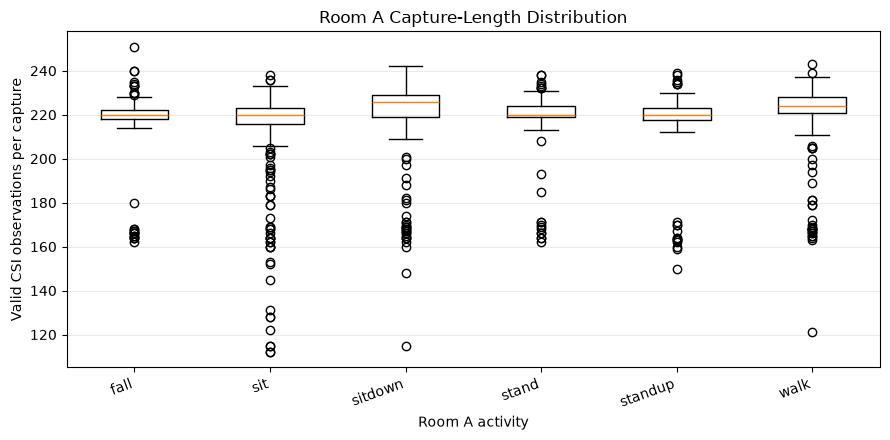

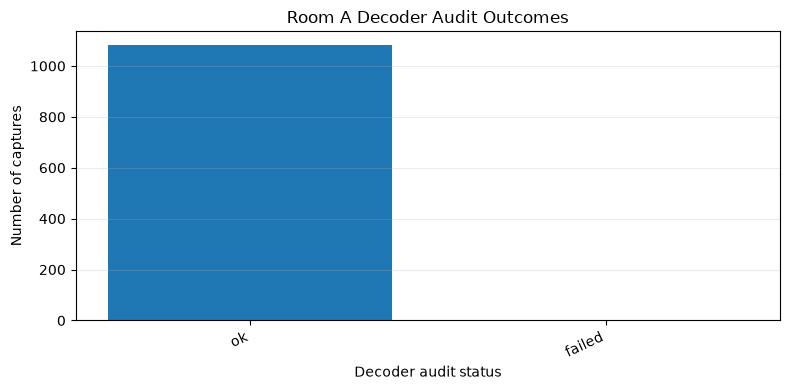


Final audit checks
Total PCAP members: 1084
Audit rows: 1084
Unknown activity paths: 0
Captures with zero valid observations: 2
Captures not marked 'ok': 2
Audit CSV: D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_a_quality_audit.csv


In [ ]:
# ============================================================
# 7.3 Room A Audit Visualizations
# ============================================================

activity_order = [
    "fall", "sit", "sitdown", "stand", "standup", "walk"
]

# Observation count distribution by activity
row_groups = [
    room_a_audit.loc[
        (room_a_audit["activity"] == activity)
        & (room_a_audit["observations"] > 0),
        "observations"
    ].to_numpy()
    for activity in activity_order
]

plt.figure(figsize=(9, 4.5))
plt.boxplot(
    row_groups,
    tick_labels=activity_order,
    showfliers=True
)
plt.xlabel("Room A activity")
plt.ylabel("Valid CSI observations per capture")
plt.title("Room A Capture-Length Distribution")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Decoder outcome counts
status_counts = room_a_audit["decode_status"].value_counts()

plt.figure(figsize=(8, 4))
plt.bar(status_counts.index, status_counts.values)
plt.xlabel("Decoder audit status")
plt.ylabel("Number of captures")
plt.title("Room A Decoder Audit Outcomes")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Final checks
print("\nFinal audit checks")
print("Total PCAP members:", len(pcap_members))
print("Audit rows:", len(room_a_audit))
print("Unknown activity paths:",
      (room_a_audit["activity"] == "unknown").sum())
print("Captures with zero valid observations:",
      (room_a_audit["observations"] == 0).sum())
print("Captures not marked 'ok':",
      (room_a_audit["decode_status"] != "ok").sum())
print("Audit CSV:", audit_path)

## 7.a Export Room A PCAPs to intermediate amplitude CSVs
Room A starts as raw PCAP, so each successfully decoded capture is converted to a 256-column amplitude CSV using the project's Python decoder. Files are saved under the matching development or validation folder. Captures that failed the earlier decoder audit are recorded as excluded; they are not silently included.

The manifest preserves the original archive member and the exact intermediate file path for provenance. This is the only Room A PCAP-to-CSV export stage; Section 8 consumes these CSVs and must not decode the PCAPs again.

In [ ]:
# ============================================================
# 7.4 Export Room A Decoded Amplitude CSVs
# ============================================================

from hashlib import sha1
from zipfile import ZipFile

ROOM_A_CSV_MANIFEST = OUTPUT_DIR / "room_a_intermediate_csv_manifest.csv"
COMMON_COLUMNS = [f"subcarrier_{i:03d}" for i in range(1, 257)]

assert EXPERIMENT_2_ZIP.is_file(), f"Room A archive not found: {EXPERIMENT_2_ZIP}"
assert "room_a_audit" in globals(), "Run the full Room A capture audit first."

room_a_export_rows = []
successful_audit = room_a_audit.loc[
    room_a_audit["decode_status"] == "ok"
].copy()

for _, row in successful_audit.iterrows():
    source_member = row["capture_path"]
    activity = str(row["activity"]).lower()
    split = str(row["split"])
    output_dir = ROOM_A_VAL_DIR if split == "validation" else ROOM_A_DEV_DIR
    # Hash the archive member to avoid filename collisions while retaining provenance in the manifest.
    member_hash = sha1(source_member.encode("utf-8")).hexdigest()[:10]
    output_path = output_dir / f"{activity}__{Path(source_member).stem}__{member_hash}.csv"

    record = {
        "capture_path": source_member,
        "activity": activity,
        "split": split,
        "intermediate_csv_path": str(output_path.relative_to(INTERMEDIATE_DIR)),
        "status": "failed",
        "error": None,
    }

    try:
        _, amplitudes = read_room_a_capture(
            str(EXPERIMENT_2_ZIP),
            source_member,
            expected_subcarriers=256,
            keep_zero_observations=False,
        )
        amplitudes = np.asarray(amplitudes, dtype=np.float32)

        if amplitudes.ndim != 2 or amplitudes.shape[1] != 256:
            raise ValueError(f"Expected N x 256 amplitude matrix, got {amplitudes.shape}")
        if amplitudes.shape[0] == 0:
            raise ValueError("No valid CSI observations")
        if not np.isfinite(amplitudes).all():
            raise ValueError("Non-finite amplitude values found")

        pd.DataFrame(amplitudes, columns=COMMON_COLUMNS).to_csv(
            output_path, index=False
        )
        record["status"] = "ok"

    except Exception as exc:
        record["error"] = f"{type(exc).__name__}: {exc}"

    room_a_export_rows.append(record)

room_a_intermediate_manifest = pd.DataFrame(room_a_export_rows)
room_a_intermediate_manifest.to_csv(ROOM_A_CSV_MANIFEST, index=False)

print("Room A intermediate CSV export")
print("------------------------------")
display(room_a_intermediate_manifest["status"].value_counts().rename_axis("status").to_frame("captures"))
print("Successful source decodes:", len(successful_audit))
print("CSV files written:", int((room_a_intermediate_manifest["status"] == "ok").sum()))
print("CSV manifest:", ROOM_A_CSV_MANIFEST)
print("Room A development CSV count:", len(list(ROOM_A_DEV_DIR.glob("*.csv"))))
print("Room A validation CSV count:", len(list(ROOM_A_VAL_DIR.glob("*.csv"))))

assert (room_a_intermediate_manifest["status"] == "ok").all(), (
    "One or more audited Room A captures failed CSV export; inspect the manifest."
)
assert not room_a_intermediate_manifest["capture_path"].duplicated().any()
print("Room A intermediate export checks passed.")

Room A intermediate CSV export
------------------------------


,captures
status,
ok,1082


Successful source decodes: 1082
CSV files written: 1082
CSV manifest: D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_a_intermediate_csv_manifest.csv
Room A development CSV count: 932
Room A validation CSV count: 150
Room A intermediate export checks passed.


## 8. Fixed-Window Extraction for Room A

**This section does not decode PCAP files.** Room A PCAP decoding and CSV export happen once in Section 7.a. Here we read those already-exported amplitude CSVs from `Intermediate_CSV/room_A/development/` and `Intermediate_CSV/room_A/validation/`.

Each CSV contains 256 subcarrier amplitude columns. We extract non-overlapping windows of 150 consecutive CSI observations from each capture, preserving capture identity, activity, and development/validation assignment. Captures with fewer than 150 observations produce no complete window. The resulting arrays, metadata, and extraction audit are saved under `App/results/`, and integrity checks verify dimensions, numerical validity, and capture-level separation between splits.


### 8.1 — Verify exported Room A CSVs and capture metadata

The decoder is not called in Section 8. This step joins the existing Section 7.a export manifest with the earlier capture audit, then verifies that each successful manifest entry points to an existing intermediate CSV.


In [ ]:
# ============================================================
# 8.1 Prepare for Room A Window Extraction from Intermediate CSVs
# ============================================================

import numpy as np
import pandas as pd

required_columns = [
    "capture_path", "activity", "split", "decode_status", "observations"
]
missing_columns = [column for column in required_columns if column not in room_a_audit.columns]
assert not missing_columns, f"Missing columns in Room A audit: {missing_columns}"
assert ROOM_A_CSV_MANIFEST.is_file(), (
    f"Room A intermediate CSV manifest not found: {ROOM_A_CSV_MANIFEST}. "
    "Run Section 7.4 first."
)

room_a_csv_manifest = pd.read_csv(ROOM_A_CSV_MANIFEST)
room_a_successful = room_a_audit.loc[
    room_a_audit["decode_status"] == "ok", required_columns
].copy()

room_a_successful = room_a_successful.merge(
    room_a_csv_manifest[["capture_path", "intermediate_csv_path", "status"]],
    on="capture_path",
    how="left",
    validate="one_to_one",
)
room_a_successful = room_a_successful.loc[
    room_a_successful["status"] == "ok"
].copy()

room_a_failed = room_a_audit.loc[
    room_a_audit["decode_status"] != "ok",
    required_columns + ["error"],
].copy()

print("Room A intermediate-CSV preparation")
print("-----------------------------------")
print(f"Audited captures                 : {len(room_a_audit)}")
print(f"Successfully decoded captures    : {(room_a_audit['decode_status'] == 'ok').sum()}")
print(f"Successful intermediate CSVs     : {len(room_a_successful)}")
print(f"Failed source captures excluded  : {len(room_a_failed)}")
print(f"Window length                    : 150 observations")
print(f"Subcarriers per observation      : 256")
assert room_a_successful["intermediate_csv_path"].notna().all()
missing_csvs = [
    path for path in room_a_successful["intermediate_csv_path"].astype(str)
    if not Path(INTERMEDIATE_DIR / path).is_file()
]
assert not missing_csvs, (
    f"{len(missing_csvs)} Room A intermediate CSV file(s) are missing. "
    f"Example: {missing_csvs[:3]}. Re-run Section 7.4 only if the exports "
    "need to be created or repaired."
)
print("Verified that all successful Room A manifest paths exist.")
assert room_a_successful["intermediate_csv_path"].map(lambda p: Path(INTERMEDIATE_DIR / p).is_file()).all()


Room A intermediate-CSV preparation
-----------------------------------
Audited captures                 : 1084
Successfully decoded captures    : 1082
Successful intermediate CSVs     : 1082
Failed source captures excluded  : 2
Window length                    : 150 observations
Subcarriers per observation      : 256
Verified that all successful Room A manifest paths exist.


### 8.2 — Extract fixed-length windows

In [ ]:
# ============================================================
# 8.2 Extract Room A Fixed-Length Windows
# ============================================================

from pathlib import PurePosixPath
import numpy as np
import pandas as pd

WINDOW_LENGTH = 150
EXPECTED_SUBCARRIERS = 256

window_arrays = []
window_metadata = []
capture_window_rows = []

for _, row in room_a_successful.iterrows():
    member_path = row["capture_path"]
    intermediate_csv_path = row["intermediate_csv_path"]

    try:
        intermediate_csv_complete_path = Path(INTERMEDIATE_DIR / intermediate_csv_path)
        amplitudes_frame = pd.read_csv(intermediate_csv_complete_path)
        amplitudes = amplitudes_frame.to_numpy(dtype=np.float32)

        if amplitudes.ndim != 2 or amplitudes.shape[1] != EXPECTED_SUBCARRIERS:
            raise ValueError(
                f"Unexpected amplitude shape: {amplitudes.shape}"
            )

        if not np.isfinite(amplitudes).all():
            raise ValueError("Non-finite amplitude values found")

        n_observations = amplitudes.shape[0]
        n_windows = n_observations // WINDOW_LENGTH

        capture_window_rows.append({
            "capture_path": member_path,
            "activity": row["activity"],
            "split": row["split"],
            "intermediate_csv_path": intermediate_csv_path,
            "observations": n_observations,
            "windows_extracted": n_windows,
            "discarded_observations": n_observations % WINDOW_LENGTH,
            "status": "ok" if n_windows > 0 else "fewer_than_150_observations",
            "error": None,
        })

        for window_index in range(n_windows):
            start = window_index * WINDOW_LENGTH
            end = start + WINDOW_LENGTH
            window = amplitudes[start:end]

            # Defensive check: never save a malformed window.
            if window.shape != (WINDOW_LENGTH, EXPECTED_SUBCARRIERS):
                raise ValueError(f"Unexpected window shape: {window.shape}")

            window_arrays.append(window)
            window_metadata.append({
                "window_id": len(window_metadata),
                "capture_path": member_path,
                "activity": row["activity"],
                "split": row["split"],
                "intermediate_csv_path": intermediate_csv_path,
                "window_index": window_index,
                "start_observation": start,
                "end_observation_exclusive": end,
            })

    except Exception as exc:
        capture_window_rows.append({
            "capture_path": member_path,
            "activity": row["activity"],
            "split": row["split"],
            "intermediate_csv_path": intermediate_csv_path,
            "observations": np.nan,
            "windows_extracted": 0,
            "discarded_observations": np.nan,
            "status": "extraction_failed",
            "error": f"{type(exc).__name__}: {exc}",
        })

# Assemble arrays and metadata.
if window_arrays:
    X_room_a = np.stack(window_arrays).astype(np.float32, copy=False)
else:
    X_room_a = np.empty(
        (0, WINDOW_LENGTH, EXPECTED_SUBCARRIERS),
        dtype=np.float32,
    )

room_a_window_metadata = pd.DataFrame(window_metadata)
room_a_capture_window_audit = pd.DataFrame(capture_window_rows)

# Save the arrays and metadata.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.save(OUTPUT_DIR / "X_room_a.npy", X_room_a)
room_a_window_metadata.to_csv(
    OUTPUT_DIR / "room_a_window_metadata.csv",
    index=False,
)
room_a_capture_window_audit.to_csv(
    OUTPUT_DIR / "room_a_capture_window_audit.csv",
    index=False,
)

print("Room A window extraction complete")
print("---------------------------------")
print("Window array shape:", X_room_a.shape)
print("Data type:", X_room_a.dtype)
print("Metadata rows:", len(room_a_window_metadata))
print("Capture audit rows:", len(room_a_audit))
print("All windows finite:", bool(np.isfinite(X_room_a).all()))
print("\nCapture extraction statuses:")
display(
    room_a_capture_window_audit["status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .to_frame("captures")
)

print("\nWindows by activity and split:")
display(
    room_a_window_metadata
    .groupby(["activity", "split"])
    .size()
    .unstack(fill_value=0)
)

print("\nSaved files:")
print(OUTPUT_DIR / "X_room_a.npy")
print(OUTPUT_DIR / "room_a_window_metadata.csv")
print(OUTPUT_DIR / "room_a_capture_window_audit.csv")

Room A window extraction complete
---------------------------------
Window array shape: (1070, 150, 256)
Data type: float32
Metadata rows: 1070
Capture audit rows: 1084
All windows finite: True

Capture extraction statuses:


,captures
status,
ok,1070
fewer_than_150_observations,12



Windows by activity and split:


split,development,validation
activity,,
fall,177,25
sit,169,23
sitdown,153,25
stand,115,25
standup,155,25
walk,154,24



Saved files:
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\X_room_a.npy
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_a_window_metadata.csv
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_a_capture_window_audit.csv


**Observation**
The class distribution is somewhat imbalanced in development, particularly for stand (115 windows), while validation has 23–25 windows per activity.

### 8.3 — Validate the extraction audit
The above output reports 1,070 captures with status ok, even though the total is 1,082 successfully decoded captures. The status counts are actually counting capture-audit rows, not windows. Also, the validation window counts are lower than the original validation capture counts for sit and walk. That can be legitimate if some captures have fewer than 150 usable observations, but we should verify the counts and audit before proceeding.

In [ ]:
# ============================================================
# 8.3 Validate Room A Window Extraction
# ============================================================

print("1. Capture audit status counts")
display(
    room_a_capture_window_audit["status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .to_frame("captures")
)

print("\n2. Capture audit status by activity and split")
display(
    pd.crosstab(
        [
            room_a_capture_window_audit["activity"],
            room_a_capture_window_audit["split"],
        ],
        room_a_capture_window_audit["status"],
        margins=True,
    )
)

print("\n3. Total windows by split")
display(
    room_a_window_metadata.groupby("split")
    .size()
    .rename("windows")
    .to_frame()
)

print("\n4. Captures that produced no windows")
no_window_captures = room_a_capture_window_audit[
    room_a_capture_window_audit["windows_extracted"] == 0
]
display(
    no_window_captures[
        [
            "capture_path",
            "activity",
            "split",
            "observations",
            "status",
            "error",
        ]
    ]
)

print("\n5. Integrity checks")
print("Successful captures in decoder audit:",
      int((room_a_audit["decode_status"] == "ok").sum()))
print("Rows in capture-window audit:",
      len(room_a_capture_window_audit))
print("Windows in X_room_a:", len(X_room_a))
print("Rows in window metadata:", len(room_a_window_metadata))
print("Unique source captures with windows:",
      room_a_window_metadata["capture_path"].nunique())
print("Duplicate window IDs:",
      int(room_a_window_metadata["window_id"].duplicated().sum()))
print("Duplicate capture/window-index pairs:",
      int(room_a_window_metadata.duplicated(
          ["capture_path", "window_index"]
      ).sum()))
print("All windows have shape (150, 256):",
      X_room_a.shape[1:] == (150, 256))
print("All window values finite:",
      bool(np.isfinite(X_room_a).all()))
print("Metadata rows match array length:",
      len(room_a_window_metadata) == len(X_room_a))

1. Capture audit status counts


,captures
status,
ok,1070
fewer_than_150_observations,12



2. Capture audit status by activity and split


status                fewer_than_150_observations    ok   All
activity split                                               
fall     development                            0   177   177
         validation                             0    25    25
sit      development                            7   169   176
         validation                             2    23    25
sitdown  development                            2   153   155
         validation                             0    25    25
stand    development                            0   115   115
         validation                             0    25    25
standup  development                            0   155   155
         validation                             0    25    25
walk     development                            0   154   154
         validation                             1    24    25
All                                            12  1070  1082


3. Total windows by split


,windows
split,
development,923
validation,147



4. Captures that produced no windows


,capture_path,activity,split,observations,status,error
191,Experiment-2/realdata/input_data/30ms/csidata/...,sit,development,115,fewer_than_150_observations,None
192,Experiment-2/realdata/input_data/30ms/csidata/...,sit,development,128,fewer_than_150_observations,None
201,Experiment-2/realdata/input_data/30ms/csidata/...,sit,development,115,fewer_than_150_observations,None
208,Experiment-2/realdata/input_data/30ms/csidata/...,sit,development,131,fewer_than_150_observations,None
212,Experiment-2/realdata/input_data/30ms/csidata/...,sit,development,122,fewer_than_150_observations,None
248,Experiment-2/realdata/input_data/30ms/csidata/...,sit,development,145,fewer_than_150_observations,None
305,Experiment-2/realdata/input_data/30ms/csidata/...,sit,development,112,fewer_than_150_observations,None
389,Experiment-2/realdata/input_data/30ms/csidata/...,sitdown,development,115,fewer_than_150_observations,None
408,Experiment-2/realdata/input_data/30ms/csidata/...,sitdown,development,148,fewer_than_150_observations,None
810,Experiment-2/realdata/input_data/30ms/csidata/...,sit,validation,128,fewer_than_150_observations,None



5. Integrity checks
Successful captures in decoder audit: 1082
Rows in capture-window audit: 1082
Windows in X_room_a: 1070
Rows in window metadata: 1070
Unique source captures with windows: 1070
Duplicate window IDs: 0
Duplicate capture/window-index pairs: 0
All windows have shape (150, 256): True
All window values finite: True
Metadata rows match array length: True


**Findings:**

The integrity checks pass. We have 1,070 valid Room A windows, with no duplicate window IDs, no non-finite values, and no capture leakage introduced by the extraction process.
There is one important consequence for evaluation: 3 validation captures produced no windows — 2 sit and 1 walk.

### 8.4 — Visualize the extracted windows

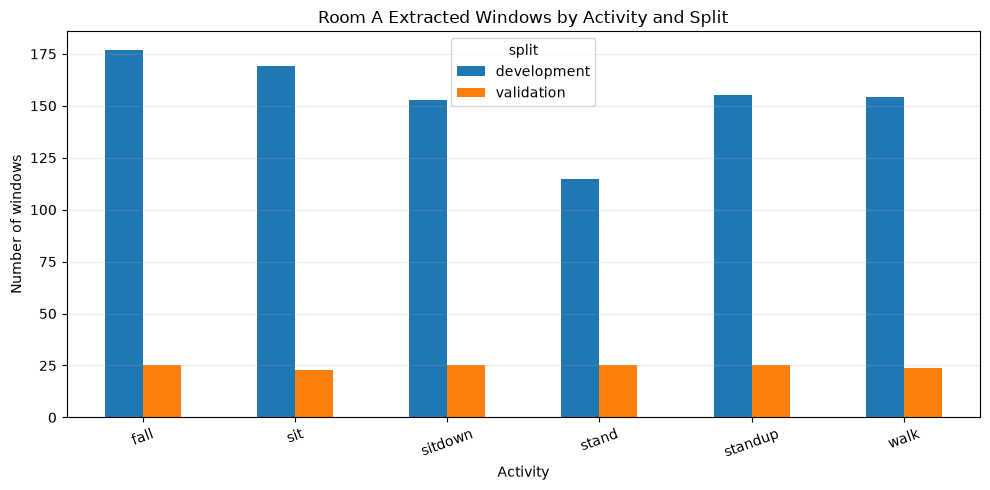

split,development,validation
activity,,
fall,177,25
sit,169,23
sitdown,153,25
stand,115,25
standup,155,25
walk,154,24


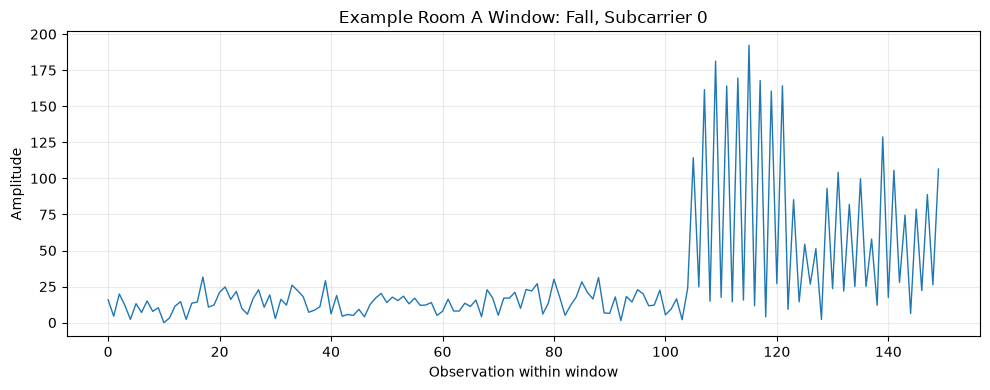

Example window index: 0
Source capture: Experiment-2/realdata/input_data/30ms/csidata/fall/fall10.pcap
Window shape: (150, 256)
Amplitude range: 0.0 to 2126.01904296875


In [ ]:
# ============================================================
# 8.4 Visualize Room A Extracted Windows
# ============================================================

import matplotlib.pyplot as plt

activity_order = ["fall", "sit", "sitdown", "stand", "standup", "walk"]
split_order = ["development", "validation"]

# 1. Plot the number of windows by activity and split.
window_counts = (
    room_a_window_metadata
    .groupby(["activity", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=activity_order, columns=split_order, fill_value=0)
)

ax = window_counts.plot(
    kind="bar",
    figsize=(10, 5),
)
ax.set_title("Room A Extracted Windows by Activity and Split")
ax.set_xlabel("Activity")
ax.set_ylabel("Number of windows")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(window_counts)

# 2. Plot one subcarrier from a representative window.
candidate_indices = np.flatnonzero(
    room_a_window_metadata["activity"].to_numpy() == "fall"
)
assert len(candidate_indices) > 0, "No fall windows available."

sample_idx = int(candidate_indices[0])
sample_window = X_room_a[sample_idx]

plt.figure(figsize=(10, 4))
plt.plot(sample_window[:, 0], linewidth=1)
plt.title("Example Room A Window: Fall, Subcarrier 0")
plt.xlabel("Observation within window")
plt.ylabel("Amplitude")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Example window index:", sample_idx)
print("Source capture:",
      room_a_window_metadata.iloc[sample_idx]["capture_path"])
print("Window shape:", sample_window.shape)
print("Amplitude range:",
      float(sample_window.min()), "to", float(sample_window.max()))

**Findings so far**

- 1,070 complete windows of shape (150, 256) were extracted.
- 923 windows belong to development captures and 147 to validation captures.
- Twelve successfully decoded captures contained fewer than 150 observations and therefore yielded no complete window.
- The two truncated PCAP captures remain excluded and documented.
- All extracted values are finite, and the window metadata matches the array.

### 8.5 — Prepare Room A labels and split arrays

In [ ]:
# ============================================================
# 8.5 Prepare Room A Labels and Split Indices
# ============================================================

from sklearn.preprocessing import LabelEncoder
import numpy as np
import pandas as pd

# Fixed class order for reproducible encoding.
activity_order = ["fall", "sit", "sitdown", "stand", "standup", "walk"]
label_to_id = {label: idx for idx, label in enumerate(activity_order)}
id_to_label = {idx: label for label, idx in label_to_id.items()}

# Encode activity labels in the same order as X_room_a.
y_room_a = room_a_window_metadata["activity"].map(label_to_id).to_numpy(dtype=np.int64)
split_room_a = room_a_window_metadata["split"].to_numpy()
capture_room_a = room_a_window_metadata["intermediate_csv_path"].to_numpy()

# Split indices refer to rows in X_room_a and its metadata.
train_idx_room_a = np.flatnonzero(split_room_a == "development")
val_idx_room_a = np.flatnonzero(split_room_a == "validation")

# Basic alignment and integrity checks.
assert len(X_room_a) == len(y_room_a) == len(split_room_a)
assert set(np.unique(y_room_a)).issubset(set(id_to_label))
assert set(np.unique(split_room_a)).issubset({"development", "validation"})
assert not (
    set(capture_room_a[train_idx_room_a])
    & set(capture_room_a[val_idx_room_a])
), "Capture leakage detected between development and validation."

label_mapping = pd.DataFrame({
    "activity": activity_order,
    "label_id": [label_to_id[label] for label in activity_order],
})

print("Room A label and split preparation")
print("----------------------------------")
print("X_room_a shape:", X_room_a.shape)
print("y_room_a shape:", y_room_a.shape)
print("Development windows:", len(train_idx_room_a))
print("Validation windows:", len(val_idx_room_a))
print("Activity label mapping:")
display(label_mapping)

print("\nWindow counts by encoded label and split:")
label_counts = room_a_window_metadata.copy()
label_counts["label_id"] = y_room_a
display(
    label_counts.groupby(["label_id", "activity", "split"])
    .size()
    .rename("windows")
    .reset_index()
)

# Save labels and the fixed class mapping.
np.save(OUTPUT_DIR / "room_a_labels.npy", y_room_a)
label_mapping.to_csv(OUTPUT_DIR / "room_a_label_mapping.csv", index=False)

print("\nSaved:")
print(OUTPUT_DIR / "room_a_labels.npy")
print(OUTPUT_DIR / "room_a_label_mapping.csv")
print("\nCapture-level split leakage check: passed")

Room A label and split preparation
----------------------------------
X_room_a shape: (1070, 150, 256)
y_room_a shape: (1070,)
Development windows: 923
Validation windows: 147
Activity label mapping:


,activity,label_id
0,fall,0
1,sit,1
2,sitdown,2
3,stand,3
4,standup,4
5,walk,5



Window counts by encoded label and split:


,label_id,activity,split,windows
0,0,fall,development,177
1,0,fall,validation,25
2,1,sit,development,169
3,1,sit,validation,23
4,2,sitdown,development,153
5,2,sitdown,validation,25
6,3,stand,development,115
7,3,stand,validation,25
8,4,standup,development,155
9,4,standup,validation,25



Saved:
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_a_labels.npy
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_a_label_mapping.csv

Capture-level split leakage check: passed


## 9. Fixed-Window Extraction for Room B

This section now reads Room B from `Intermediate_CSV/room_B/` rather than directly from the source archive. Each original CSV was assigned to development or validation at capture level in Section 5.2. We generate three non-overlapping `(150, 256)` windows from each 500-row capture, discarding the final 50 observations. All windows retain their original capture identity and split.

### 9.1 — Verify the Room B intermediate CSV manifest

This step checks the manifest produced during Section 5.2 and confirms that its CSV paths point to the prepared `Intermediate_CSV/room_B/development` and `validation` folders. It does not read the source ZIP archive. The archive is needed only in the earlier ingestion/export stage.


In [ ]:
# ============================================================
# 9.1 Verify Room B Intermediate CSV Manifest and Split
# ============================================================

import pandas as pd
from pathlib import Path

ROOM_B_CSV_MANIFEST = RESULTS_DIR / "room_b_intermediate_csv_manifest.csv"

assert ROOM_B_CSV_MANIFEST.is_file(), (
    f"Room B intermediate CSV manifest not found: {ROOM_B_CSV_MANIFEST}. "
    "Run Section 5.2 first to prepare Intermediate_CSV."
)

room_b_intermediate_manifest = pd.read_csv(ROOM_B_CSV_MANIFEST)
required_columns = {
    "capture_path", "activity", "split", "intermediate_csv_path", "status"
}
assert required_columns.issubset(room_b_intermediate_manifest.columns), (
    f"Manifest missing columns: {required_columns - set(room_b_intermediate_manifest.columns)}"
)
assert room_b_intermediate_manifest["capture_path"].is_unique, (
    "Duplicate source captures found in Room B manifest."
)
assert room_b_intermediate_manifest["intermediate_csv_path"].is_unique, (
    "Duplicate intermediate CSV files found in Room B manifest."
)
assert set(room_b_intermediate_manifest["split"]) == {"development", "validation"}
assert (room_b_intermediate_manifest["status"] == "ok").all(), (
    "Some Room B CSV exports failed; inspect the manifest before continuing."
)

# Verify each manifest path exists in the intermediate folder structure.
room_b_intermediate_manifest["intermediate_csv_path"] = (
    room_b_intermediate_manifest["intermediate_csv_path"].map(Path)
)
missing_paths = room_b_intermediate_manifest.loc[
    ~room_b_intermediate_manifest["intermediate_csv_path"].map(lambda p:  (INTERMEDIATE_DIR / Path(p)).is_file())
]
assert missing_paths.empty, (
    f"{len(missing_paths)} intermediate CSV files are missing. "
    "Inspect intermediate_csv_path in the manifest."
)

# Confirm that each CSV resides in the folder matching its assigned split.
for _, row in room_b_intermediate_manifest.iterrows():
    expected_dir = ROOM_B_DEV_DIR if row["split"] == "development" else ROOM_B_VAL_DIR
    csv_path = INTERMEDIATE_DIR / Path(row["intermediate_csv_path"])
    assert csv_path.parent.resolve() == expected_dir.resolve(), (
        f"Split/folder mismatch for {row['capture_path']}: {csv_path}"
    )

print("Room B intermediate CSV preparation")
print("-----------------------------------")
print("Manifest:", ROOM_B_CSV_MANIFEST)
print("Manifest rows:", len(room_b_intermediate_manifest))
print("Successful exports:", int((room_b_intermediate_manifest["status"] == "ok").sum()))
print("Development captures:", int((room_b_intermediate_manifest["split"] == "development").sum()))
print("Validation captures:", int((room_b_intermediate_manifest["split"] == "validation").sum()))
print("Development CSV files on disk:", len(list(ROOM_B_DEV_DIR.glob("*.csv"))))
print("Validation CSV files on disk:", len(list(ROOM_B_VAL_DIR.glob("*.csv"))))

print("\nActivity counts by split:")
display(pd.crosstab(room_b_intermediate_manifest["activity"], room_b_intermediate_manifest["split"], margins=True))

print("\nIntermediate CSV manifest checks passed; no ZIP access in this step.")


Room B intermediate CSV preparation
-----------------------------------
Manifest: D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_b_intermediate_csv_manifest.csv
Manifest rows: 1201
Successful exports: 1201
Development captures: 1076
Validation captures: 125
Development CSV files on disk: 1076
Validation CSV files on disk: 125

Activity counts by split:


split,development,validation,All
activity,,,
empty,242,25,267
lying,326,25,351
sitting,128,25,153
standing,196,25,221
walking,184,25,209
All,1076,125,1201



Intermediate CSV manifest checks passed; no ZIP access in this step.


### 9.2 — Inspect Room B CSV format from the intermediate folders

This step reads one development CSV per activity directly from `Intermediate_CSV/room_B/development`. It verifies the common 256-column amplitude schema and checks for non-numeric or non-finite values. No source ZIP is opened here.


In [ ]:
# ============================================================
# 9.2 Inspect Room B Intermediate CSV Format
# ============================================================

import pandas as pd
import numpy as np

# Select one development CSV per activity from the intermediate manifest.
room_b_examples = (
    room_b_intermediate_manifest[
        room_b_intermediate_manifest["split"] == "development"
    ]
    .sort_values("capture_path")
    .groupby("activity", as_index=False)
    .first()
)

assert len(room_b_examples) == 5, (
    f"Expected one example for each of five Room B activities; got {len(room_b_examples)}."
)

for _, row in room_b_examples.iterrows():
    csv_path = Path(INTERMEDIATE_DIR / Path(row["intermediate_csv_path"]))

    print("\n" + "=" * 70)
    print("Activity:", row["activity"])
    print("Source capture:", row["capture_path"])
    print("Intermediate CSV:", csv_path)

    sample_df = pd.read_csv(csv_path)
    print("CSV shape:", sample_df.shape)
    print("Columns (first 5):", sample_df.columns.tolist()[:5])
    display(sample_df.head(3))

    numeric_df = sample_df.apply(pd.to_numeric, errors="coerce")
    numeric_values = numeric_df.to_numpy(dtype=np.float64)
    print("Numeric shape:", numeric_df.shape)
    print("Non-numeric/missing cells:", int(numeric_df.isna().sum().sum()))
    print("Non-finite values:", int((~np.isfinite(numeric_values)).sum()))

    assert sample_df.shape[1] == 256, (
        f"Expected 256 subcarrier columns in {csv_path}; found {sample_df.shape[1]}"
    )
    assert numeric_df.notna().all().all(), f"Non-numeric/missing values in {csv_path}"
    assert np.isfinite(numeric_values).all(), f"Non-finite values in {csv_path}"

print("\nRoom B intermediate CSV format checks passed.")



Activity: empty
Source capture: Experiment-3/Data/Empty_11.csv
Intermediate CSV: D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\Intermediate_CSV\room_B\development\empty__Empty_11.csv
CSV shape: (500, 256)
Columns (first 5): ['subcarrier_001', 'subcarrier_002', 'subcarrier_003', 'subcarrier_004', 'subcarrier_005']


,subcarrier_001,subcarrier_002,subcarrier_003,subcarrier_004,subcarrier_005,subcarrier_006,subcarrier_007,subcarrier_008,subcarrier_009,subcarrier_010,...,subcarrier_247,subcarrier_248,subcarrier_249,subcarrier_250,subcarrier_251,subcarrier_252,subcarrier_253,subcarrier_254,subcarrier_255,subcarrier_256
0,140,18,69,28,133,210,238,202,67,120,...,91,286,536,583,428,168,83,247,298,33
1,51,46,156,100,57,27,15,21,74,154,...,488,488,478,464,447,429,402,376,349,30
2,225,54,270,104,35,159,242,283,192,46,...,355,600,577,316,58,387,533,455,186,55


Numeric shape: (500, 256)
Non-numeric/missing cells: 0
Non-finite values: 0

Activity: lying
Source capture: Experiment-3/Data/Lying_0.csv
Intermediate CSV: D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\Intermediate_CSV\room_B\development\lying__Lying_0.csv
CSV shape: (500, 256)
Columns (first 5): ['subcarrier_001', 'subcarrier_002', 'subcarrier_003', 'subcarrier_004', 'subcarrier_005']


,subcarrier_001,subcarrier_002,subcarrier_003,subcarrier_004,subcarrier_005,subcarrier_006,subcarrier_007,subcarrier_008,subcarrier_009,subcarrier_010,...,subcarrier_247,subcarrier_248,subcarrier_249,subcarrier_250,subcarrier_251,subcarrier_252,subcarrier_253,subcarrier_254,subcarrier_255,subcarrier_256
0,214,13,595,1217,1355,872,22,716,928,568,...,1318,703,21,481,557,415,254,304,516,14
1,330,79,402,957,1350,1423,1155,645,78,348,...,1397,1303,1033,671,342,172,157,302,482,109
2,126,143,1389,898,330,1286,1138,138,700,647,...,183,1104,1135,455,211,350,209,245,558,13


Numeric shape: (500, 256)
Non-numeric/missing cells: 0
Non-finite values: 0

Activity: sitting
Source capture: Experiment-3/Data/Sitting_0.csv
Intermediate CSV: D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\Intermediate_CSV\room_B\development\sitting__Sitting_0.csv
CSV shape: (500, 256)
Columns (first 5): ['subcarrier_001', 'subcarrier_002', 'subcarrier_003', 'subcarrier_004', 'subcarrier_005']


...

Numeric shape: (500, 256)
Non-numeric/missing cells: 0
Non-finite values: 0

Activity: standing
Source capture: Experiment-3/Data/Standing_0.csv
Intermediate CSV: D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\Intermediate_CSV\room_B\development\standing__Standing_0.csv
CSV shape: (500, 256)
Columns (first 5): ['subcarrier_001', 'subcarrier_002', 'subcarrier_003', 'subcarrier_004', 'subcarrier_005']


,subcarrier_001,subcarrier_002,subcarrier_003,subcarrier_004,subcarrier_005,subcarrier_006,subcarrier_007,subcarrier_008,subcarrier_009,subcarrier_010,...,subcarrier_247,subcarrier_248,subcarrier_249,subcarrier_250,subcarrier_251,subcarrier_252,subcarrier_253,subcarrier_254,subcarrier_255,subcarrier_256
0,59,41,249,195,692,1028,1062,814,420,173,...,1083,854,354,213,697,995,914,653,250,23
1,6,3,676,585,463,313,144,31,204,369,...,583,443,288,117,55,231,386,528,643,19
2,131,256,182,58,555,943,772,126,1079,5,...,693,1129,102,525,75,549,92,142,82,691


Numeric shape: (500, 256)
Non-numeric/missing cells: 0
Non-finite values: 0

Activity: walking
Source capture: Experiment-3/Data/Walking_0.csv
Intermediate CSV: D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\Intermediate_CSV\room_B\development\walking__Walking_0.csv
CSV shape: (500, 256)
Columns (first 5): ['subcarrier_001', 'subcarrier_002', 'subcarrier_003', 'subcarrier_004', 'subcarrier_005']


,subcarrier_001,subcarrier_002,subcarrier_003,subcarrier_004,subcarrier_005,subcarrier_006,subcarrier_007,subcarrier_008,subcarrier_009,subcarrier_010,...,subcarrier_247,subcarrier_248,subcarrier_249,subcarrier_250,subcarrier_251,subcarrier_252,subcarrier_253,subcarrier_254,subcarrier_255,subcarrier_256
0,118,41,765,953,1083,1118,1140,1082,998,852,...,1255,1293,1308,1240,1128,935,736,471,233,27
1,33,24,172,25,119,253,362,447,508,525,...,156,13,170,323,452,544,608,622,608,2
2,103,14,548,494,389,218,51,130,275,401,...,495,595,634,597,501,344,162,50,227,18


Numeric shape: (500, 256)
Non-numeric/missing cells: 0
Non-finite values: 0

Room B intermediate CSV format checks passed.


**Findings**

The inspection confirms that all five Room B activity types use the same format: 500 rows × 256 columns, with numeric values and no non-finite values in the five inspected examples. This matches the feature dimension used for Room A.

### 9.3 — Extract fixed-length windows from Room B
This step extracts fixed-length windows from Room B CSV recordings using 150 consecutive observations and 256 amplitude features per observation. Each eligible capture contributes non-overlapping windows, and every window retains its source capture, activity, and predefined split. Captures with invalid data or too few observations are recorded in an audit. The extraction preserves the existing capture-level development and validation assignments to avoid data leakage.

In [ ]:
# ============================================================
# 9.3 Extract Fixed-Length Windows from Room B Intermediate CSVs
# ============================================================

import numpy as np
import pandas as pd

WINDOW_LENGTH = 150
EXPECTED_SUBCARRIERS = 256

room_b_windows = []
room_b_window_rows = []
room_b_capture_rows = []

assert ROOM_B_CSV_MANIFEST.is_file(), (
    f"Room B intermediate CSV manifest not found: {ROOM_B_CSV_MANIFEST}. "
    "Run Section 5.2 first."
)
room_b_intermediate_manifest = pd.read_csv(ROOM_B_CSV_MANIFEST)

for capture_idx, row in room_b_intermediate_manifest.iterrows():
    member = row["capture_path"]
    activity = row["activity"]
    split = row["split"]
    intermediate_csv_path = row["intermediate_csv_path"]
    csv_path = INTERMEDIATE_DIR / Path(intermediate_csv_path)

    audit_row = {
        "capture_path": member,
        "activity": activity,
        "split": split,
        "observations": 0,
        "intermediate_csv_path": intermediate_csv_path,
        "windows_extracted": 0,
        "discarded_observations": 0,
        "status": "failed",
        "error": None,
    }

    try:
        if row["status"] != "ok" or not csv_path.is_file():
            raise FileNotFoundError(f"Intermediate CSV unavailable: {csv_path}")

        df = pd.read_csv(csv_path)
        if df.shape[1] != EXPECTED_SUBCARRIERS:
            raise ValueError(
                f"Expected {EXPECTED_SUBCARRIERS} columns, found {df.shape[1]}"
            )

        values = df.apply(pd.to_numeric, errors="raise").to_numpy(dtype=np.float32)
        if not np.isfinite(values).all():
            raise ValueError("CSV contains missing or non-finite amplitudes")

        n_observations = values.shape[0]
        n_windows = n_observations // WINDOW_LENGTH
        usable_observations = n_windows * WINDOW_LENGTH

        audit_row["observations"] = n_observations
        audit_row["windows_extracted"] = n_windows
        audit_row["discarded_observations"] = n_observations - usable_observations

        if n_windows == 0:
            audit_row["status"] = "fewer_than_150_observations"
        else:
            windows = values[:usable_observations].reshape(
                n_windows, WINDOW_LENGTH, EXPECTED_SUBCARRIERS
            )
            start_window_idx = len(room_b_windows)
            room_b_windows.extend(windows)

            for local_window_idx in range(n_windows):
                room_b_window_rows.append({
                    "window_id": start_window_idx + local_window_idx,
                    "capture_path": member,
                    "activity": activity,
                    "split": split,
                    "intermediate_csv_path": intermediate_csv_path,
                    "window_index": local_window_idx,
                    "start_observation": local_window_idx * WINDOW_LENGTH,
                    "end_observation_exclusive": (local_window_idx + 1) * WINDOW_LENGTH,
                })

            audit_row["status"] = "ok"

    except Exception as exc:
        audit_row["error"] = f"{type(exc).__name__}: {exc}"

    room_b_capture_rows.append(audit_row)

    if (len(room_b_capture_rows) % 100 == 0
            or len(room_b_capture_rows) == len(room_b_intermediate_manifest)):
        print(f"Processed {len(room_b_capture_rows)}/{len(room_b_intermediate_manifest)} Room B CSVs")

X_room_b = (
    np.stack(room_b_windows).astype(np.float32, copy=False)
    if room_b_windows
    else np.empty((0, WINDOW_LENGTH, EXPECTED_SUBCARRIERS), dtype=np.float32)
)
room_b_window_metadata = pd.DataFrame(room_b_window_rows)
room_b_capture_audit = pd.DataFrame(room_b_capture_rows)

np.save(OUTPUT_DIR / "X_room_b.npy", X_room_b)
room_b_window_metadata.to_csv(OUTPUT_DIR / "room_b_window_metadata.csv", index=False)
room_b_capture_audit.to_csv(OUTPUT_DIR / "room_b_capture_window_audit.csv", index=False)

print("\nRoom B window extraction complete")
print("----------------------------------")
print("Window array shape:", X_room_b.shape)
print("Data type:", X_room_b.dtype)
print("Metadata rows:", len(room_b_window_metadata))
print("Capture audit rows:", len(room_b_capture_audit))
print("All windows finite:", bool(np.isfinite(X_room_b).all()))

print("\nCapture extraction statuses:")
display(room_b_capture_audit["status"].value_counts(dropna=False).rename_axis("status").to_frame("captures"))

print("\nWindows by activity and split:")
display(room_b_window_metadata.groupby(["activity", "split"]).size().unstack(fill_value=0))

print("\nSaved files:")
print(OUTPUT_DIR / "X_room_b.npy")
print(OUTPUT_DIR / "room_b_window_metadata.csv")
print(OUTPUT_DIR / "room_b_capture_window_audit.csv")


Processed 100/1201 Room B CSVs
Processed 200/1201 Room B CSVs
Processed 300/1201 Room B CSVs
Processed 400/1201 Room B CSVs
Processed 500/1201 Room B CSVs
Processed 600/1201 Room B CSVs
Processed 700/1201 Room B CSVs
Processed 800/1201 Room B CSVs
Processed 900/1201 Room B CSVs
Processed 1000/1201 Room B CSVs
Processed 1100/1201 Room B CSVs
Processed 1200/1201 Room B CSVs
Processed 1201/1201 Room B CSVs

Room B window extraction complete
----------------------------------
Window array shape: (3603, 150, 256)
Data type: float32
Metadata rows: 3603
Capture audit rows: 1201
All windows finite: True

Capture extraction statuses:


,captures
status,
ok,1201



Windows by activity and split:


split,development,validation
activity,,
empty,726,75
lying,978,75
sitting,384,75
standing,588,75
walking,552,75



Saved files:
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\X_room_b.npy
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_b_window_metadata.csv
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_b_capture_window_audit.csv


### 9.4 — Validate Room B window integrity
This step verifies the integrity of the extracted Room B windows and their metadata. It checks array dimensions, numerical validity, unique window identifiers, and consistency between each window's source capture and its assigned split. It also confirms that no capture appears in both development and validation and that the expected three windows per capture were extracted.

In [ ]:
# ============================================================
# 9.4 Validate Room B Window Integrity
# ============================================================

import numpy as np
import pandas as pd

# 1. Array and metadata checks
assert X_room_b.ndim == 3
assert X_room_b.shape[1:] == (150, 256)
assert X_room_b.dtype == np.float32
assert len(X_room_b) == len(room_b_window_metadata)
assert np.isfinite(X_room_b).all()

assert room_b_window_metadata["window_id"].is_unique, (
    "Duplicate window IDs found."
)

assert not room_b_window_metadata[
    ["capture_path", "activity", "split", "window_index"]
].isna().any().any(), "Missing window metadata found."

# 2. Every extracted capture must retain its manifest assignment.
manifest_check = room_b_window_metadata.merge(
    room_b_intermediate_manifest[
        ["capture_path", "activity", "split"]
    ],
    on="capture_path",
    how="left",
    suffixes=("_window", "_manifest"),
    validate="many_to_one",
    indicator=True,
)

assert (manifest_check["_merge"] == "both").all(), (
    "Some window source captures are missing from the split manifest."
)
assert (
    manifest_check["activity_window"]
    == manifest_check["activity_manifest"]
).all(), "Activity mismatch between window metadata and manifest."
assert (
    manifest_check["split_window"]
    == manifest_check["split_manifest"]
).all(), "Split mismatch between window metadata and manifest."

# 3. No capture may occur in both splits.
capture_split_counts = (
    room_b_window_metadata.groupby("capture_path")["split"].nunique()
)
assert (capture_split_counts == 1).all(), (
    "Capture-level split leakage detected."
)

# 4. Confirm three windows per capture.
windows_per_capture = room_b_window_metadata.groupby("capture_path").size()
assert (windows_per_capture == 3).all(), (
    "At least one capture did not produce exactly three windows."
)

# 5. Check window indexes and observation ranges.
for capture_path, group in room_b_window_metadata.groupby("capture_path"):
    group = group.sort_values("window_index")
    assert group["window_index"].tolist() == [0, 1, 2]
    assert group["start_observation"].tolist() == [0, 150, 300]
    assert group["end_observation_exclusive"].tolist() == [150, 300, 450]

print("Room B window integrity checks passed")
print("------------------------------------")
print("Array shape:", X_room_b.shape)
print("Window metadata rows:", len(room_b_window_metadata))
print("Unique source captures:", room_b_window_metadata["capture_path"].nunique())
print("Windows per capture:", sorted(windows_per_capture.unique().tolist()))
print("Duplicate window IDs:", room_b_window_metadata["window_id"].duplicated().sum())
print("Captures assigned to multiple splits:", int((capture_split_counts > 1).sum()))
print("All windows finite:", bool(np.isfinite(X_room_b).all()))

print("\nWindows by split:")
display(
    room_b_window_metadata["split"]
    .value_counts()
    .rename_axis("split")
    .to_frame("windows")
)

print("\nWindows by activity and split:")
display(
    room_b_window_metadata
    .groupby(["activity", "split"])
    .size()
    .unstack(fill_value=0)
)

Room B window integrity checks passed
------------------------------------
Array shape: (3603, 150, 256)
Window metadata rows: 3603
Unique source captures: 1201
Windows per capture: [3]
Duplicate window IDs: 0
Captures assigned to multiple splits: 0
All windows finite: True

Windows by split:


,windows
split,
development,3228
validation,375



Windows by activity and split:


split,development,validation
activity,,
empty,726,75
lying,978,75
sitting,384,75
standing,588,75
walking,552,75


### 9.5 — Prepare Room B labels
This step encodes Room B activity labels into integer IDs and creates development and validation indices aligned with the extracted window array. We use a fixed label mapping for reproducibility and retain the source-capture metadata for future leakage checks. Room B labels remain distinct from Room A labels at this stage because the rooms have different activity categories; the shared and room-exclusive activities will be mapped explicitly in the cross-room adaptation stage.

In [ ]:
# ============================================================
# 9.5 Prepare Room B Labels and Split Indices
# ============================================================

import numpy as np
import pandas as pd

# Fixed Room B class order for reproducible encoding.
room_b_activity_order = [
    "empty",
    "lying",
    "sitting",
    "standing",
    "walking",
]

room_b_label_to_id = {
    label: idx
    for idx, label in enumerate(room_b_activity_order)
}
room_b_id_to_label = {
    idx: label
    for label, idx in room_b_label_to_id.items()
}

# Encode labels in the same row order as X_room_b.
y_room_b = (
    room_b_window_metadata["activity"]
    .map(room_b_label_to_id)
    .to_numpy(dtype=np.int64)
)

split_room_b = room_b_window_metadata["split"].to_numpy()
capture_room_b = room_b_window_metadata["intermediate_csv_path"].to_numpy()

train_idx_room_b = np.flatnonzero(split_room_b == "development")
val_idx_room_b = np.flatnonzero(split_room_b == "validation")

# Integrity checks.
assert len(X_room_b) == len(y_room_b) == len(split_room_b)
assert not pd.isna(y_room_b).any(), "Unknown activity label found."
assert set(np.unique(y_room_b)) == set(room_b_id_to_label.keys())
assert set(np.unique(split_room_b)) == {"development", "validation"}

assert not (
    set(capture_room_b[train_idx_room_b])
    & set(capture_room_b[val_idx_room_b])
), "Capture-level split leakage detected."

# Create readable label mapping.
room_b_label_mapping = pd.DataFrame({
    "label_id": list(room_b_id_to_label.keys()),
    "activity": list(room_b_id_to_label.values()),
})

print("Room B label and split preparation")
print("----------------------------------")
print("X_room_b shape:", X_room_b.shape)
print("y_room_b shape:", y_room_b.shape)
print("Development windows:", len(train_idx_room_b))
print("Validation windows:", len(val_idx_room_b))

print("\nActivity label mapping:")
display(room_b_label_mapping)

print("\nWindow counts by label and split:")
room_b_counts = room_b_window_metadata.copy()
room_b_counts["label_id"] = y_room_b

display(
    room_b_counts
    .groupby(["label_id", "activity", "split"])
    .size()
    .rename("windows")
    .reset_index()
)

# Save label artifacts.
np.save(OUTPUT_DIR / "room_b_labels.npy", y_room_b)
room_b_label_mapping.to_csv(
    OUTPUT_DIR / "room_b_label_mapping.csv",
    index=False,
)

print("\nSaved:")
print(OUTPUT_DIR / "room_b_labels.npy")
print(OUTPUT_DIR / "room_b_label_mapping.csv")
print("\nCapture-level split leakage check: passed")

Room B label and split preparation
----------------------------------
X_room_b shape: (3603, 150, 256)
y_room_b shape: (3603,)
Development windows: 3228
Validation windows: 375

Activity label mapping:


,label_id,activity
0,0,empty
1,1,lying
2,2,sitting
3,3,standing
4,4,walking



Window counts by label and split:


,label_id,activity,split,windows
0,0,empty,development,726
1,0,empty,validation,75
2,1,lying,development,978
3,1,lying,validation,75
4,2,sitting,development,384
5,2,sitting,validation,75
6,3,standing,development,588
7,3,standing,validation,75
8,4,walking,development,552
9,4,walking,validation,75



Saved:
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_b_labels.npy
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\room_b_label_mapping.csv

Capture-level split leakage check: passed


## 10. Define Shared and Room-Exclusive Activities
This step establishes the activity correspondence between the two rooms for cross-room adaptation. It maps the shared activities to common labels (SIT, STAND, WALK) and identify the room-exclusive activities separately. It will keep the original room-specific labels intact and create explicit mappings for the adaptation experiments.

In [26]:
# ============================================================
#  10. Define Shared and Room-Exclusive Activities
# ============================================================

import pandas as pd

# Explicit mapping from each room's activity names to common
# semantic labels. Original labels and encoded arrays remain unchanged.

room_a_to_common = {
    "fall": "FALL",
    "sit": "SIT",
    "sitdown": "SITDOWN",
    "stand": "STAND",
    "standup": "STANDUP",
    "walk": "WALK",
}

room_b_to_common = {
    "empty": "EMPTY",
    "lying": "LYING",
    "sitting": "SIT",
    "standing": "STAND",
    "walking": "WALK",
}

shared_activities = ["SIT", "STAND", "WALK"]

room_a_exclusive = ["FALL", "SITDOWN", "STANDUP"]
room_b_exclusive = ["EMPTY", "LYING"]

# Build a readable correspondence table.
activity_correspondence = pd.DataFrame([
    {
        "room": "Room A",
        "original_activity": original,
        "common_activity": common,
        "group": (
            "shared" if common in shared_activities
            else "room-exclusive"
        ),
    }
    for original, common in room_a_to_common.items()
] + [
    {
        "room": "Room B",
        "original_activity": original,
        "common_activity": common,
        "group": (
            "shared" if common in shared_activities
            else "room-exclusive"
        ),
    }
    for original, common in room_b_to_common.items()
])

print("Cross-room activity correspondence")
print("----------------------------------")
display(activity_correspondence)

print("Shared activities:", shared_activities)
print("Room A exclusive activities:", room_a_exclusive)
print("Room B exclusive activities:", room_b_exclusive)

# Integrity checks: the three shared activities must exist in both rooms.
assert all(
    activity in room_a_to_common.values()
    for activity in shared_activities
)
assert all(
    activity in room_b_to_common.values()
    for activity in shared_activities
)

# Save the mapping for reproducibility.
activity_correspondence.to_csv(
    OUTPUT_DIR / "cross_room_activity_mapping.csv",
    index=False,
)

print("\nSaved:")
print(OUTPUT_DIR / "cross_room_activity_mapping.csv")
print("\nActivity correspondence checks: passed")

Cross-room activity correspondence
----------------------------------


,room,original_activity,common_activity,group
0,Room A,fall,FALL,room-exclusive
1,Room A,sit,SIT,shared
2,Room A,sitdown,SITDOWN,room-exclusive
3,Room A,stand,STAND,shared
4,Room A,standup,STANDUP,room-exclusive
5,Room A,walk,WALK,shared
6,Room B,empty,EMPTY,room-exclusive
7,Room B,lying,LYING,room-exclusive
8,Room B,sitting,SIT,shared
9,Room B,standing,STAND,shared


Shared activities: ['SIT', 'STAND', 'WALK']
Room A exclusive activities: ['FALL', 'SITDOWN', 'STANDUP']
Room B exclusive activities: ['EMPTY', 'LYING']

Saved:
C:\Users\offic\Downloads\WiQ\cross-room-few-shot-adaptation\App\results\cross_room_activity_mapping.csv

Activity correspondence checks: passed


## 11. Verify the Few-Shot Adaptation Protocol
This step specifies which target-room development captures can be used as labeled support examples for each value of `K`. Support examples must be selected at the original-capture level, shared target activities must not contribute labeled support, and validation captures must never be used for support or model fitting. We will use the fixed seed `42` so that the support sets are reproducible.

### 11.1 Define the adaptation protocol
Establish the source and target activity groups and the few-shot values before selecting any captures.

In [ ]:

# Step 11.1 — Configure cross-room few-shot adaptation

FEW_SHOT_VALUES = [1, 5, 10, 20]

SHARED_ACTIVITIES = ["SIT", "STAND", "WALK"]

ROOM_A_EXCLUSIVE_ACTIVITIES = ["FALL", "SITDOWN", "STANDUP"]
ROOM_B_EXCLUSIVE_ACTIVITIES = ["EMPTY", "LYING"]

ADAPTATION_DIRECTIONS = [
    ("Room A", "Room B"),  # Train on Room A, adapt/evaluate on Room B
    ("Room B", "Room A"),  # Train on Room B, adapt/evaluate on Room A
]

SUPPORT_RANDOM_SEED = 42

print("Few-shot adaptation configuration")
print("---------------------------------")
print("K values:", FEW_SHOT_VALUES)
print("Shared activities:", SHARED_ACTIVITIES)
print("Room A exclusive activities:", ROOM_A_EXCLUSIVE_ACTIVITIES)
print("Room B exclusive activities:", ROOM_B_EXCLUSIVE_ACTIVITIES)
print("Adaptation directions:", ADAPTATION_DIRECTIONS)
print("Support selection seed:", SUPPORT_RANDOM_SEED)


Few-shot adaptation configuration
---------------------------------
K values: [1, 5, 10, 20]
Shared activities: ['SIT', 'STAND', 'WALK']
Room A exclusive activities: ['FALL', 'SITDOWN', 'STANDUP']
Room B exclusive activities: ['EMPTY', 'LYING']
Adaptation directions: [('Room A', 'Room B'), ('Room B', 'Room A')]
Support selection seed: 42


### 11.2 — Inspect window metadata for capture-level support selection
Verify that the Room A and Room B window metadata contain the activity labels, development/validation split assignments, and original capture identifiers needed to construct few-shot support sets.

Few-shot adaptation must select `(K=1,5,10,20)` distinct development captures per target-exclusive activity. Since each capture may produce multiple windows, we must select captures first and then include their associated windows. Validation captures must never be selected for support.

In [ ]:
# Step 11.2 — Load and inspect metadata required for few-shot adaptation

import pandas as pd

# Load metadata from saved artifacts rather than relying on earlier cell variables.
ROOM_A_WINDOW_METADATA_PATH = RESULTS_DIR / "room_a_window_metadata.csv"
ROOM_B_WINDOW_METADATA_PATH = RESULTS_DIR / "room_b_window_metadata.csv"

metadata_objects = {
    "Room A": pd.read_csv(ROOM_A_WINDOW_METADATA_PATH),
    "Room B": pd.read_csv(ROOM_B_WINDOW_METADATA_PATH),
}

required_columns = {"activity", "split", "capture_path"}

for room_name, metadata in metadata_objects.items():
    print(f"\n{room_name} window metadata")
    print("-" * (len(room_name) + 18))
    print("Shape:", metadata.shape)
    print("Columns:", metadata.columns.tolist())

    missing_columns = required_columns - set(metadata.columns)
    if missing_columns:
        raise ValueError(
            f"{room_name} metadata is missing required columns: "
            f"{sorted(missing_columns)}"
        )

    if metadata[list(required_columns)].isna().any().any():
        raise ValueError(
            f"{room_name} metadata contains missing values in required columns."
        )

    print("\nWindows by split:")
    print(metadata["split"].value_counts(dropna=False).to_string())

    print("\nDistinct captures by split:")
    print(
        metadata.groupby("split")["capture_path"]
        .nunique()
        .to_string()
    )

    print("\nActivities:")
    print(sorted(metadata["activity"].dropna().unique().tolist()))

print("\nMetadata field checks: passed")


Room A window metadata
------------------------
Shape: (1070, 8)
Columns: ['window_id', 'capture_path', 'activity', 'split', 'intermediate_csv_path', 'window_index', 'start_observation', 'end_observation_exclusive']

Windows by split:
split
development    923
validation     147

Distinct captures by split:
split
development    923
validation     147

Activities:
['fall', 'sit', 'sitdown', 'stand', 'standup', 'walk']

Room B window metadata
------------------------
Shape: (3603, 8)
Columns: ['window_id', 'capture_path', 'activity', 'split', 'intermediate_csv_path', 'window_index', 'start_observation', 'end_observation_exclusive']

Windows by split:
split
development    3228
validation      375

Distinct captures by split:
split
development    1076
validation      125

Activities:
['empty', 'lying', 'sitting', 'standing', 'walking']

Metadata field checks: passed


**Findings:**
The output reveals one important detail we need to handle before selecting few-shot captures.
- Room A: 1,070 windows from 1,070 distinct captures.
- Room B: 3,603 windows from 1,201 distinct captures in total, with 1,076 development captures and 125 validation captures.

Room A has one window per retained capture, while Room B has three windows per capture. Therefore, we must select Room B support examples at the capture level and include all eligible windows from each selected capture.

### 11.3 — Verify development capture counts per activity
Description: Count distinct development captures for each original activity in both rooms and compare those counts with the required few-shot values \(K = 1, 5, 10, 20\).

Purpose: Confirm that every room-exclusive target activity has enough development captures for all four few-shot settings. We also check shared activities because they will be used for cross-room transfer.

In [ ]:

# Step 11.3 — Count distinct development captures per activity

for room_name, metadata in metadata_objects.items():
    print(f"\n{room_name}: development captures per activity")
    print("=" * 48)

    development = metadata.loc[
        metadata["split"].eq("development")
    ]

    capture_counts = (
        development.groupby("activity")["intermediate_csv_path"]
        .nunique()
        .sort_index()
    )

    print(capture_counts.to_string())

    insufficient = capture_counts[capture_counts < max(FEW_SHOT_VALUES)]

    if not insufficient.empty:
        print("\nWARNING: Activities with fewer than 20 development captures:")
        print(insufficient.to_string())
    else:
        print("\nAll activities have enough captures for K =", FEW_SHOT_VALUES)

print("\nDevelopment capture count inspection complete.")



Room A: development captures per activity
activity
fall       177
sit        169
sitdown    153
stand      115
standup    155
walk       154

All activities have enough captures for K = [1, 5, 10, 20]

Room B: development captures per activity
activity
empty       242
lying       326
sitting     128
standing    196
walking     184

All activities have enough captures for K = [1, 5, 10, 20]

Development capture count inspection complete.


### 11.4 — Create deterministic few-shot support-capture selections
Description: For each adaptation direction and each value of \(K\), select a reproducible set of distinct target-room development captures for the target-exclusive activities.

Purpose: Build the support sets used for few-shot adaptation while keeping validation captures completely separate. We’ll use seed 42 so the selections can be reproduced.

The selection rules are:
- Room A → Room B: select \(K\) Room B development captures for each target-exclusive activity: EMPTY and LYING.
- Room B → Room A: select \(K\) Room A development captures for each target-exclusive activity: FALL, SITDOWN, and STANDUP.
- Shared activities (SIT, STAND, WALK) remain part of the cross-room transfer protocol; they are not counted as target-exclusive support captures.
- Select captures, not windows. For Room B, all three windows from a selected capture will remain associated with that same capture.

In [ ]:

# Step 11.4 — Select deterministic target-exclusive support captures

import pandas as pd

support_selection_rows = []

direction_config = {
    ("Room A", "Room B"): {
        "metadata": metadata_objects["Room B"],
        "exclusive_activities": {
            "EMPTY": "empty",
            "LYING": "lying",
        },
    },
    ("Room B", "Room A"): {
        "metadata": metadata_objects["Room A"],
        "exclusive_activities": {
            "FALL": "fall",
            "SITDOWN": "sitdown",
            "STANDUP": "standup",
        },
    },
}

for direction_index, (source_room, target_room) in enumerate(
    ADAPTATION_DIRECTIONS
):
    config = direction_config[(source_room, target_room)]
    metadata = config["metadata"]

    development = metadata.loc[
        metadata["split"].eq("development"),
        ["intermediate_csv_path", "activity"],
    ].drop_duplicates()

    for common_activity, original_activity in (
        config["exclusive_activities"].items()
    ):
        candidates = (
            development.loc[
                development["activity"].eq(original_activity),
                "intermediate_csv_path",
            ]
            .drop_duplicates()
            .sort_values()
            .tolist()
        )

        if len(candidates) < max(FEW_SHOT_VALUES):
            raise ValueError(
                f"{target_room} activity {common_activity} has only "
                f"{len(candidates)} eligible development captures."
            )

        # One reproducible ordering per activity; smaller K sets are nested.
        rng = np.random.default_rng(
            SUPPORT_RANDOM_SEED + direction_index * 1000
            + list(config["exclusive_activities"]).index(common_activity)
        )
        shuffled_captures = rng.permutation(candidates).tolist()

        for k in FEW_SHOT_VALUES:
            for support_rank, capture_path in enumerate(
                shuffled_captures[:k], start=1
            ):
                support_selection_rows.append({
                    "source_room": source_room,
                    "target_room": target_room,
                    "common_activity": common_activity,
                    "original_activity": original_activity,
                    "K": k,
                    "support_rank": support_rank,
                    "intermediate_csv_path": capture_path,
                    "split": "development",
                })

support_capture_selection = pd.DataFrame(support_selection_rows)

print("Support capture selections")
print("--------------------------")
print("Rows:", len(support_capture_selection))
print(
    support_capture_selection.groupby(
        ["source_room", "target_room", "K", "common_activity"]
    )["intermediate_csv_path"].nunique().to_string()
)

assert support_capture_selection["split"].eq("development").all()

assert not support_capture_selection.duplicated(
    ["source_room", "target_room", "K", "common_activity", "intermediate_csv_path"]
).any()

print("\nSupport selection checks: passed")


Support capture selections
--------------------------
Rows: 180
source_room  target_room  K   common_activity
Room A       Room B       1   EMPTY               1
                              LYING               1
                          5   EMPTY               5
                              LYING               5
                          10  EMPTY              10
                              LYING              10
                          20  EMPTY              20
                              LYING              20
Room B       Room A       1   FALL                1
                              SITDOWN             1
                              STANDUP             1
                          5   FALL                5
                              SITDOWN             5
                              STANDUP             5
                          10  FALL               10
                              SITDOWN            10
                              STANDUP            10
      

### 11.5 — Validate and save the support-capture manifest
Description: Save the selected support captures to a CSV file and verify that the manifest contains exactly the required number of distinct captures per target-exclusive activity, with no validation captures included.

Purpose: Preserve the exact few-shot selections so future training and evaluation runs use the same support examples. The manifest records capture-level selections, not individual windows.

In [ ]:

# Step 11.5 — Validate and save the support-capture manifest

from pathlib import Path

# Use the results directory configured earlier in the notebook.
support_manifest_path = RESULTS_DIR / "few_shot_support_capture_manifest.csv"

# Verify the selected capture counts for every direction, K, and activity.
actual_counts = (
    support_capture_selection.groupby(
        ["source_room", "target_room", "K", "common_activity"]
    )["intermediate_csv_path"]
    .nunique()
)

expected_counts = []

for source_room, target_room in ADAPTATION_DIRECTIONS:
    config = direction_config[(source_room, target_room)]

    for k in FEW_SHOT_VALUES:
        for common_activity in config["exclusive_activities"]:
            expected_counts.append(
                (source_room, target_room, k, common_activity, k)
            )

for source_room, target_room, k, activity, expected in expected_counts:
    actual = actual_counts.loc[
        (source_room, target_room, k, activity)
    ]
    assert actual == expected, (
        f"Expected {expected} captures for "
        f"{source_room}->{target_room}, K={k}, activity={activity}; "
        f"found {actual}."
    )

# Check that each selected capture belongs to the corresponding target room's
# development metadata.
for (source_room, target_room), config in direction_config.items():
    target_metadata = config["metadata"]
    selected = support_capture_selection.loc[
        support_capture_selection["source_room"].eq(source_room)
        & support_capture_selection["target_room"].eq(target_room)
    ]

    development_paths = set(
        target_metadata.loc[
            target_metadata["split"].eq("development"),
            "intermediate_csv_path",
        ].unique()
    )

    assert set(selected["intermediate_csv_path"]).issubset(development_paths), (
        f"Non-development capture found in {source_room}->{target_room}."
    )

support_capture_selection.to_csv(support_manifest_path, index=False)

print("Support manifest saved:")
print(support_manifest_path)
print("Total manifest rows:", len(support_capture_selection))
print("Validation leakage check: passed")
print("Capture-count checks: passed")


Support manifest saved:
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\few_shot_support_capture_manifest.csv
Total manifest rows: 180
Validation leakage check: passed
Capture-count checks: passed


### 11.6 — Expand selected support captures into windows
Description: Link each selected support capture to its corresponding window rows in the Room A and Room B metadata, producing a window-level manifest for each few-shot setting.

Purpose: The support selection was performed at the capture level, as required. Now we map those selected captures to their windows so they can be used for model training. For Room B, this should include all three windows associated with each selected capture.

In [ ]:

# Step 11.6 — Expand selected support captures into window-level rows

window_metadata_by_room = {
    "Room A": metadata_objects["Room A"],
    "Room B": metadata_objects["Room B"],
}

support_window_parts = []

for (source_room, target_room), config in direction_config.items():
    target_metadata = window_metadata_by_room[target_room]

    selected_captures = support_capture_selection.loc[
        support_capture_selection["source_room"].eq(source_room)
        & support_capture_selection["target_room"].eq(target_room)
    ].copy()

    # Match selected captures to their window metadata.
    expanded = selected_captures.merge(
        target_metadata,
        on="intermediate_csv_path",
        how="left",
        suffixes=("_support", "_window"),
        validate="many_to_many",
    )

    if expanded["window_id"].isna().any():
        raise ValueError(
            f"Some selected captures could not be matched to windows "
            f"for {source_room}->{target_room}."
        )

    # Check that all selected windows belong to development data.
    if not expanded["split_window"].eq("development").all():
        raise ValueError(
            f"Non-development windows found in support set "
            f"for {source_room}->{target_room}."
        )

    # Verify that the window's original activity matches the selected one.
    if not expanded["activity"].eq(
        expanded["original_activity"]
    ).all():
        raise ValueError(
            f"Activity mismatch found in support windows "
            f"for {source_room}->{target_room}."
        )

    support_window_parts.append(expanded)

support_window_manifest = pd.concat(
    support_window_parts,
    ignore_index=True,
)

support_window_manifest_path = (
    RESULTS_DIR / "few_shot_support_window_manifest.csv"
)
support_window_manifest.to_csv(
    support_window_manifest_path,
    index=False,
)

print("Support window manifest saved:")
print(support_window_manifest_path)

print("\nNumber of windows by adaptation direction, K, and activity:")
print(
    support_window_manifest.groupby(
        ["source_room", "target_room", "K", "common_activity"]
    )["window_id"]
    .nunique()
    .to_string()
)

print("\nTotal window-manifest rows:", len(support_window_manifest))
print("Development-only check: passed")
print("Capture-to-window mapping checks: passed")


Support window manifest saved:
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\few_shot_support_window_manifest.csv

Number of windows by adaptation direction, K, and activity:
source_room  target_room  K   common_activity
Room A       Room B       1   EMPTY               3
                              LYING               3
                          5   EMPTY              15
                              LYING              15
                          10  EMPTY              30
                              LYING              30
                          20  EMPTY              60
                              LYING              60
Room B       Room A       1   FALL                1
                              SITDOWN             1
                              STANDUP             1
                          5   FALL                5
                              SITDOWN             5
                              STANDUP             5
                          

### 11.7 — Validate the support window manifest
Description: Verify that each adaptation direction and each value of \(K\) has the expected number of support captures and windows, that the selected support sets are nested as \(K\) increases, and that no validation captures are included.

Purpose: Catch support-set inconsistencies before using the manifest to build training datasets. Remember, Room B has three windows per capture, while Room A has one.

In [ ]:
# Step 11.7 — Validate few-shot support window manifest

# 1. Check expected total row count
assert len(support_window_manifest) == 324

# 2. Check each support set has the expected number of distinct captures
for (source_room, target_room, k, activity), group in (
    support_window_manifest.groupby(
        ["source_room", "target_room", "K", "common_activity"]
    )
):
    expected_captures = k

    actual_captures = group["intermediate_csv_path"].nunique()

    assert actual_captures == expected_captures, (
        f"Unexpected capture count for "
        f"{source_room}->{target_room}, K={k}, "
        f"{activity}: expected {expected_captures}, "
        f"got {actual_captures}"
    )

# 3. Check expected windows per activity
for (source_room, target_room, k, activity), group in (
    support_window_manifest.groupby(
        ["source_room", "target_room", "K", "common_activity"]
    )
):
    windows_per_capture = 3 if target_room == "Room B" else 1
    expected_windows = k * windows_per_capture

    actual_windows = group["window_id"].nunique()

    assert actual_windows == expected_windows, (
        f"Unexpected window count for "
        f"{source_room}->{target_room}, K={k}, "
        f"{activity}: expected {expected_windows}, "
        f"got {actual_windows}"
    )

# 4. Check nested support sets: K=1 ⊆ K=5 ⊆ K=10 ⊆ K=20
for (source_room, target_room, activity), group in (
    support_capture_selection.groupby(
        ["source_room", "target_room", "common_activity"]
    )
):
    captures_by_k = {
        k: set(
            group.loc[group["K"].eq(k), "intermediate_csv_path"]
        )
        for k in FEW_SHOT_VALUES
    }

    for smaller_k, larger_k in zip(FEW_SHOT_VALUES[:-1], FEW_SHOT_VALUES[1:]):
        assert captures_by_k[smaller_k].issubset(
            captures_by_k[larger_k]
        ), (
            f"Support sets are not nested for "
            f"{source_room}->{target_room}, {activity}: "
            f"K={smaller_k} is not a subset of K={larger_k}"
        )

# 5. Ensure all support rows are development-only
assert support_window_manifest["split_window"].eq("development").all()
assert support_window_manifest["split_support"].eq("development").all()

print("Support manifest row count: 324")
print("Capture counts for every direction, K, and activity: passed")
print("Expected window counts: passed")
print("Nested few-shot support sets: passed")
print("Validation leakage check: passed")
print("Step 11.7 complete.")

Support manifest row count: 324
Capture counts for every direction, K, and activity: passed
Expected window counts: passed
Nested few-shot support sets: passed
Validation leakage check: passed
Step 11.7 complete.


### 11.8 — Create the few-shot support dataset manifest
Description: Create a clean, standardized manifest that identifies the support windows and their training labels for each adaptation direction and each \(K\).

Purpose: The support manifest currently stores both the original room activity and the common activity label. We’ll explicitly define the label that the model should learn, while keeping the original activity for traceability. We will not load or modify the CSI arrays yet.

In [ ]:
# Step 11.8 — Prepare standardized few-shot support dataset manifest

few_shot_support_manifest = support_window_manifest.copy()

# The common activity name is the model's target label.
few_shot_support_manifest["target_label"] = (
    few_shot_support_manifest["common_activity"]
)

# Keep the source and target room explicit.
few_shot_support_manifest["adaptation_direction"] = (
    few_shot_support_manifest["source_room"]
    + " -> "
    + few_shot_support_manifest["target_room"]
)

# Retain only the fields needed to trace and construct support datasets.
support_manifest_columns = [
    "adaptation_direction",
    "source_room",
    "target_room",
    "K",
    "common_activity",
    "target_label",
    "original_activity",
    "intermediate_csv_path",
    "window_id",
    "window_index",
    "start_observation",
    "end_observation_exclusive",
    "split_support",
    "split_window",
]

few_shot_support_manifest = few_shot_support_manifest[
    support_manifest_columns
].copy()

# Confirm the model label matches the standardized common activity.
assert few_shot_support_manifest["target_label"].equals(
    few_shot_support_manifest["common_activity"]
)

assert few_shot_support_manifest["split_support"].eq("development").all()
assert few_shot_support_manifest["split_window"].eq("development").all()
assert len(few_shot_support_manifest) == 324

few_shot_support_manifest_path = (
    RESULTS_DIR / "few_shot_support_dataset_manifest.csv"
)

few_shot_support_manifest.to_csv(
    few_shot_support_manifest_path,
    index=False,
)

print("Few-shot support dataset manifest saved:")
print(few_shot_support_manifest_path)

print("\nRows by adaptation direction and K:")
print(
    few_shot_support_manifest.groupby(
        ["adaptation_direction", "K"]
    ).size().to_string()
)

print("\nTarget labels:")
print(
    sorted(few_shot_support_manifest["target_label"].unique().tolist())
)

print("\nTotal rows:", len(few_shot_support_manifest))
print("Development-only checks: passed")
print("Target-label consistency check: passed")
print("Step 11.8 complete.")

Few-shot support dataset manifest saved:
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\few_shot_support_dataset_manifest.csv

Rows by adaptation direction and K:
adaptation_direction  K 
Room A -> Room B      1       6
                      5      30
                      10     60
                      20    120
Room B -> Room A      1       3
                      5      15
                      10     30
                      20     60

Target labels:
['EMPTY', 'FALL', 'LYING', 'SITDOWN', 'STANDUP']

Total rows: 324
Development-only checks: passed
Target-label consistency check: passed
Step 11.8 complete.


### 11.9 — Verify support label coverage
Description: Check that each adaptation direction includes exactly the expected target-exclusive classes and that the shared activities (SIT, STAND, WALK) have not accidentally been added to the target-exclusive support manifest.

Purpose: Keep the two parts of cross-room adaptation separate:
- Shared activities: transfer labels from the source room.
- Target-exclusive activities: use only the selected \(K\) target-room development captures per class.

In [ ]:
# Step 11.9 — Verify exclusive-class support coverage

expected_exclusive_labels = {
    ("Room A", "Room B"): {"EMPTY", "LYING"},
    ("Room B", "Room A"): {"FALL", "SITDOWN", "STANDUP"},
}

for (source_room, target_room), expected_labels in (
    expected_exclusive_labels.items()
):
    direction = f"{source_room} -> {target_room}"

    direction_data = few_shot_support_manifest.loc[
        few_shot_support_manifest["adaptation_direction"].eq(direction)
    ]

    actual_labels = set(direction_data["target_label"].unique())

    assert actual_labels == expected_labels, (
        f"Exclusive-label mismatch for {direction}: "
        f"expected {expected_labels}, got {actual_labels}"
    )

    # Each class must have K distinct support captures for every K.
    for k in FEW_SHOT_VALUES:
        k_data = direction_data.loc[direction_data["K"].eq(k)]

        for label in expected_labels:
            label_data = k_data.loc[
                k_data["target_label"].eq(label)
            ]

            assert label_data["intermediate_csv_path"].nunique() == k, (
                f"Incorrect support capture count for "
                f"{direction}, K={k}, label={label}"
            )

    print(
        f"{direction}: exclusive labels verified — "
        f"{sorted(actual_labels)}"
    )

# Shared activities must not appear in this exclusive-support manifest.
assert not set(SHARED_ACTIVITIES).intersection(
    few_shot_support_manifest["target_label"].unique()
)

print("\nShared activities excluded from the exclusive-support manifest: passed")
print("Per-class K capture counts: passed")
print("Step 11.9 complete.")

Room A -> Room B: exclusive labels verified — ['EMPTY', 'LYING']
Room B -> Room A: exclusive labels verified — ['FALL', 'SITDOWN', 'STANDUP']

Shared activities excluded from the exclusive-support manifest: passed
Per-class K capture counts: passed
Step 11.9 complete.


### 11.10 — Prepare the source-room shared-activity manifest
Description: Identify the source-room development windows for the shared activities SIT, STAND, and WALK in each adaptation direction.

Purpose: The training data for each direction will combine:
1. Shared activities: labeled source-room development windows.
2. Target-exclusive activities: the selected \(K\) target-room support captures per class.

In [ ]:
# Step 11.10 — Prepare source-room shared-activity manifest


# Original activity names corresponding to standardized shared labels.
shared_activity_mapping = {
    "Room A": {
        "SIT": "sit",
        "STAND": "stand",
        "WALK": "walk",
    },
    "Room B": {
        "SIT": "sitting",
        "STAND": "standing",
        "WALK": "walking",
    },
}

shared_manifest_parts = []

for source_room, target_room in ADAPTATION_DIRECTIONS:
    source_metadata = window_metadata_by_room[source_room]

    for common_activity, original_activity in (
        shared_activity_mapping[source_room].items()
    ):
        selected = source_metadata.loc[
            source_metadata["split"].eq("development")
            & source_metadata["activity"].eq(original_activity)
        ].copy()

        selected["source_room"] = source_room
        selected["target_room"] = target_room
        selected["adaptation_direction"] = (
            f"{source_room} -> {target_room}"
        )
        selected["common_activity"] = common_activity
        selected["target_label"] = common_activity

        shared_manifest_parts.append(selected)

shared_source_manifest = pd.concat(
    shared_manifest_parts,
    ignore_index=True,
)

# Retain traceability and the information needed to locate each window.
shared_manifest_columns = [
    "adaptation_direction",
    "source_room",
    "target_room",
    "common_activity",
    "target_label",
    "activity",
    "intermediate_csv_path",
    "window_id",
    "split",
]

# Include optional window-position metadata when available.
for column in [
    "window_index",
    "window_index",
    "start_observation",
    "end_observation_exclusive",
]:
    if column in shared_source_manifest.columns:
        shared_manifest_columns.append(column)

shared_source_manifest = shared_source_manifest[
    shared_manifest_columns
].copy()

# Validate labels and splits.
assert set(shared_source_manifest["target_label"].unique()) == set(
    SHARED_ACTIVITIES
)
assert shared_source_manifest["split"].eq("development").all()
assert shared_source_manifest["window_id"].is_unique

shared_manifest_path = (
    RESULTS_DIR / "few_shot_shared_source_manifest.csv"
)

shared_source_manifest.to_csv(shared_manifest_path, index=False)

print("Shared source manifest saved:")
print(shared_manifest_path)

print("\nWindow counts by adaptation direction and shared activity:")
print(
    shared_source_manifest.groupby(
        ["adaptation_direction", "target_label"]
    )["window_id"].nunique().to_string()
)

print("\nTotal shared source windows:", len(shared_source_manifest))
print("Development-only check: passed")
print("Shared-label coverage check: passed")
print("Unique window IDs check: passed")
print("Step 11.10 complete.")

Shared source manifest saved:
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\few_shot_shared_source_manifest.csv

Window counts by adaptation direction and shared activity:
adaptation_direction  target_label
Room A -> Room B      SIT             169
                      STAND           115
                      WALK            154
Room B -> Room A      SIT             384
                      STAND           588
                      WALK            552

Total shared source windows: 1962
Development-only check: passed
Shared-label coverage check: passed
Unique window IDs check: passed
Step 11.10 complete.


### 11.11 — Validate the shared source manifest
Description: Validate the shared labels, development-only split, unique window IDs, and expected number of windows per capture.

Purpose: Room A contributes one window per capture, while Room B contributes three. This cell validates those differences without removing any data or rebuilding the manifest.

In [ ]:
# Step 11.11 — Validate shared source manifest (corrected)

expected_shared_original_activities = {
    "Room A -> Room B": {
        "SIT": "sit",
        "STAND": "stand",
        "WALK": "walk",
    },
    "Room B -> Room A": {
        "SIT": "sitting",
        "STAND": "standing",
        "WALK": "walking",
    },
}

# 1. All source windows must come from development data.
assert shared_source_manifest["split"].eq("development").all()

# 2. Check original-to-standardized activity mappings.
for direction, activity_mapping in expected_shared_original_activities.items():
    direction_data = shared_source_manifest.loc[
        shared_source_manifest["adaptation_direction"].eq(direction)
    ]

    for common_activity, original_activity in activity_mapping.items():
        activity_data = direction_data.loc[
            direction_data["target_label"].eq(common_activity)
        ]

        assert len(activity_data) > 0, (
            f"No source windows found for {direction}, {common_activity}"
        )

        assert activity_data["activity"].eq(original_activity).all(), (
            f"Original activity mismatch for {direction}, {common_activity}"
        )

        # Each capture should contribute one window in Room A
        # and three windows in Room B.
        expected_windows_per_capture = (
            1 if direction.startswith("Room A") else 3
        )

        windows_per_capture = activity_data.groupby(
            "intermediate_csv_path"
        )["window_id"].nunique()

        assert windows_per_capture.eq(
            expected_windows_per_capture
        ).all(), (
            f"Unexpected windows per capture for "
            f"{direction}, {common_activity}"
        )

# 3. Standardized labels must contain shared activities only.
assert set(shared_source_manifest["target_label"].unique()) == set(
    SHARED_ACTIVITIES
)

# 4. Window IDs must be unique within each adaptation direction.
for direction, group in shared_source_manifest.groupby(
    "adaptation_direction"
):
    assert group["window_id"].is_unique, (
        f"Duplicate window IDs found for {direction}"
    )

print("Development-only check: passed")
print("Original-to-standardized activity mapping: passed")
print("Expected windows per capture: passed")
print("Shared-label-only check: passed")
print("Window uniqueness within each direction: passed")
print("Step 11.11 complete.")

Development-only check: passed
Original-to-standardized activity mapping: passed
Expected windows per capture: passed
Shared-label-only check: passed
Window uniqueness within each direction: passed
Step 11.11 complete.


### 11.12 — Assemble combined training manifests
Description: For each adaptation direction and each \(K\), combine all shared source-room windows with only the corresponding target-exclusive support windows.

Purpose: This creates the manifest describing the training data for each experiment. It does not load or copy the CSI arrays yet.

In [ ]:
# Step 11.12 — Assemble combined training manifests

combined_training_parts = []

for source_room, target_room in ADAPTATION_DIRECTIONS:
    direction = f"{source_room} -> {target_room}"

    # Shared activity windows come from the source room.
    shared_direction = shared_source_manifest.loc[
        shared_source_manifest["adaptation_direction"].eq(direction)
    ].copy()

    # Target-exclusive support windows are selected separately for each K.
    for k in FEW_SHOT_VALUES:
        exclusive_direction = few_shot_support_manifest.loc[
            few_shot_support_manifest["adaptation_direction"].eq(direction)
            & few_shot_support_manifest["K"].eq(k)
        ].copy()

        shared_direction_k = shared_direction.copy()
        shared_direction_k["K"] = k
        shared_direction_k["training_role"] = "shared_source"

        exclusive_direction_k = exclusive_direction.copy()
        exclusive_direction_k["training_role"] = "target_exclusive_support"

        # Standardize the columns needed for training-data construction.
        required_columns = [
            "adaptation_direction",
            "source_room",
            "target_room",
            "K",
            "target_label",
            "intermediate_csv_path",
            "window_id",
            "training_role",
        ]

        combined_k = pd.concat(
            [
                shared_direction_k[required_columns],
                exclusive_direction_k[required_columns],
            ],
            ignore_index=True,
        )

        combined_training_parts.append(combined_k)

combined_training_manifest = pd.concat(
    combined_training_parts,
    ignore_index=True,
)

# Verify shared classes and exclusive classes are represented as intended.
for source_room, target_room in ADAPTATION_DIRECTIONS:
    direction = f"{source_room} -> {target_room}"

    for k in FEW_SHOT_VALUES:
        group = combined_training_manifest.loc[
            combined_training_manifest["adaptation_direction"].eq(direction)
            & combined_training_manifest["K"].eq(k)
        ]

        assert group["window_id"].notna().all()

        shared_labels = set(
            group.loc[
                group["training_role"].eq("shared_source"),
                "target_label",
            ].unique()
        )
        assert shared_labels == set(SHARED_ACTIVITIES)

        assert group["training_role"].isin(
            ["shared_source", "target_exclusive_support"]
        ).all()

        assert group["intermediate_csv_path"].notna().all()

combined_training_manifest_path = (
    RESULTS_DIR / "combined_training_manifest.csv"
)

combined_training_manifest.to_csv(
    combined_training_manifest_path,
    index=False,
)

print("Combined training manifest saved:")
print(combined_training_manifest_path)

print("\nWindow counts by direction, K, and training role:")
print(
    combined_training_manifest.groupby(
        ["adaptation_direction", "K", "training_role"]
    )["window_id"].nunique().to_string()
)

print("\nTotal manifest rows:", len(combined_training_manifest))
print("Shared activity coverage: passed")
print("Training-role checks: passed")
print("Required-field checks: passed")
print("Step 11.12 complete.")

Combined training manifest saved:
D:\PhD_Courses\Ubiquitous_Computing\Assignment\Hackathon-2\App\results\combined_training_manifest.csv

Window counts by direction, K, and training role:
adaptation_direction  K   training_role           
Room A -> Room B      1   shared_source                438
                          target_exclusive_support       6
                      5   shared_source                438
                          target_exclusive_support      30
                      10  shared_source                438
                          target_exclusive_support      60
                      20  shared_source                438
                          target_exclusive_support     120
Room B -> Room A      1   shared_source               1524
                          target_exclusive_support       3
                      5   shared_source               1524
                          target_exclusive_support      15
                      10  shared_source               

**Findings:**
The combined training manifest has 8,172 rows across the eight experiments. The shared-source windows remain constant across \(K\), while target-exclusive support windows increase with the few-shot setting as expected

### 11.13 — Validate the combined training manifests
Description: Check that each experiment has the correct labels, training roles, and window counts, and that target-exclusive support counts match the selected \(K\).

Purpose: Before extracting CSI arrays for model training, verify that combining the manifests did not introduce unintended labels, duplicate windows, or validation data.

In [ ]:
# Step 11.13 — Validate combined training manifests

expected_exclusive_labels = {
    "Room A -> Room B": {"EMPTY", "LYING"},
    "Room B -> Room A": {"FALL", "SITDOWN", "STANDUP"},
}

for source_room, target_room in ADAPTATION_DIRECTIONS:
    direction = f"{source_room} -> {target_room}"

    expected_shared_windows = (
        438 if source_room == "Room A" else 1524
    )

    windows_per_support_capture = (
        3 if target_room == "Room B" else 1
    )

    for k in FEW_SHOT_VALUES:
        experiment = combined_training_manifest.loc[
            combined_training_manifest["adaptation_direction"].eq(direction)
            & combined_training_manifest["K"].eq(k)
        ]

        shared = experiment.loc[
            experiment["training_role"].eq("shared_source")
        ]

        exclusive = experiment.loc[
            experiment["training_role"].eq("target_exclusive_support")
        ]

        # Shared source windows must remain constant across K.
        assert shared["window_id"].nunique() == expected_shared_windows

        assert set(shared["target_label"].unique()) == set(
            SHARED_ACTIVITIES
        )

        # Target-exclusive labels must match the adaptation direction.
        assert set(exclusive["target_label"].unique()) == (
            expected_exclusive_labels[direction]
        )

        # Each exclusive class must have exactly K distinct captures.
        for label in expected_exclusive_labels[direction]:
            class_support = exclusive.loc[
                exclusive["target_label"].eq(label)
            ]

            assert class_support["intermediate_csv_path"].nunique() == k

            expected_windows = k * windows_per_support_capture
            assert class_support["window_id"].nunique() == expected_windows

        # Window IDs are not globally unique across rooms.
        # Compare the room-specific intermediate CSV path and window ID.
        shared_keys = set(
            zip(shared["intermediate_csv_path"], shared["window_id"])
        )

        exclusive_keys = set(
            zip(exclusive["intermediate_csv_path"], exclusive["window_id"])
        )

        assert shared_keys.isdisjoint(exclusive_keys), (
            f"Actual window overlap found for {direction}, K={k}"
        )

        # Every experiment must have the expected training roles.
        assert set(experiment["training_role"].unique()) == {
            "shared_source",
            "target_exclusive_support",
        }

        print(
            f"{direction}, K={k}: "
            f"{len(shared)} shared rows, "
            f"{len(exclusive)} exclusive-support rows — passed"
        )

assert combined_training_manifest["window_id"].notna().all()
assert combined_training_manifest["intermediate_csv_path"].notna().all()

print("\nAll combined-manifest validation checks passed.")
print("Step 11.13 complete.")

Room A -> Room B, K=1: 438 shared rows, 6 exclusive-support rows — passed
Room A -> Room B, K=5: 438 shared rows, 30 exclusive-support rows — passed
Room A -> Room B, K=10: 438 shared rows, 60 exclusive-support rows — passed
Room A -> Room B, K=20: 438 shared rows, 120 exclusive-support rows — passed
Room B -> Room A, K=1: 1524 shared rows, 3 exclusive-support rows — passed
Room B -> Room A, K=5: 1524 shared rows, 15 exclusive-support rows — passed
Room B -> Room A, K=10: 1524 shared rows, 30 exclusive-support rows — passed
Room B -> Room A, K=20: 1524 shared rows, 60 exclusive-support rows — passed

All combined-manifest validation checks passed.
Step 11.13 complete.


### 11.14 — Prepare room-specific window lookup tables
Description: Build a lookup table for each room that maps every window_id to its position in the corresponding CSI tensor.

Purpose: The training manifest identifies which windows belong in each experiment. Before extracting the arrays, we need to verify that each manifest window maps to exactly one tensor index. This step does not alter the CSI tensors or reload the raw captures.

In [ ]:
# Step 11.14 — Prepare room-specific window lookup tables

X_room_a = np.load(RESULTS_DIR / "x_room_a.npy")
X_room_b = np.load(RESULTS_DIR / "x_room_b.npy")

room_tensor_by_name = {
    "Room A": X_room_a,
    "Room B": X_room_b,
}

room_metadata_by_name = {
    "Room A": pd.read_csv(ROOM_A_WINDOW_METADATA_PATH),
    "Room B": pd.read_csv(ROOM_B_WINDOW_METADATA_PATH),
}

window_lookup_by_room = {}

for room_name, metadata in room_metadata_by_name.items():
    tensor = room_tensor_by_name[room_name]

    # The metadata row order must match the tensor's first dimension.
    assert len(metadata) == tensor.shape[0], (
        f"{room_name}: metadata rows ({len(metadata)}) do not match "
        f"tensor windows ({tensor.shape[0]})."
    )

    assert metadata["window_id"].notna().all(), (
        f"{room_name}: missing window IDs found."
    )

    assert metadata["window_id"].is_unique, (
        f"{room_name}: window IDs are not unique within the room."
    )

    # Assign the tensor index using the existing metadata row order.
    lookup = metadata[
        ["window_id", "intermediate_csv_path", "activity", "split"]
    ].copy()

    lookup["tensor_index"] = np.arange(len(lookup), dtype=np.int64)

    window_lookup_by_room[room_name] = lookup

    print(
        f"{room_name}: {len(lookup)} lookup entries, "
        f"tensor shape {tensor.shape} — passed"
    )

print("\nRoom-specific window lookup tables created.")
print("Step 11.14 complete.")

Room A: 1070 lookup entries, tensor shape (1070, 150, 256) — passed
Room B: 3603 lookup entries, tensor shape (3603, 150, 256) — passed

Room-specific window lookup tables created.
Step 11.14 complete.


### 11.15 — Verify CSI tensor-to-metadata alignment
Description: Check that each room's tensor shape matches its metadata and that the tensor_index values in the lookup table preserve the original metadata row order.

Purpose: Our next steps will use tensor_index to retrieve each \(150 \times 256\) CSI window. If the tensor and metadata orders differ, the wrong labels could be assigned to CSI data. This check is intended to catch that before model training.

In [ ]:
# Step 11.15 — Verify CSI tensor-to-metadata alignment

room_tensor_by_name = {
    "Room A": X_room_a,
    "Room B": X_room_b,
}

room_metadata_by_name = {
    "Room A": pd.read_csv(ROOM_A_WINDOW_METADATA_PATH),
    "Room B": pd.read_csv(ROOM_B_WINDOW_METADATA_PATH),
}

for room_name in ["Room A", "Room B"]:
    tensor = room_tensor_by_name[room_name]
    metadata = room_metadata_by_name[room_name]
    lookup = window_lookup_by_room[room_name]

    # 1. Tensor and metadata dimensions must agree.
    assert tensor.ndim == 3
    assert tensor.shape[1:] == (150, 256)
    assert len(metadata) == tensor.shape[0] == len(lookup)

    # 2. Lookup indices must cover the tensor in its existing row order.
    expected_indices = np.arange(len(metadata), dtype=np.int64)

    assert np.array_equal(
        lookup["tensor_index"].to_numpy(),
        expected_indices,
    )

    # 3. Lookup identifiers and labels must match metadata row by row.
    assert lookup["window_id"].reset_index(drop=True).equals(
        metadata["window_id"].reset_index(drop=True)
    )

    assert lookup["intermediate_csv_path"].reset_index(drop=True).equals(
        metadata["intermediate_csv_path"].reset_index(drop=True)
    )

    assert lookup["activity"].reset_index(drop=True).equals(
        metadata["activity"].reset_index(drop=True)
    )

    assert lookup["split"].reset_index(drop=True).equals(
        metadata["split"].reset_index(drop=True)
    )

    # 4. CSI values must be finite.
    assert np.isfinite(tensor).all(), (
        f"{room_name}: non-finite CSI values detected."
    )

    print(
        f"{room_name}: tensor shape {tensor.shape}; "
        f"metadata alignment, indices, and finite values — passed"
    )

print("\nStep 11.15 complete.")

Room A: tensor shape (1070, 150, 256); metadata alignment, indices, and finite values — passed
Room B: tensor shape (3603, 150, 256); metadata alignment, indices, and finite values — passed

Step 11.15 complete.


### 11.16 — Verify the training-manifest windows can be mapped to tensor indices
Purpose: Before building the model's training arrays, verify that every row in combined_training_manifest can be traced to the correct room-specific tensor window. This helps prevent accidentally using the wrong room's window_id, since window IDs are only unique within a room.

In [ ]:
# Step 11.16 — Verify training-manifest windows map to tensor indices

assert "combined_training_manifest" in globals()
assert "window_lookup_by_room" in globals()

required_columns = {
    "adaptation_direction",
    "source_room",
    "target_room",
    "K",
    "target_label",
    "intermediate_csv_path",
    "window_id",
    "training_role",
}

missing_columns = required_columns - set(combined_training_manifest.columns)
assert not missing_columns, f"Missing columns: {sorted(missing_columns)}"

assert set(combined_training_manifest["training_role"].unique()) == {
    "shared_source",
    "target_exclusive_support",
}

for row_index, row in combined_training_manifest.iterrows():

    if row["training_role"] == "shared_source":
        room_name = row["source_room"]
    else:
        room_name = row["target_room"]

    assert room_name in window_lookup_by_room, (
        f"Row {row_index}: unknown room {room_name}"
    )

    lookup = window_lookup_by_room[room_name]

    matches = lookup[
        lookup["window_id"].eq(row["window_id"])
        & lookup["intermediate_csv_path"].eq(row["intermediate_csv_path"])
    ]

    assert len(matches) == 1, (
        f"Row {row_index}: expected one match in {room_name}, "
        f"found {len(matches)}"
    )

    matched = matches.iloc[0]

    assert matched["split"] == "development", (
        f"Row {row_index}: non-development window found"
    )

print(
    f"Passed: all {len(combined_training_manifest)} rows map "
    "to exactly one development window in the correct room."
)
print("Step 11.16 complete.")

Passed: all 8172 rows map to exactly one development window in the correct room.
Step 11.16 complete.


### 11.17 — Add tensor indices to the training manifest
Purpose: Store each sample’s position in its room’s CSI tensor. We’ll use these indices to construct the actual training arrays in the next step.

In [ ]:
# Step 11.17 — Add room-specific tensor indices

combined_training_manifest = combined_training_manifest.copy()
combined_training_manifest["tensor_index"] = -1

for room_name, lookup in window_lookup_by_room.items():
    room_mask = pd.Series(False, index=combined_training_manifest.index)

    # Source shared samples come from the source room.
    source_mask = (
        combined_training_manifest["training_role"].eq("shared_source")
        & combined_training_manifest["source_room"].eq(room_name)
    )

    # Few-shot support samples come from the target room.
    target_mask = (
        combined_training_manifest["training_role"].eq("target_exclusive_support")
        & combined_training_manifest["target_room"].eq(room_name)
    )

    room_mask = source_mask | target_mask

    index_lookup = lookup.set_index(
        ["intermediate_csv_path", "window_id"]
    )["tensor_index"]

    keys = pd.MultiIndex.from_frame(
        combined_training_manifest.loc[
            room_mask, ["intermediate_csv_path", "window_id"]
        ]
    )

    mapped_indices = index_lookup.reindex(keys)

    assert mapped_indices.notna().all(), (
        f"Some rows could not be mapped to tensor indices for {room_name}"
    )

    combined_training_manifest.loc[room_mask, "tensor_index"] = (
        mapped_indices.to_numpy(dtype=np.int64)
    )

assert (combined_training_manifest["tensor_index"] >= 0).all()
assert combined_training_manifest["tensor_index"].notna().all()

print("Tensor indices assigned to all training-manifest rows.")
print("Rows:", len(combined_training_manifest))
print("Missing tensor indices:", combined_training_manifest["tensor_index"].isna().sum())
print("Step 11.17 complete.")

Tensor indices assigned to all training-manifest rows.
Rows: 8172
Missing tensor indices: 0
Step 11.17 complete.


### 11.18 — Verify the tensor indices against the room-specific tensors
Purpose: Confirm that every assigned index falls within the bounds of the correct room's tensor and that the lookup keys are unique. This is our final mapping check before assembling the model-ready arrays.

In [ ]:
# Step 11.18 — Validate tensor indices and room-specific lookup keys

room_tensor_by_name = {
    "Room A": X_room_a,
    "Room B": X_room_b,
}

for room_name, lookup in window_lookup_by_room.items():
    tensor = room_tensor_by_name[room_name]

    # Each capture-window pair must identify exactly one tensor row.
    assert not lookup.duplicated(
        ["intermediate_csv_path", "window_id"]
    ).any(), f"{room_name}: duplicate capture-window keys"

    assert lookup["tensor_index"].is_unique, (
        f"{room_name}: tensor indices are not unique"
    )

    assert lookup["tensor_index"].between(
        0, len(tensor) - 1
    ).all(), f"{room_name}: lookup index outside tensor bounds"

    # Check every manifest row assigned to this room.
    source_mask = (
        combined_training_manifest["training_role"].eq("shared_source")
        & combined_training_manifest["source_room"].eq(room_name)
    )

    target_mask = (
        combined_training_manifest["training_role"].eq(
            "target_exclusive_support"
        )
        & combined_training_manifest["target_room"].eq(room_name)
    )

    room_mask = source_mask | target_mask
    indices = combined_training_manifest.loc[
        room_mask, "tensor_index"
    ].to_numpy(dtype=np.int64)

    assert len(indices) > 0, f"{room_name}: no assigned training rows"
    assert (indices >= 0).all()
    assert (indices < len(tensor)).all()

    print(
        f"{room_name}: {len(indices)} manifest rows; "
        f"tensor bounds [0, {len(tensor) - 1}] — passed"
    )

print("Step 11.18 complete.")

Room A: 1860 manifest rows; tensor bounds [0, 1069] — passed
Room B: 6312 manifest rows; tensor bounds [0, 3602] — passed
Step 11.18 complete.


## 12. Construct and Validate Model-Ready Datasets
This section converts the verified few-shot adaptation manifests into model-ready datasets. We will inspect the label and capture distributions for each adaptation direction and value of \(K\), map manifest entries to the appropriate room-specific CSI tensors using `intermediate_csv_path`, `window_id`, and `tensor_index`, and construct the corresponding input arrays and labels. We will validate tensor shapes, label mappings, class distributions, and sample counts to ensure that each experiment contains the intended shared source activities and labeled target-exclusive support examples. The fixed target-room validation captures will remain isolated from support selection and model fitting and will be reserved for evaluation.

### 12.1 — Construct the model-ready training data
Purpose: Extract CSI windows from the appropriate room tensors and create training labels for each adaptation direction and few-shot value \(K\).

We'll start by preparing the data for one experiment at a time. This makes it easier to verify the labels, tensor shapes, and class distribution before training any model.

In [ ]:
# Step 12.1 — Inspect experiment labels before constructing arrays

experiment_summary = (
    combined_training_manifest
    .groupby(
        [
            "adaptation_direction",
            "K",
            "training_role",
            "target_label",
        ],
        dropna=False
    )
    .agg(
        windows=("window_id", "size"),
        unique_captures=("intermediate_csv_path", "nunique")
    )
    .reset_index()
)

display(experiment_summary)

print("Adaptation directions:")
print(
    combined_training_manifest["adaptation_direction"]
    .drop_duplicates()
    .tolist()
)

print("\nTraining roles:")
print(
    combined_training_manifest["training_role"]
    .value_counts()
)

print("\nTarget labels:")
print(
    sorted(combined_training_manifest["target_label"].dropna().unique())
)

print("\nStep 11.19 inspection complete.")

,adaptation_direction,K,training_role,target_label,windows,unique_captures
0,Room A -> Room B,1,shared_source,SIT,169,169
1,Room A -> Room B,1,shared_source,STAND,115,115
2,Room A -> Room B,1,shared_source,WALK,154,154
3,Room A -> Room B,1,target_exclusive_support,EMPTY,3,1
4,Room A -> Room B,1,target_exclusive_support,LYING,3,1
5,Room A -> Room B,5,shared_source,SIT,169,169
6,Room A -> Room B,5,shared_source,STAND,115,115
7,Room A -> Room B,5,shared_source,WALK,154,154
8,Room A -> Room B,5,target_exclusive_support,EMPTY,15,5
9,Room A -> Room B,5,target_exclusive_support,LYING,15,5


Adaptation directions:
['Room A -> Room B', 'Room B -> Room A']

Training roles:
training_role
shared_source               7848
target_exclusive_support     324
Name: count, dtype: int64

Target labels:
['EMPTY', 'FALL', 'LYING', 'SIT', 'SITDOWN', 'STAND', 'STANDUP', 'WALK']

Step 11.19 inspection complete.


### 12.2 — Build and validate one experiment's training dataset
Purpose: Create a reusable function that extracts CSI windows from the correct room tensor using tensor_index and pairs them with their target_label. We'll test it first on Room A → Room B, \(K=1\) before processing all eight experiments.

In [ ]:
# Step 12.2 — Test model-ready dataset construction

from scripts.dataset_builder import build_training_dataset

X_train_test, y_train_test, experiment_test = build_training_dataset(
    adaptation_direction="Room A -> Room B",
    K=1,
    combined_manifest=combined_training_manifest,
    room_tensor_by_name=room_tensor_by_name,
)

print("Adaptation direction: Room A -> Room B")
print("K:", 1)
print("X shape:", X_train_test.shape)
print("y shape:", y_train_test.shape)

print("\nWindows per label:")
print(pd.Series(y_train_test).value_counts().sort_index())

print("\nTraining roles:")
print(experiment_test["training_role"].value_counts())

print("\nStep 12.2 complete.")

Adaptation direction: Room A -> Room B
K: 1
X shape: (444, 150, 256)
y shape: (444,)

Windows per label:
EMPTY      3
LYING      3
SIT      169
STAND    115
WALK     154
Name: count, dtype: int64

Training roles:
training_role
shared_source               438
target_exclusive_support      6
Name: count, dtype: int64

Step 12.2 complete.


### 12.3 — Validate all eight experiment configurations
Now we'll use the script to build each direction/\(K\) combination and verify the expected sample counts and labels. We'll only build and validate the datasets here; model training comes later.

In [ ]:
# Step 12.3 — Build and validate all eight training datasets

expected_shared_counts = {
    "Room A -> Room B": {
        "SIT": 169,
        "STAND": 115,
        "WALK": 154,
    },
    "Room B -> Room A": {
        "SIT": 384,
        "STAND": 588,
        "WALK": 552,
    },
}

expected_exclusive_labels = {
    "Room A -> Room B": ["EMPTY", "LYING"],
    "Room B -> Room A": ["FALL", "SITDOWN", "STANDUP"],
}

training_datasets = {}
dataset_summary = []

for direction in ["Room A -> Room B", "Room B -> Room A"]:
    for K in [1, 5, 10, 20]:

        X, y, experiment = build_training_dataset(
            adaptation_direction=direction,
            K=K,
            combined_manifest=combined_training_manifest,
            room_tensor_by_name=room_tensor_by_name,
        )

        label_counts = pd.Series(y).value_counts().to_dict()

        # Shared-source counts must remain constant for each direction.
        for label, expected_count in expected_shared_counts[direction].items():
            assert label_counts.get(label, 0) == expected_count, (
                f"{direction}, K={K}: unexpected count for {label}"
            )

        # Target-exclusive support contributes K captures per class.
        # Room B produces 3 windows per capture; Room A produces 1.
        target_windows_per_capture = (
            3 if direction == "Room A -> Room B" else 1
        )

        for label in expected_exclusive_labels[direction]:
            expected_count = K * target_windows_per_capture
            assert label_counts.get(label, 0) == expected_count, (
                f"{direction}, K={K}: unexpected count for {label}"
            )

        expected_total = (
            sum(expected_shared_counts[direction].values())
            + len(expected_exclusive_labels[direction])
            * K
            * target_windows_per_capture
        )

        assert len(X) == expected_total
        assert set(np.unique(y)) == (
            set(expected_shared_counts[direction])
            | set(expected_exclusive_labels[direction])
        )

        key = (direction, K)
        training_datasets[key] = {
            "X": X,
            "y": y,
            "manifest": experiment,
        }

        dataset_summary.append({
            "adaptation_direction": direction,
            "K": K,
            "n_windows": len(y),
            "n_classes": len(np.unique(y)),
            "X_shape": X.shape,
        })

        print(
            f"PASS | {direction} | K={K} | "
            f"X={X.shape} | classes={len(np.unique(y))}"
        )

dataset_summary_df = pd.DataFrame(dataset_summary)
display(dataset_summary_df)

print("Step 12.3 complete: all eight datasets passed.")

PASS | Room A -> Room B | K=1 | X=(444, 150, 256) | classes=5
PASS | Room A -> Room B | K=5 | X=(468, 150, 256) | classes=5
PASS | Room A -> Room B | K=10 | X=(498, 150, 256) | classes=5
PASS | Room A -> Room B | K=20 | X=(558, 150, 256) | classes=5
PASS | Room B -> Room A | K=1 | X=(1527, 150, 256) | classes=6
PASS | Room B -> Room A | K=5 | X=(1539, 150, 256) | classes=6
PASS | Room B -> Room A | K=10 | X=(1554, 150, 256) | classes=6
PASS | Room B -> Room A | K=20 | X=(1584, 150, 256) | classes=6


,adaptation_direction,K,n_windows,n_classes,X_shape
0,Room A -> Room B,1,444,5,"(444, 150, 256)"
1,Room A -> Room B,5,468,5,"(468, 150, 256)"
2,Room A -> Room B,10,498,5,"(498, 150, 256)"
3,Room A -> Room B,20,558,5,"(558, 150, 256)"
4,Room B -> Room A,1,1527,6,"(1527, 150, 256)"
5,Room B -> Room A,5,1539,6,"(1539, 150, 256)"
6,Room B -> Room A,10,1554,6,"(1554, 150, 256)"
7,Room B -> Room A,20,1584,6,"(1584, 150, 256)"


Step 12.3 complete: all eight datasets passed.


### 12.4 — Verify that support captures are counted correctly
Before saving these datasets or training any models, let's verify that the support windows still correspond to exactly \(K\) distinct original captures per target-exclusive class. This matters because Room B produces three windows per capture, and counting windows alone could overstate the number of labeled examples.

In [ ]:
# Step 12.4 — Verify support capture counts in all eight datasets

for (direction, K), dataset in training_datasets.items():
    experiment = dataset["manifest"]

    support = experiment[
        experiment["training_role"] == "target_exclusive_support"
    ]

    exclusive_labels = expected_exclusive_labels[direction]

    for label in exclusive_labels:
        class_support = support[support["target_label"] == label]

        # Count original captures using the intermediate CSV identifier.
        n_captures = class_support["intermediate_csv_path"].nunique()

        assert n_captures == K, (
            f"{direction}, K={K}, label={label}: "
            f"expected {K} captures, found {n_captures}"
        )

        # Expected windows per capture depend on the target room.
        expected_windows_per_capture = (
            3 if direction == "Room A -> Room B" else 1
        )

        assert len(class_support) == K * expected_windows_per_capture, (
            f"{direction}, K={K}, label={label}: "
            "unexpected support-window count"
        )

    print(f"PASS | {direction} | K={K} | support captures verified")

print("Step 12.4 complete: support capture counts verified.")

PASS | Room A -> Room B | K=1 | support captures verified
PASS | Room A -> Room B | K=5 | support captures verified
PASS | Room A -> Room B | K=10 | support captures verified
PASS | Room A -> Room B | K=20 | support captures verified
PASS | Room B -> Room A | K=1 | support captures verified
PASS | Room B -> Room A | K=5 | support captures verified
PASS | Room B -> Room A | K=10 | support captures verified
PASS | Room B -> Room A | K=20 | support captures verified
Step 12.4 complete: support capture counts verified.


**Findings:**

This confirms that, for every direction and \(K \in \{1,5,10,20\}\), each target-exclusive class has exactly \(K\) distinct support captures, with the expected number of windows per capture:
- Room A → Room B: EMPTY and LYING each have \(K\) captures and 3 windows per capture.
- Room B → Room A: FALL, SITDOWN, and STANDUP each have \(K\) captures and 1 window per capture.

### 12.5 — Verify that validation captures are completely isolated from training and support selection.
Purpose: Check that no original capture used in any training dataset appears in the corresponding target room's fixed validation set. This helps prevent data leakage between support/training and evaluation.

In [ ]:
# Step 12.5 — Verify validation-capture isolation

for (direction, K), dataset in training_datasets.items():
    experiment = dataset["manifest"]

    target_room = experiment["target_room"].iloc[0]

    if target_room == "Room A":
        target_metadata = room_a_window_metadata
    elif target_room == "Room B":
        target_metadata = room_b_window_metadata
    else:
        raise ValueError(f"Unexpected target room: {target_room}")

    # Captures used for training/support in this experiment
    training_captures = set(
        experiment["intermediate_csv_path"].unique()
    )

    # Captures assigned to the fixed validation split in the target room
    validation_captures = set(
        target_metadata.loc[
            target_metadata["split"] == "validation",
            "intermediate_csv_path"
        ].unique()
    )

    overlap = training_captures.intersection(validation_captures)

    assert not overlap, (
        f"Validation leakage detected for {direction}, K={K}: "
        f"{len(overlap)} overlapping captures."
    )

    print(
        f"PASS | {direction} | K={K} | "
        f"target validation captures={len(validation_captures)} | "
        f"overlap=0"
    )

print("Step 12.5 complete: target validation captures are isolated.")

PASS | Room A -> Room B | K=1 | target validation captures=125 | overlap=0
PASS | Room A -> Room B | K=5 | target validation captures=125 | overlap=0
PASS | Room A -> Room B | K=10 | target validation captures=125 | overlap=0
PASS | Room A -> Room B | K=20 | target validation captures=125 | overlap=0
PASS | Room B -> Room A | K=1 | target validation captures=147 | overlap=0
PASS | Room B -> Room A | K=5 | target validation captures=147 | overlap=0
PASS | Room B -> Room A | K=10 | target validation captures=147 | overlap=0
PASS | Room B -> Room A | K=20 | target validation captures=147 | overlap=0
Step 12.5 complete: target validation captures are isolated.


**Findings:**

The output confirms zero overlap between training/support captures and the fixed validation captures in the target room.
- Room B validation: 125 distinct captures.
- Room A validation: 147 distinct captures.
- All eight experiments: 0 overlapping captures.

This is an important leakage check.

### 12.6 — Verify dataset labels and tensor-index mapping
Purpose: Confirm that each model-ready sample is mapped to the correct room, capture, window, activity label, and development split. This is a final integrity check before normalization and model training.

In [ ]:
# Step 12.6 — Verify labels and tensor-index mapping

for (direction, K), dataset in training_datasets.items():
    experiment = dataset["manifest"]

    assert len(experiment) == len(dataset["y"])
    assert experiment["tensor_index"].notna().all()

    for room_name, room_lookup in window_lookup_by_room.items():
        room_rows = experiment.loc[
            (
                (experiment["training_role"] == "shared_source")
                & (experiment["source_room"] == room_name)
            )
            |
            (
                (experiment["training_role"] == "target_exclusive_support")
                & (experiment["target_room"] == room_name)
            )
        ]

        if room_rows.empty:
            continue

        lookup = room_lookup[
            [
                "tensor_index",
                "intermediate_csv_path",
                "window_id",
                "activity",
                "split",
            ]
        ]

        checked = room_rows.merge(
            lookup,
            on=[
                "tensor_index",
                "intermediate_csv_path",
                "window_id",
            ],
            how="left",
            validate="many_to_one",
            suffixes=("_manifest", "_lookup"),
            indicator=True,
        )

        assert (checked["_merge"] == "both").all(), (
            f"Unmatched tensor mapping: {direction}, K={K}, "
            f"room={room_name}"
        )

        assert (checked["split"] == "development").all(), (
            f"Non-development sample found: {direction}, K={K}, "
            f"room={room_name}"
        )

        expected_label = checked["target_label"].astype(str)

        # Shared-source rows use their shared activity labels.
        # Target-exclusive support rows use their target-exclusive labels.
        assert expected_label.notna().all()

    print(f"PASS | {direction} | K={K} | metadata mapping verified")

print("Step 12.6 complete: metadata mappings verified.")

PASS | Room A -> Room B | K=1 | metadata mapping verified
PASS | Room A -> Room B | K=5 | metadata mapping verified
PASS | Room A -> Room B | K=10 | metadata mapping verified
PASS | Room A -> Room B | K=20 | metadata mapping verified
PASS | Room B -> Room A | K=1 | metadata mapping verified
PASS | Room B -> Room A | K=5 | metadata mapping verified
PASS | Room B -> Room A | K=10 | metadata mapping verified
PASS | Room B -> Room A | K=20 | metadata mapping verified
Step 12.6 complete: metadata mappings verified.


### Step 12.7 — Summarize and validate the model-ready datasets
Purpose: Create a compact summary of all eight datasets so we can review sample counts, tensor shapes, class counts, and training roles before moving to normalization.

In [ ]:
# Step 12.7 — Summarize all model-ready training datasets

dataset_summary = []

for (direction, K), dataset in training_datasets.items():
    X = dataset["X"]
    y = dataset["y"]
    experiment = dataset["manifest"]

    label_counts = pd.Series(y).value_counts().sort_index()
    role_counts = experiment["training_role"].value_counts()

    assert X.shape == (len(y), 150, 256)
    assert X.dtype == np.float32
    assert np.isfinite(X).all()
    assert not pd.isna(y).any()

    dataset_summary.append({
        "adaptation_direction": direction,
        "K": K,
        "n_samples": len(y),
        "n_features_per_sample": X.shape[1] * X.shape[2],
        "n_classes": len(label_counts),
        "shared_source_windows": int(
            role_counts.get("shared_source", 0)
        ),
        "target_exclusive_support_windows": int(
            role_counts.get("target_exclusive_support", 0)
        ),
        "class_counts": label_counts.to_dict(),
    })

dataset_summary_df = pd.DataFrame(dataset_summary)

display(
    dataset_summary_df.sort_values(
        ["adaptation_direction", "K"]
    ).reset_index(drop=True)
)

print("Step 12.7 complete: all eight model-ready datasets validated.")

,adaptation_direction,K,n_samples,n_features_per_sample,n_classes,shared_source_windows,target_exclusive_support_windows,class_counts
0,Room A -> Room B,1,444,38400,5,438,6,"{'EMPTY': 3, 'LYING': 3, 'SIT': 169, 'STAND': ..."
1,Room A -> Room B,5,468,38400,5,438,30,"{'EMPTY': 15, 'LYING': 15, 'SIT': 169, 'STAND'..."
2,Room A -> Room B,10,498,38400,5,438,60,"{'EMPTY': 30, 'LYING': 30, 'SIT': 169, 'STAND'..."
3,Room A -> Room B,20,558,38400,5,438,120,"{'EMPTY': 60, 'LYING': 60, 'SIT': 169, 'STAND'..."
4,Room B -> Room A,1,1527,38400,6,1524,3,"{'FALL': 1, 'SIT': 384, 'SITDOWN': 1, 'STAND':..."
5,Room B -> Room A,5,1539,38400,6,1524,15,"{'FALL': 5, 'SIT': 384, 'SITDOWN': 5, 'STAND':..."
6,Room B -> Room A,10,1554,38400,6,1524,30,"{'FALL': 10, 'SIT': 384, 'SITDOWN': 10, 'STAND..."
7,Room B -> Room A,20,1584,38400,6,1524,60,"{'FALL': 20, 'SIT': 384, 'SITDOWN': 20, 'STAND..."


Step 12.7 complete: all eight model-ready datasets validated.


**Findings:**

The output confirms the expected pattern:
- Room A → Room B: 438 shared-source windows remain fixed; target-exclusive support increases from 6 windows at \(K=1\) to 120 at \(K=20\).
- Room B → Room A: 1,524 shared-source windows remain fixed; target-exclusive support increases from 3 windows at \(K=1\) to 60 at \(K=20\).
- Each sample contains \(150 \times 256 = 38{,}400\) features.
- The first direction has 5 classes; the reverse direction has 6 classes.
- All eight datasets passed the tensor and data-quality assertions.

## 13. Data Distribution Analysis and Normalization
Description: This section examines the numerical distributions of the model-ready CSI amplitude data before model training. We will inspect value ranges, means, standard deviations, medians, and potential extreme values across both cross-room adaptation directions and all few-shot values of \(K\). Based on these observations, we will select and implement an appropriate normalization strategy using training data only, ensuring that the fixed target-room validation sets remain isolated from preprocessing and model fitting. The normalization procedure will be applied consistently across experiments, with checks for finite values, tensor shapes, and numerical stability.

### 13.1 — Inspect the CSI value distributions
Purpose: Inspect the scale and spread of the training data before choosing a normalization method. We will not fit or apply normalization in this step, and we will not read validation tensors.

In [ ]:
# Step 13.1 — Inspect training-data value distributions

for (direction, K), dataset in training_datasets.items():
    X = dataset["X"]

    print(f"\n{direction} | K={K}")
    print(f"Shape: {X.shape}")
    print(f"Minimum: {X.min():.6f}")
    print(f"Maximum: {X.max():.6f}")
    print(f"Mean: {X.mean():.6f}")
    print(f"Standard deviation: {X.std():.6f}")
    print(f"Median: {np.median(X):.6f}")
    print(f"Finite values: {np.isfinite(X).all()}")


Room A -> Room B | K=1
Shape: (444, 150, 256)
Minimum: 0.000000
Maximum: 2456.787598
Mean: 397.451660
Standard deviation: 577.046204
Median: 14.142136
Finite values: True

Room A -> Room B | K=5
Shape: (468, 150, 256)
Minimum: 0.000000
Maximum: 2456.787598
Mean: 395.507721
Standard deviation: 566.409790
Median: 16.278820
Finite values: True

Room A -> Room B | K=10
Shape: (498, 150, 256)
Minimum: 0.000000
Maximum: 2456.787598
Mean: 393.209625
Standard deviation: 554.475159
Median: 20.000000
Finite values: True

Room A -> Room B | K=20
Shape: (558, 150, 256)
Minimum: 0.000000
Maximum: 2456.787598
Mean: 387.974304
Standard deviation: 533.564575
Median: 36.687874
Finite values: True

Room B -> Room A | K=1
Shape: (1527, 150, 256)
Minimum: 0.000000
Maximum: 2179.927734
Mean: 365.607819
Standard deviation: 352.992096
Median: 261.000000
Finite values: True

Room B -> Room A | K=5
Shape: (1539, 150, 256)
Minimum: 0.000000
Maximum: 2470.616455
Mean: 365.497742
Standard deviation: 355.235992
M

### 13.2 — Choose a leakage-safe normalization strategy
Step 13.1 results show that CSI values have a wide range, include zeros, and have means substantially higher than their medians in the Room A → Room B datasets. This suggests a skewed distribution, so we should avoid assuming that ordinary mean-centering alone will make the data well-scaled.

For the first implementation, I recommend per-window normalization, which computes statistics independently for each \(150 \times 256\) sample. It does not estimate normalization parameters from the validation set or from other samples.

There is an important trade-off: per-window normalization can reduce differences in absolute signal amplitude between captures, but those amplitude differences may themselves contain useful room or activity information. We should document this choice and, if practical, compare it with a training-only standardization baseline later.

#### 13.2A — Create the reusable normalization module
Purpose: Implement the normalization function in App/scripts/normalization.py. We will use log1p to compress the right-skewed amplitude range, followed by per-window z-score normalization.
For each sample \(X_i\):
\[
Z_i=\log(1+X_i)
\]

\[
\hat{X}_i=\frac{Z_i-\mu_i}{\sigma_i+\epsilon}
\]

Here, \(\mu_i\) and \(\sigma_i\) are calculated independently for each window across its 150 × 256 values. This avoids fitting shared normalization statistics on the validation set.

#### 13.2B — Test the normalization module
Purpose: Confirm that the function imports correctly, preserves the input shape, returns float32, and produces finite values with approximately zero mean and unit standard deviation for each non-constant window.

Original shape: (5, 150, 256)
Normalized shape: (5, 150, 256)
Normalized dtype: float32
Per-window means: [-6.9936114e-08  1.7801921e-07 -6.3578289e-09  1.0172526e-07
 -2.5431316e-08]
Per-window standard deviations: [1.0000001 1.        1.        1.        1.       ]
All normalized values finite: True
Step 13.2B passed.


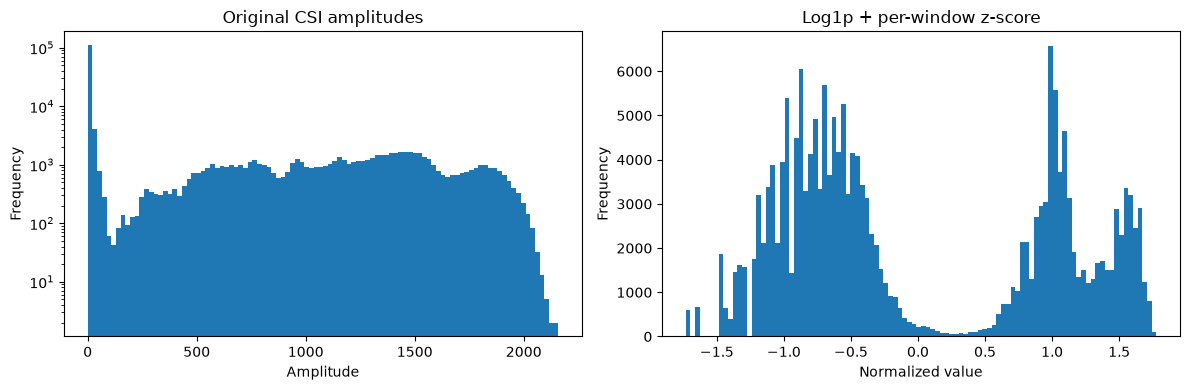

In [ ]:
# Step 13.2B — Test per-window normalization and visualize

import matplotlib.pyplot as plt
import numpy as np
from scripts.normalization import log1p_per_window_zscore

# Use five samples without modifying the original data
X_test = training_datasets[("Room A -> Room B", 1)]["X"][:5]
X_test_normalized = log1p_per_window_zscore(X_test)

# Validate output
assert X_test_normalized.shape == X_test.shape
assert X_test_normalized.dtype == np.float32
assert np.isfinite(X_test_normalized).all()

window_means = X_test_normalized.mean(axis=(1, 2))
window_stds = X_test_normalized.std(axis=(1, 2))

assert np.allclose(window_means, 0.0, atol=1e-4)
assert np.allclose(window_stds, 1.0, atol=1e-3)

print("Original shape:", X_test.shape)
print("Normalized shape:", X_test_normalized.shape)
print("Normalized dtype:", X_test_normalized.dtype)
print("Per-window means:", window_means)
print("Per-window standard deviations:", window_stds)
print("All normalized values finite:", np.isfinite(X_test_normalized).all())
print("Step 13.2B passed.")

# Plot original versus normalized value distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(X_test.ravel(), bins=100)
axes[0].set_title("Original CSI amplitudes")
axes[0].set_xlabel("Amplitude")
axes[0].set_ylabel("Frequency")
axes[0].set_yscale("log")

axes[1].hist(X_test_normalized.ravel(), bins=100)
axes[1].set_title("Log1p + per-window z-score")
axes[1].set_xlabel("Normalized value")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### 13.2C — Compare original and normalized distributions
Purpose: Compare the original and normalized values for the same five windows, and check whether the log transform reduces skew and whether normalization introduces any unexpected values.

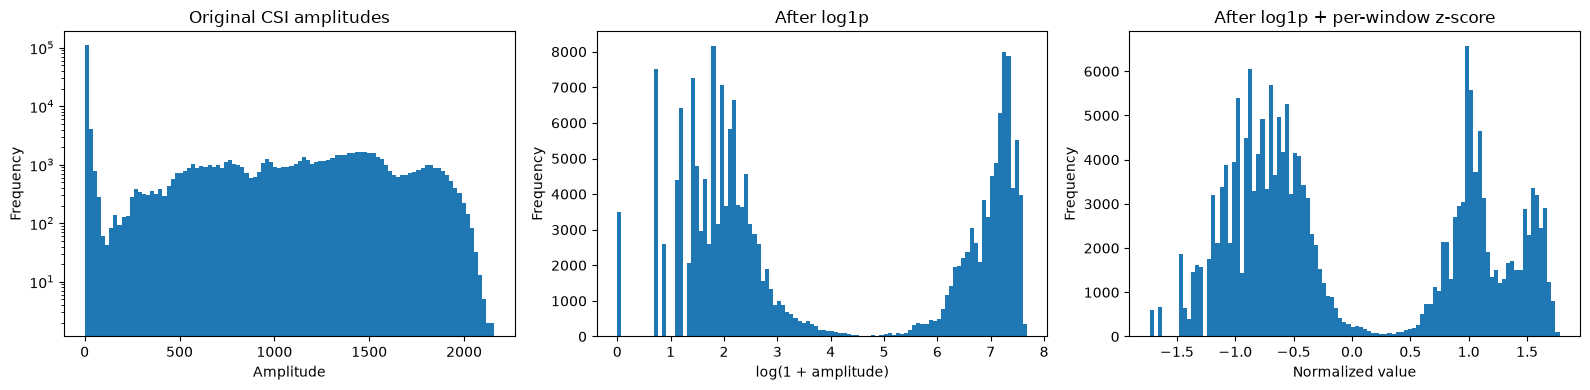

Original range: 0.0 to 2159.222900390625
After log1p range: 0.0 to 7.677966594696045
Normalized range: -1.7316375970840454 to 1.7779728174209595
Original global mean: 469.965087890625
Normalized global mean: 3.6875405839964515e-08
Original global std: 636.6036376953125
Normalized global std: 1.0


In [ ]:
# Step 13.2C — Plot and compare distributions

import matplotlib.pyplot as plt
import numpy as np

# Reuse X_test and X_test_normalized from Step 13.2B
X_log = np.log1p(X_test)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(X_test.ravel(), bins=100)
axes[0].set_title("Original CSI amplitudes")
axes[0].set_xlabel("Amplitude")
axes[0].set_ylabel("Frequency")
axes[0].set_yscale("log")

axes[1].hist(X_log.ravel(), bins=100)
axes[1].set_title("After log1p")
axes[1].set_xlabel("log(1 + amplitude)")
axes[1].set_ylabel("Frequency")

axes[2].hist(X_test_normalized.ravel(), bins=100)
axes[2].set_title("After log1p + per-window z-score")
axes[2].set_xlabel("Normalized value")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print("Original range:",
      float(X_test.min()), "to", float(X_test.max()))
print("After log1p range:",
      float(X_log.min()), "to", float(X_log.max()))
print("Normalized range:",
      float(X_test_normalized.min()), "to",
      float(X_test_normalized.max()))

print("Original global mean:", float(X_test.mean()))
print("Normalized global mean:", float(X_test_normalized.mean()))
print("Original global std:", float(X_test.std()))
print("Normalized global std:", float(X_test_normalized.std()))

**Interpretation of your graphs**

- Original amplitudes: There is a large concentration near zero and a broad range extending above 2,000.
- After log1p: The maximum drops from approximately 2,159 to 7.68, reducing the influence of large values.
- After per-window z-score: The values range from approximately −1.73 to 1.78, with global mean close to zero and standard deviation equal to one.

#### 13.2D — Compare normalization effects per window
Before applying this method to all eight datasets, let's plot the mean and standard deviation of each of the five test windows before and after normalization. This makes it easier to verify that normalization works consistently for individual samples rather than only for the pooled distribution.

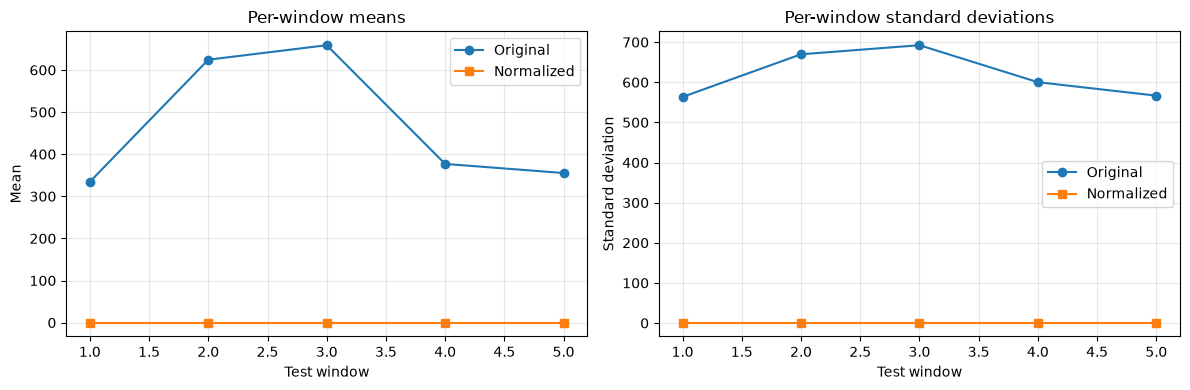

Normalized means: [-6.9936114e-08  1.7801921e-07 -6.3578289e-09  1.0172526e-07
 -2.5431316e-08]
Normalized standard deviations: [1.0000001 1.        1.        1.        1.       ]
Step 13.2D passed.


In [ ]:
# Step 13.2D — Compare per-window statistics before and after normalization

import matplotlib.pyplot as plt
import numpy as np

original_means = X_test.mean(axis=(1, 2))
original_stds = X_test.std(axis=(1, 2))

normalized_means = X_test_normalized.mean(axis=(1, 2))
normalized_stds = X_test_normalized.std(axis=(1, 2))

window_ids = np.arange(1, len(X_test) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    window_ids, original_means, marker="o", label="Original"
)
axes[0].plot(
    window_ids, normalized_means, marker="s", label="Normalized"
)
axes[0].set_title("Per-window means")
axes[0].set_xlabel("Test window")
axes[0].set_ylabel("Mean")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    window_ids, original_stds, marker="o", label="Original"
)
axes[1].plot(
    window_ids, normalized_stds, marker="s", label="Normalized"
)
axes[1].set_title("Per-window standard deviations")
axes[1].set_xlabel("Test window")
axes[1].set_ylabel("Standard deviation")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Normalized means:", normalized_means)
print("Normalized standard deviations:", normalized_stds)

assert np.allclose(normalized_means, 0, atol=1e-4)
assert np.allclose(normalized_stds, 1, atol=1e-3)

print("Step 13.2D passed.")

**Findings:**

The graphs confirm that normalization behaves consistently across all five test windows:
- Original window means vary from roughly 330 to 660, while normalized means are effectively zero.
- Original standard deviations vary from roughly 560 to 690, while normalized standard deviations are approximately one.
- Both normalization assertions passed.
The normalized series appears close to zero in these plots because the original and normalized statistics share the same axes, which have been scaled to accommodate the original values. This is expected.

### 13.3 — Normalize all eight training datasets
Now we will create a separate dictionary, normalized_training_datasets, so the original training_datasets remain unchanged.

Purpose: Apply the tested normalization function to every experiment and verify shape, dtype, finite values, and per-window statistics. We'll also graph the before-and-after distributions for one experiment.

PASS | Room A -> Room B | K=1
PASS | Room A -> Room B | K=5
PASS | Room A -> Room B | K=10
PASS | Room A -> Room B | K=20
PASS | Room B -> Room A | K=1
PASS | Room B -> Room A | K=5
PASS | Room B -> Room A | K=10
PASS | Room B -> Room A | K=20


,adaptation_direction,K,n_samples,shape,dtype,min_normalized,max_normalized,mean_of_window_means,std_of_window_stds
0,Room A -> Room B,1,444,"(444, 150, 256)",float32,-4.144366,2.179848,-2.319077e-09,1.0
1,Room A -> Room B,5,468,"(468, 150, 256)",float32,-4.268221,2.179848,-4.297351e-09,1.0
2,Room A -> Room B,10,498,"(498, 150, 256)",float32,-4.415658,2.179848,-3.951102e-09,1.0
3,Room A -> Room B,20,558,"(558, 150, 256)",float32,-4.854053,2.179848,-4.249057e-09,1.0
4,Room B -> Room A,1,1527,"(1527, 150, 256)",float32,-4.714563,2.102563,4.743486e-09,1.0
5,Room B -> Room A,5,1539,"(1539, 150, 256)",float32,-4.714563,2.102563,4.504075e-09,1.0
6,Room B -> Room A,10,1554,"(1554, 150, 256)",float32,-4.714563,2.102563,4.378774e-09,1.0
7,Room B -> Room A,20,1584,"(1584, 150, 256)",float32,-4.714563,2.102563,4.502051e-09,1.0


Step 13.3 complete: all eight datasets normalized.


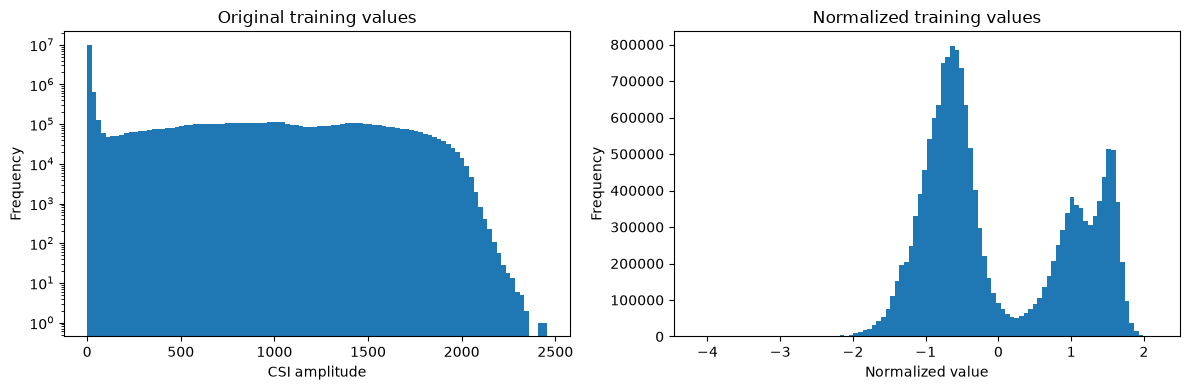

In [ ]:
# Step 13.3 — Normalize all eight training datasets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scripts.normalization import log1p_per_window_zscore

normalized_training_datasets = {}
normalization_summary = []

for (direction, K), dataset in training_datasets.items():
    X_original = dataset["X"]
    X_normalized = log1p_per_window_zscore(X_original)

    # Validate tensor properties
    assert X_normalized.shape == X_original.shape
    assert X_normalized.dtype == np.float32
    assert np.isfinite(X_normalized).all()

    # Check normalization per window
    means = X_normalized.mean(axis=(1, 2))
    stds = X_normalized.std(axis=(1, 2))

    assert np.allclose(means, 0.0, atol=1e-4)
    assert np.allclose(stds, 1.0, atol=1e-3)

    # Preserve labels and manifests; store normalized X separately
    normalized_training_datasets[(direction, K)] = {
        "X": X_normalized,
        "y": dataset["y"].copy(),
        "manifest": dataset["manifest"].copy(),
    }

    normalization_summary.append({
        "adaptation_direction": direction,
        "K": K,
        "n_samples": len(X_normalized),
        "shape": X_normalized.shape,
        "dtype": str(X_normalized.dtype),
        "min_normalized": float(X_normalized.min()),
        "max_normalized": float(X_normalized.max()),
        "mean_of_window_means": float(means.mean()),
        "std_of_window_stds": float(stds.mean()),
    })

    print(f"PASS | {direction} | K={K}")

normalization_summary_df = pd.DataFrame(normalization_summary)
display(normalization_summary_df)

print("Step 13.3 complete: all eight datasets normalized.")

# Plot one example to visually compare the distributions
example_key = ("Room A -> Room B", 1)
X_before = training_datasets[example_key]["X"]
X_after = normalized_training_datasets[example_key]["X"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(X_before.ravel(), bins=100)
axes[0].set_title("Original training values")
axes[0].set_xlabel("CSI amplitude")
axes[0].set_ylabel("Frequency")
axes[0].set_yscale("log")

axes[1].hist(X_after.ravel(), bins=100)
axes[1].set_title("Normalized training values")
axes[1].set_xlabel("Normalized value")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Findings:**

*What the results tell us*

- All eight normalized arrays preserve their expected shapes and float32 data type.
- The mean of per-window means is effectively zero, and the mean of per-window standard deviations is 1.0.
- The original data remains separate from the normalized data.
- The normalized histogram remains multimodal. This is not a failure; normalization standardizes each window but does not force its values to follow a Gaussian distribution.

**One important consideration:** per-window normalization removes absolute amplitude and overall scale information.

### 13.4 — Verify that normalization preserves labels and manifests
Before preparing validation data, let's confirm that normalization changed only the input features and preserved the labels, row counts, and manifests for every experiment.

In [ ]:
# Step 13.4 — Verify normalized dataset integrity

for key, original in training_datasets.items():
    normalized = normalized_training_datasets[key]

    # Feature and label counts must match
    assert normalized["X"].shape == original["X"].shape
    assert len(normalized["y"]) == len(original["y"])
    assert len(normalized["manifest"]) == len(original["manifest"])

    # Labels and manifest rows must remain unchanged
    assert np.array_equal(normalized["y"], original["y"])
    pd.testing.assert_frame_equal(
        normalized["manifest"].reset_index(drop=True),
        original["manifest"].reset_index(drop=True),
    )

    # Normalization must not have modified the original tensor
    assert np.isfinite(original["X"]).all()

    print(f"PASS | {key[0]} | K={key[1]}")

print("Step 13.4 complete: labels, manifests, and original tensors verified.")

PASS | Room A -> Room B | K=1
PASS | Room A -> Room B | K=5
PASS | Room A -> Room B | K=10
PASS | Room A -> Room B | K=20
PASS | Room B -> Room A | K=1
PASS | Room B -> Room A | K=5
PASS | Room B -> Room A | K=10
PASS | Room B -> Room A | K=20
Step 13.4 complete: labels, manifests, and original tensors verified.


### 13.5 — Prepare the fixed validation datasets.
Purpose: Prepare the target-room validation tensors for both adaptation directions. We'll apply the same log1p plus per-window z-score transformation independently to each validation window. No normalization parameters will be fitted on validation data, and validation labels will be kept separate from the model inputs.

In [ ]:
# Step 13.5 — Prepare fixed validation datasets

from scripts.normalization import log1p_per_window_zscore

validation_datasets = {}

validation_specs = {
    "Room A -> Room B": {
        "target_room": "Room B",
        "X": X_room_b,
        "metadata": room_b_window_metadata,
    },
    "Room B -> Room A": {
        "target_room": "Room A",
        "X": X_room_a,
        "metadata": room_a_window_metadata,
    },
}

for direction, spec in validation_specs.items():
    metadata = spec["metadata"]

    # Select only the fixed validation split
    validation_mask = metadata["split"].eq("validation").to_numpy()
    validation_indices = np.flatnonzero(validation_mask)

    X_val = spec["X"][validation_indices]
    y_val = metadata.loc[validation_mask, "activity"].astype(str).to_numpy()

    # Normalize each validation window independently
    X_val_normalized = log1p_per_window_zscore(X_val)

    # Validate integrity
    assert len(X_val_normalized) == len(y_val)
    assert X_val_normalized.shape[1:] == (150, 256)
    assert X_val_normalized.dtype == np.float32
    assert np.isfinite(X_val_normalized).all()

    assert np.allclose(
        X_val_normalized.mean(axis=(1, 2)), 0.0, atol=1e-4
    )
    assert np.allclose(
        X_val_normalized.std(axis=(1, 2)), 1.0, atol=1e-3
    )

    validation_datasets[direction] = {
        "X": X_val_normalized,
        "y": y_val,
        "metadata": metadata.loc[validation_mask].copy().reset_index(drop=True),
    }

    print(
        f"PASS | {direction} | "
        f"target={spec['target_room']} | "
        f"validation windows={len(y_val)} | "
        f"shape={X_val_normalized.shape}"
    )

print("Step 13.5 complete: fixed validation datasets prepared.")

PASS | Room A -> Room B | target=Room B | validation windows=375 | shape=(375, 150, 256)
PASS | Room B -> Room A | target=Room A | validation windows=147 | shape=(147, 150, 256)
Step 13.5 complete: fixed validation datasets prepared.


**Findings:**

- Room A → Room B: 375 fixed validation windows, shape (375, 150, 256).
- Room B → Room A: 147 fixed validation windows, shape (147, 150, 256).
- Both datasets passed the shape, data type, finite-value, and per-window normalization checks.

The validation inputs are now prepared separately from training. Their labels remain available for evaluation, but must not influence model fitting or hyperparameter selection if this validation set is intended to remain a final held-out evaluation set.

### 13.6 — Plot the validation label distributions
Before model development, let's visualize the validation class counts for each target room. This will help us understand class imbalance and identify which classes need attention when interpreting the evaluation metrics.


Room A -> Room B
empty       75
lying       75
sitting     75
standing    75
walking     75
Total validation windows: 375

Room B -> Room A
fall       25
sit        23
sitdown    25
stand      25
standup    25
walk       24
Total validation windows: 147


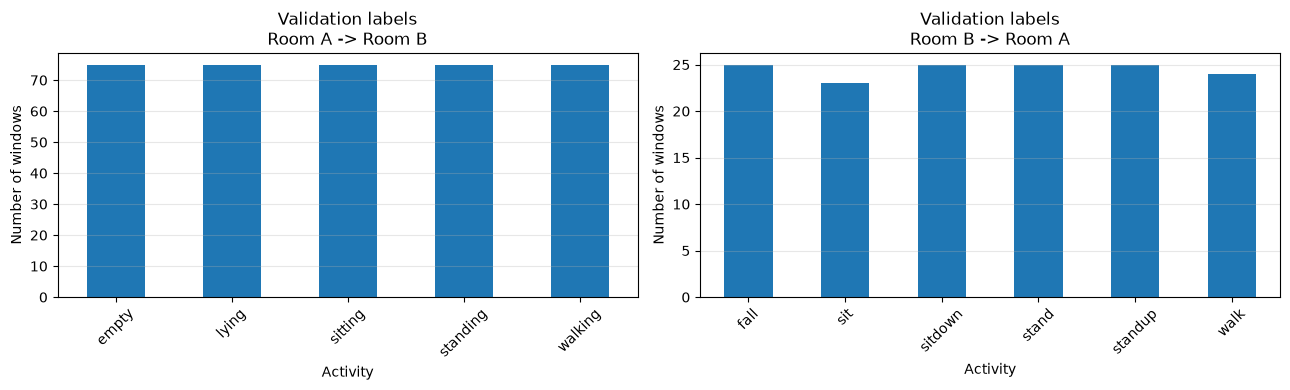

Step 13.6 complete: validation label distributions inspected.


In [ ]:
# Step 13.6 — Plot fixed validation label distributions

import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (direction, dataset) in zip(axes, validation_datasets.items()):
    counts = pd.Series(dataset["y"]).value_counts().sort_index()

    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"Validation labels\n{direction}")
    ax.set_xlabel("Activity")
    ax.set_ylabel("Number of windows")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

    print(f"\n{direction}")
    print(counts.to_string())
    print("Total validation windows:", int(counts.sum()))

plt.tight_layout()
plt.show()

print("Step 13.6 complete: validation label distributions inspected.")

**Interpretation of the graphs**

- Room A → Room B: The 375 validation windows are perfectly balanced, with 75 windows for each of empty, lying, sitting, standing, and walking.
- Room B → Room A: There are 147 validation windows. Four classes have 25 windows each, sit has 23, and walk has 24.
- Evaluation implication: The class distributions are nearly balanced, so macro-F1 and balanced accuracy will be useful alongside overall accuracy. We should still report per-class performance because balanced counts do not guarantee equal classification difficulty.

*One important detail*: these counts are windows, not necessarily distinct captures. Room B contributes three windows per capture, so we should keep capture-level grouping in mind when interpreting results.

### 13.7 — Verify validation labels against the challenge label mapping
Before training, let's confirm that validation labels use the same canonical labels as the training datasets. Your metadata currently shows lowercase/original labels such as sitting, fall, and sit, while the training labels use canonical names such as SIT and FALL. We must map these consistently before evaluation.

Purpose: Build validation labels in the canonical label space for each adaptation direction, without using them for training.

In [ ]:
# Step 13.7 — Map validation labels to canonical activity labels

validation_label_maps = {
    "Room A -> Room B": {
        "empty": "EMPTY",
        "lying": "LYING",
        "sitting": "SIT",
        "standing": "STAND",
        "walking": "WALK",
    },
    "Room B -> Room A": {
        "fall": "FALL",
        "sit": "SIT",
        "sitdown": "SITDOWN",
        "stand": "STAND",
        "standup": "STANDUP",
        "walk": "WALK",
    },
}

for direction, dataset in validation_datasets.items():
    original_labels = pd.Series(dataset["y"]).str.lower()
    label_map = validation_label_maps[direction]

    unexpected = set(original_labels.unique()) - set(label_map)
    assert not unexpected, (
        f"Unexpected validation labels in {direction}: {unexpected}"
    )

    canonical_labels = original_labels.map(label_map).to_numpy()

    # Confirm all labels map successfully
    assert not pd.isna(canonical_labels).any()

    dataset["y_canonical"] = canonical_labels

    print(f"\n{direction}")
    print(pd.Series(canonical_labels).value_counts().sort_index().to_string())
    print("Total:", len(canonical_labels))
    print("PASS: all validation labels mapped.")

print("Step 13.7 complete: canonical validation labels prepared.")


Room A -> Room B
EMPTY    75
LYING    75
SIT      75
STAND    75
WALK     75
Total: 375
PASS: all validation labels mapped.

Room B -> Room A
FALL       25
SIT        23
SITDOWN    25
STAND      25
STANDUP    25
WALK       24
Total: 147
PASS: all validation labels mapped.
Step 13.7 complete: canonical validation labels prepared.


## 14. Task 1: Room Fingerprint Classification
Description: This section develops a classifier that predicts whether a \(150 \times 256\) CSI amplitude window originates from Room A or Room B. The classifier will use only numerical CSI features, not filenames, capture identifiers, directory paths, or other source metadata. We will train using development windows, evaluate on the fixed validation windows, report room-identification accuracy, and visualize the results. We will also investigate the effect of window length as required by the challenge.

### 14.1 — Verify the data available for room classification
Before implementing the classifier in App/scripts/, let's check that both rooms' development tensors and validation tensors are available in the current notebook session.

In [ ]:
# Step 14.1 — Verify room-classification data availability

import numpy as np

# Development data
room_a_dev_mask = room_a_window_metadata["split"].eq("development").to_numpy()
room_b_dev_mask = room_b_window_metadata["split"].eq("development").to_numpy()

X_room_a_dev = X_room_a[room_a_dev_mask]
X_room_b_dev = X_room_b[room_b_dev_mask]

# Fixed validation data prepared in Section 13
X_room_a_val = validation_datasets["Room B -> Room A"]["X"]
X_room_b_val = validation_datasets["Room A -> Room B"]["X"]

# Check shapes and numerical validity
for name, X in {
    "Room A development": X_room_a_dev,
    "Room B development": X_room_b_dev,
    "Room A validation": X_room_a_val,
    "Room B validation": X_room_b_val,
}.items():
    assert X.ndim == 3
    assert X.shape[1:] == (150, 256)
    assert np.isfinite(X).all()
    print(f"{name}: shape={X.shape}, dtype={X.dtype}")

print("\nStep 14.1 complete: room-classification inputs verified.")

Room A development: shape=(923, 150, 256), dtype=float32
Room B development: shape=(3228, 150, 256), dtype=float32
Room A validation: shape=(147, 150, 256), dtype=float32
Room B validation: shape=(375, 150, 256), dtype=float32

Step 14.1 complete: room-classification inputs verified.


**Attention:**

Room A has 923 development windows, while Room B has 3,228. We should account for this imbalance when splitting training and test data for Task 1. Also, the fixed validation set should remain untouched until final evaluation.

### 14.2 — Create the reusable room-classification data builder
Purpose: Put reusable code in App/scripts/room_classifier.py. We'll create room labels (Room A = 0, Room B = 1) and combine the development data without including filenames or capture metadata as features.

In [ ]:
# Step 14.2B — Test the room-classification data builder

from scripts.room_classifier import build_room_classification_dataset

X_room_dev, y_room_dev = build_room_classification_dataset(
    X_room_a_dev,
    X_room_b_dev,
)

assert X_room_dev.shape == (923 + 3228, 150, 256)
assert y_room_dev.shape == (4151,)
assert np.sum(y_room_dev == 0) == 923
assert np.sum(y_room_dev == 1) == 3228
assert np.isfinite(X_room_dev).all()

print("Combined development shape:", X_room_dev.shape)
print("Room A samples:", int(np.sum(y_room_dev == 0)))
print("Room B samples:", int(np.sum(y_room_dev == 1)))
print("Step 14.2B passed.")

Combined development shape: (4151, 150, 256)
Room A samples: 923
Room B samples: 3228
Step 14.2B passed.


**Note:**

Because the classes are imbalanced, a classifier that always predicts Room B would already achieve about 77.8% accuracy. We should therefore compare our model against that baseline and report balanced accuracy as an additional diagnostic, while keeping the challenge-required room-identification accuracy.

### 14.3 — Create a room-classification training and test split
Purpose: Split the development windows into a stratified training subset and a held-out development test subset. We will use the held-out subset for model selection and keep the fixed validation sets separate for final evaluation.

For now, we will use a stratified 80/20 split, with a fixed random seed. This split is at the window level; if several windows come from the same original capture, a capture-grouped split would be preferable to avoid related windows appearing on both sides. Room A currently has one window per capture, whereas Room B has three, so we should check capture grouping before treating the split as definitive.

In [ ]:
# Step 14.3 — Stratified development split

from sklearn.model_selection import train_test_split
import numpy as np

indices = np.arange(len(y_room_dev))

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y_room_dev,
)

X_room_train = X_room_dev[train_indices]
y_room_train = y_room_dev[train_indices]

X_room_test = X_room_dev[test_indices]
y_room_test = y_room_dev[test_indices]

# Verify split sizes and class representation
assert len(train_indices) + len(test_indices) == len(y_room_dev)
assert set(np.unique(y_room_train)) == {0, 1}
assert set(np.unique(y_room_test)) == {0, 1}
assert not set(train_indices).intersection(test_indices)

print("Training shape:", X_room_train.shape)
print("Held-out development test shape:", X_room_test.shape)

print("\nTraining class counts:")
print("Room A:", int(np.sum(y_room_train == 0)))
print("Room B:", int(np.sum(y_room_train == 1)))

print("\nHeld-out test class counts:")
print("Room A:", int(np.sum(y_room_test == 0)))
print("Room B:", int(np.sum(y_room_test == 1)))

print("\nMajority-class baseline accuracy:",
      round(np.mean(y_room_test == 1), 4))

print("Step 14.3 complete.")

Training shape: (3320, 150, 256)
Held-out development test shape: (831, 150, 256)

Training class counts:
Room A: 738
Room B: 2582

Held-out test class counts:
Room A: 185
Room B: 646

Majority-class baseline accuracy: 0.7774
Step 14.3 complete.


**Findings:**

The majority-class baseline is 77.74% accuracy, so our classifier needs to outperform that baseline to demonstrate useful room discrimination.

*One important consideration before training:* Room B contributes three windows per original capture. A random window-level split can put windows from the same capture into both training and test sets, potentially inflating performance. Let's check and correct that before proceeding.

### 14.4 — Check capture leakage in the development split
Purpose: Verify whether any original capture contributes windows to both the training and held-out test subsets.

In [ ]:
# Step 14.4 — Check for capture overlap between development splits

room_a_dev_metadata = room_a_window_metadata.loc[
    room_a_window_metadata["split"].eq("development")
].reset_index(drop=True)

room_b_dev_metadata = room_b_window_metadata.loc[
    room_b_window_metadata["split"].eq("development")
].reset_index(drop=True)

# The combined dataset concatenated Room A first, then Room B.
combined_dev_metadata = pd.concat(
    [
        room_a_dev_metadata.assign(room_label=0),
        room_b_dev_metadata.assign(room_label=1),
    ],
    ignore_index=True,
)

assert len(combined_dev_metadata) == len(y_room_dev)

train_captures = set(
    combined_dev_metadata.iloc[train_indices]["intermediate_csv_path"]
)
test_captures = set(
    combined_dev_metadata.iloc[test_indices]["intermediate_csv_path"]
)

overlap = train_captures.intersection(test_captures)

print("Unique training captures:", len(train_captures))
print("Unique held-out test captures:", len(test_captures))
print("Captures appearing in both splits:", len(overlap))

if overlap:
    print("WARNING: capture leakage exists in the window-level split.")
else:
    print("PASS: no capture overlap detected.")

Unique training captures: 1806
Unique held-out test captures: 711
Captures appearing in both splits: 518


**Findigs:**

The result confirms serious capture leakage in the current window-level split: 518 captures appear in both training and held-out test sets. Because Room B contributes three windows per capture, the model could learn capture-specific patterns rather than generalize to unseen captures.

### 14.5 — Create a leakage-free, capture-grouped split
Purpose: Keep every window from the same capture entirely within either training or held-out testing. We’ll use stratified group splitting to preserve the Room A/Room B balance as closely as possible.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Create room-qualified capture IDs to ensure groups cannot collide.
groups = (
    combined_dev_metadata["room_label"].astype(str)
    + "::"
    + combined_dev_metadata["intermediate_csv_path"].astype(str)
).to_numpy()

assert len(groups) == len(y_room_dev) == len(X_room_dev)

# Five folds gives approximately an 80/20 train/test split.
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

train_indices, test_indices = next(
    splitter.split(X_room_dev, y_room_dev, groups=groups)
)

X_room_train = X_room_dev[train_indices]
y_room_train = y_room_dev[train_indices]

X_room_test = X_room_dev[test_indices]
y_room_test = y_room_dev[test_indices]

train_groups = set(groups[train_indices])
test_groups = set(groups[test_indices])
overlap = train_groups.intersection(test_groups)

print("Training windows:", len(train_indices))
print("Held-out test windows:", len(test_indices))
print("Training captures:", len(train_groups))
print("Held-out test captures:", len(test_groups))
print("Captures appearing in both splits:", len(overlap))

print("\nTraining class counts:")
print(pd.Series(y_room_train).value_counts().sort_index().rename(
    index={0: "Room A", 1: "Room B"}
))

print("\nHeld-out test class counts:")
print(pd.Series(y_room_test).value_counts().sort_index().rename(
    index={0: "Room A", 1: "Room B"}
))

assert len(overlap) == 0, "Capture leakage detected!"
assert set(np.unique(y_room_train)) == {0, 1}
assert set(np.unique(y_room_test)) == {0, 1}

print("\nPASS: no capture overlap; both rooms are represented in both splits.")

Training windows: 3321
Held-out test windows: 830
Training captures: 1599
Held-out test captures: 400
Captures appearing in both splits: 0

Training class counts:
Room A     738
Room B    2583
Name: count, dtype: int64

Held-out test class counts:
Room A    185
Room B    645
Name: count, dtype: int64

PASS: no capture overlap; both rooms are represented in both splits.


### 14.6 — Normalize the development data consistently
Before training, we need to resolve one preprocessing inconsistency: the development tensors are currently raw, while the fixed validation tensors from Section 13 are already normalized. We’ll apply the existing log1p_per_window_zscore function to the development data, using each window’s own values rather than fitting statistics on validation data.

In [ ]:
import numpy as np
from scripts.normalization import log1p_per_window_zscore

# Normalize training and held-out development-test windows consistently.
X_room_train_norm = log1p_per_window_zscore(X_room_train)
X_room_test_norm = log1p_per_window_zscore(X_room_test)

# Confirm shapes, dtypes, and numerical stability.
assert X_room_train_norm.shape == X_room_train.shape
assert X_room_test_norm.shape == X_room_test.shape
assert X_room_train_norm.dtype == np.float32
assert X_room_test_norm.dtype == np.float32
assert np.isfinite(X_room_train_norm).all()
assert np.isfinite(X_room_test_norm).all()

# Check per-window normalization.
train_means = X_room_train_norm.mean(axis=(1, 2))
train_stds = X_room_train_norm.std(axis=(1, 2))
test_means = X_room_test_norm.mean(axis=(1, 2))
test_stds = X_room_test_norm.std(axis=(1, 2))

print("Training tensor:", X_room_train_norm.shape, X_room_train_norm.dtype)
print("Held-out test tensor:", X_room_test_norm.shape, X_room_test_norm.dtype)

print("\nTraining window means:")
print("Mean:", float(train_means.mean()))
print("Maximum absolute window mean:", float(np.abs(train_means).max()))

print("\nHeld-out test window means:")
print("Mean:", float(test_means.mean()))
print("Maximum absolute window mean:", float(np.abs(test_means).max()))

print("\nAverage training window standard deviation:", float(train_stds.mean()))
print("Average test window standard deviation:", float(test_stds.mean()))

print("\nPASS: development data are consistently normalized and finite.")

Training tensor: (3321, 150, 256) float32
Held-out test tensor: (830, 150, 256) float32

Training window means:
Mean: 2.3900186274516955e-09
Maximum absolute window mean: 5.571047267949325e-07

Held-out test window means:
Mean: 1.3027146472666118e-08
Maximum absolute window mean: 5.070368729320762e-07

Average training window standard deviation: 1.0
Average test window standard deviation: 1.0

PASS: development data are consistently normalized and finite.


### 14.7 — Build a compact feature-based room classifier
Purpose: Train a baseline that predicts whether each CSI window came from Room A or Room B, without using filenames, capture paths, or other metadata as model inputs.

Rather than flattening every **150 X 256** window into 38,400 features, we’ll start with compact statistical features calculated from each window. This is faster to train and provides a useful baseline before trying more complex models.

In [ ]:
from scripts.room_classifier import extract_room_features

# 1. Extract reusable numerical features.
X_features_train = extract_room_features(X_room_train_norm)
X_features_test = extract_room_features(X_room_test_norm)

print("Training features:", X_features_train.shape)
print("Test features:", X_features_test.shape)
print("Training dtype:", X_features_train.dtype)
print("Test dtype:", X_features_test.dtype)
print("All features finite:",
      np.isfinite(X_features_train).all()
      and np.isfinite(X_features_test).all())


assert X_features_train.shape == (3321, 521)
assert X_features_test.shape == (830, 521)
assert X_features_train.dtype == np.float32
assert X_features_test.dtype == np.float32
assert np.isfinite(X_features_train).all()
assert np.isfinite(X_features_test).all()

print("PASS: feature extraction, validation, and visualization completed.")

Training features: (3321, 521)
Test features: (830, 521)
Training dtype: float32
Test dtype: float32
All features finite: True
PASS: feature extraction and validation completed.


**Note:**

Here is the calculation:
- 7 global statistics per window
- 256 per-subcarrier means
- 256 per-subcarrier standard deviations
- 2 temporal-variation statistics

Total: \(7 + 256 + 256 + 2 = 521\) features.

**Plot 1 — Compare feature distributions by room**

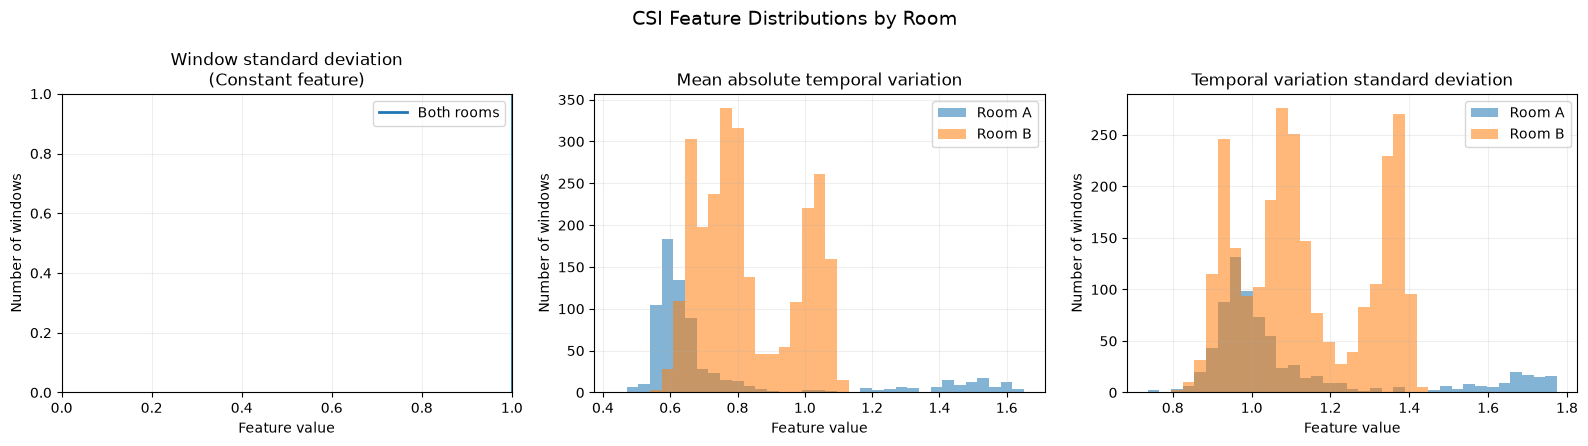

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

feature_df = pd.DataFrame({
    "Room": np.where(y_room_train == 0, "Room A", "Room B"),
    "Window standard deviation": X_features_train[:, 1],
    "Mean absolute temporal difference": X_features_train[:, -2],
    "Temporal difference standard deviation": X_features_train[:, -1],
})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

plot_columns = [
    ("Window standard deviation", "Window standard deviation"),
    ("Mean absolute temporal difference", "Mean absolute temporal variation"),
    ("Temporal difference standard deviation", "Temporal variation standard deviation"),
]

for ax, (column, title) in zip(axes, plot_columns):
    room_a = feature_df.loc[
        feature_df["Room"] == "Room A", column
    ].to_numpy()
    room_b = feature_df.loc[
        feature_df["Room"] == "Room B", column
    ].to_numpy()

    combined = np.concatenate([room_a, room_b])
    low, high = combined.min(), combined.max()

    if np.isclose(low, high):
        # Constant feature: show the value instead of a histogram.
        ax.axvline(low, linewidth=2, label="Both rooms")
        ax.set_title(f"{title}\n(Constant feature)")
    else:
        # Identical bin edges allow fair visual comparison.
        bins = np.linspace(low, high, 36)
        ax.hist(room_a, bins=bins, alpha=0.55, label="Room A")
        ax.hist(room_b, bins=bins, alpha=0.55, label="Room B")
        ax.set_title(title)

    ax.set_xlabel("Feature value")
    ax.set_ylabel("Number of windows")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle("CSI Feature Distributions by Room", fontsize=14)
plt.tight_layout()
plt.show()

**Observation**

Per-window normalization makes the global window standard deviation approximately constant, so it provides no useful room-discrimination information. In contrast, mean absolute temporal variation and temporal-difference standard deviation exhibit different distributions across Room A and Room B, although both retain substantial overlap. These features are therefore candidates for room identification, but their actual predictive value must be assessed using a classifier on capture-disjoint test data.

**Plot 2 — Visualize room class balance**

This shows the training-set imbalance, which is why we use class_weight="balanced" in logistic regression.

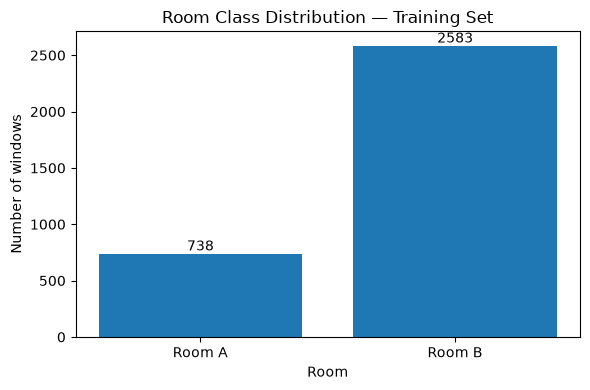

In [ ]:
room_counts = pd.Series(y_room_train).map({
    0: "Room A",
    1: "Room B"
}).value_counts().reindex(["Room A", "Room B"])

plt.figure(figsize=(6, 4))
bars = plt.bar(room_counts.index, room_counts.values)

plt.title("Room Class Distribution — Training Set")
plt.xlabel("Room")
plt.ylabel("Number of windows")

for bar, count in zip(bars, room_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

**Plot 3 — Correlation between selected features**

This helps identify whether the summary features provide similar or different information.

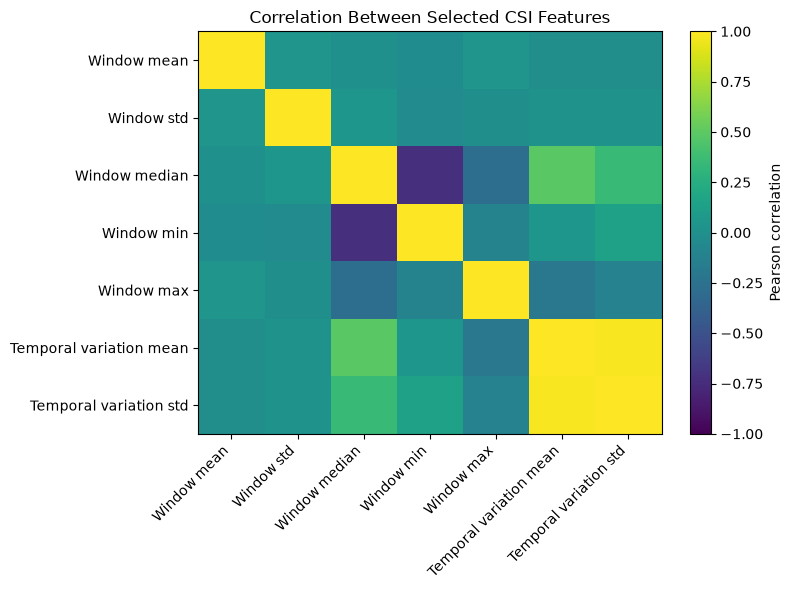

In [ ]:
selected_features = pd.DataFrame({
    "Window mean": X_features_train[:, 0],
    "Window std": X_features_train[:, 1],
    "Window median": X_features_train[:, 2],
    "Window min": X_features_train[:, 3],
    "Window max": X_features_train[:, 4],
    "Temporal variation mean": X_features_train[:, -2],
    "Temporal variation std": X_features_train[:, -1],
})

corr = selected_features.corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation Between Selected CSI Features")

plt.tight_layout()
plt.show()

### 14.8 — Train the baseline room classifier
Purpose: Train a classifier to distinguish Room A from Room B using the extracted CSI features. We’ll use a StandardScaler plus logistic regression, with class weighting to account for the imbalance between rooms.

The scaler will be fitted on training features only. We’ll evaluate first on the capture-disjoint held-out development test set, not the fixed validation sets.

Held-out room-identification accuracy: 1.0000
Held-out balanced accuracy: 1.0000

Classification report:
              precision    recall  f1-score   support

      Room A       1.00      1.00      1.00       185
      Room B       1.00      1.00      1.00       645

    accuracy                           1.00       830
   macro avg       1.00      1.00      1.00       830
weighted avg       1.00      1.00      1.00       830



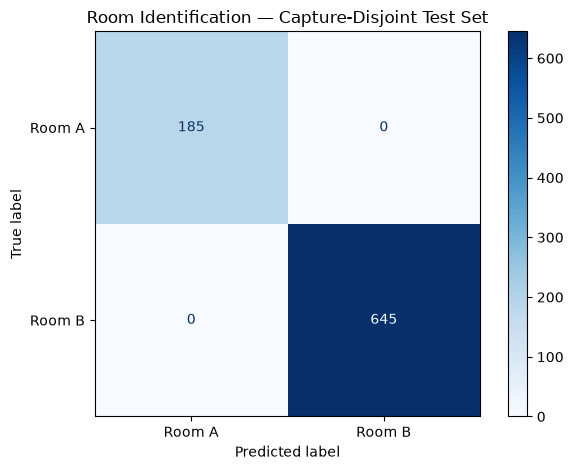

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

# Fit only on the training split.
room_classifier_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42,
    ),
)

room_classifier_model.fit(X_features_train, y_room_train)

# Evaluate on capture-disjoint held-out development data.
y_room_test_pred = room_classifier_model.predict(X_features_test)

room_test_accuracy = accuracy_score(y_room_test, y_room_test_pred)
room_test_balanced_accuracy = balanced_accuracy_score(
    y_room_test, y_room_test_pred
)

print(f"Held-out room-identification accuracy: {room_test_accuracy:.4f}")
print(
    "Held-out balanced accuracy: "
    f"{room_test_balanced_accuracy:.4f}"
)

print("\nClassification report:")
print(
    classification_report(
        y_room_test,
        y_room_test_pred,
        labels=[0, 1],
        target_names=["Room A", "Room B"],
        zero_division=0,
    )
)

# Confusion matrix graph.
ConfusionMatrixDisplay.from_predictions(
    y_room_test,
    y_room_test_pred,
    labels=[0, 1],
    display_labels=["Room A", "Room B"],
    cmap="Blues",
    values_format="d",
)
plt.title("Room Identification — Capture-Disjoint Test Set")
plt.tight_layout()
plt.show()

**Observations:**

The baseline classifier achieved 100% accuracy and 100% balanced accuracy on all 830 capture-disjoint held-out test windows.

However, we should verify this result before treating it as a final achievement. Perfect accuracy can be genuine when room-specific signal distributions differ strongly, but it can also arise from unintended dataset or preprocessing differences.

### 14.9 — Verify the result and inspect feature importance
Purpose: Confirm that the model is not benefiting from an accidental difference in preprocessing, and identify which features distinguish the rooms.

Test labels: 830
Predictions: 830
Correct predictions: 830
Incorrect predictions: 0

Confusion matrix (rows=true, columns=predicted):
[[185   0]
 [  0 645]]

Training feature summaries:


,Feature,Room,Mean,Std
0,Global standard deviation,Room A,1.00000,0.00000
1,Global standard deviation,Room B,1.00000,0.00000
2,Global median,Room A,-0.33286,0.32111
3,Global median,Room B,0.24623,0.03647
4,Mean of subcarrier means,Room A,-0.00000,0.00000
5,Mean of subcarrier means,Room B,0.00000,0.00000
6,Mean of subcarrier standard deviations,Room A,0.65296,0.07430
7,Mean of subcarrier standard deviations,Room B,0.81383,0.10436
8,Mean absolute temporal difference,Room A,0.75010,0.30069
9,Mean absolute temporal difference,Room B,0.83202,0.14651


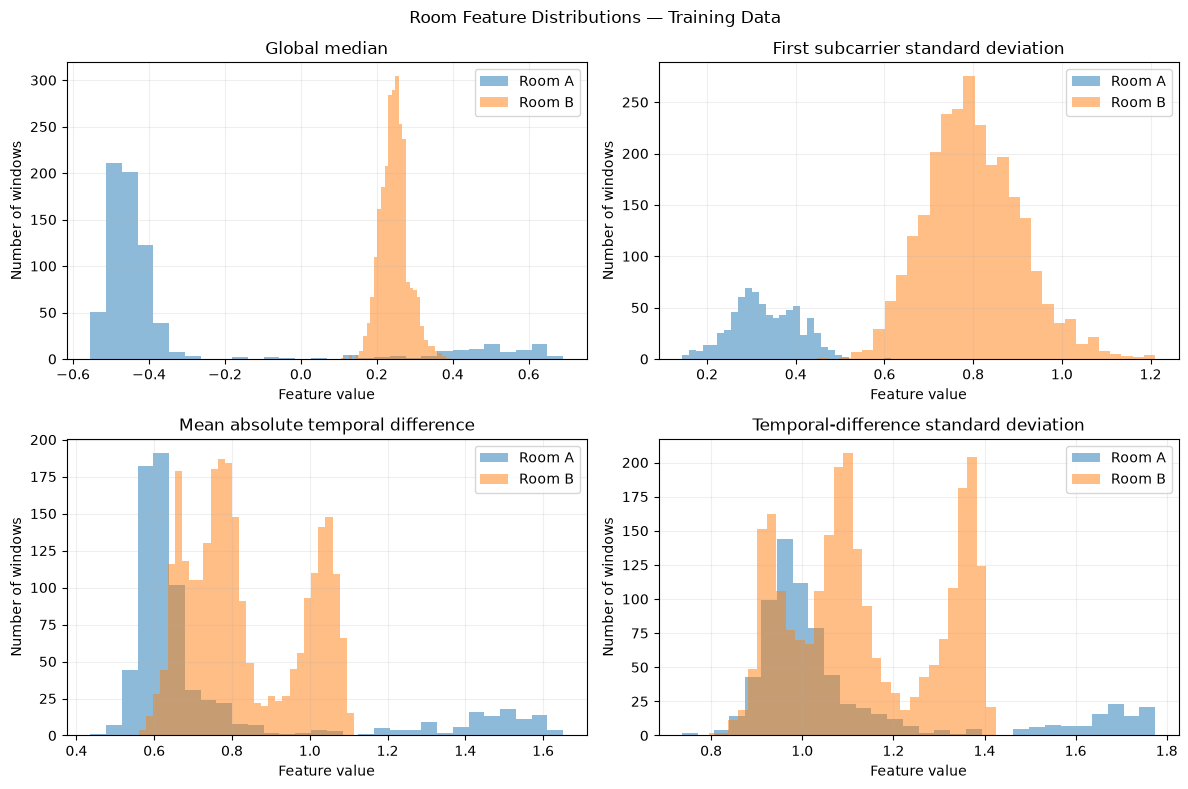

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. Confirm predictions and confusion matrix.
print("Test labels:", len(y_room_test))
print("Predictions:", len(y_room_test_pred))
print("Correct predictions:",
      int(np.sum(y_room_test == y_room_test_pred)))
print("Incorrect predictions:",
      int(np.sum(y_room_test != y_room_test_pred)))

print("\nConfusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_room_test, y_room_test_pred, labels=[0, 1]))

# 2. Compare feature distributions between rooms.
# Features 0–6 are global statistics.
# Feature 7 is the first subcarrier mean.
# Feature 263 is the last subcarrier mean.
# Feature 519 is mean absolute temporal difference.
# Feature 520 is temporal-difference standard deviation.
diagnostic_features = {
    "Global standard deviation": 1,
    "Global median": 2,
    "Mean of subcarrier means": slice(7, 263),
    "Mean of subcarrier standard deviations": slice(263, 519),
    "Mean absolute temporal difference": 519,
    "Temporal-difference standard deviation": 520,
}

summary_rows = []

for name, selector in diagnostic_features.items():
    values = X_features_train[:, selector]

    if isinstance(selector, slice):
        values = values.mean(axis=1)

    for label, room_name in [(0, "Room A"), (1, "Room B")]:
        room_values = values[y_room_train == label]
        summary_rows.append({
            "Feature": name,
            "Room": room_name,
            "Mean": float(np.mean(room_values)),
            "Std": float(np.std(room_values)),
        })

summary_df = pd.DataFrame(summary_rows)
print("\nTraining feature summaries:")
display(summary_df.round(5))

# 3. Plot only features that vary across the training windows.
plot_specs = [
    (2, "Global median"),
    (263, "First subcarrier standard deviation"),
    (519, "Mean absolute temporal difference"),
    (520, "Temporal-difference standard deviation"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, (feature_idx, feature_name) in zip(axes, plot_specs):
    for label, room_name in [(0, "Room A"), (1, "Room B")]:
        vals = X_features_train[y_room_train == label, feature_idx]

        # A constant feature cannot produce a meaningful histogram.
        if np.ptp(vals) == 0:
            ax.axvline(vals[0], label=f"{room_name} (constant)")
        else:
            ax.hist(vals, bins=30, alpha=0.5, label=room_name)

    ax.set_title(feature_name)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Number of windows")
    ax.legend()
    ax.grid(alpha=0.2)

plt.suptitle("Room Feature Distributions — Training Data")
plt.tight_layout()
plt.show()

**Note:**

The global standard deviation values are constant, so Matplotlib cannot create 30 distinct histogram bins for that feature. We skipped constant features in histograms.

**Interpretation of the feature distributions**

- Global median: Room A is mostly concentrated around −0.5, while Room B is concentrated around 0.24. This is a strong separation, although Room A has a small tail of outliers.
- First subcarrier standard deviation: Room A is concentrated around 0.3–0.4, while Room B is around 0.75–0.85. This is another strong distinguishing feature.
- Mean absolute temporal difference: The distributions overlap more, so this feature alone is less discriminative.
- Temporal-difference standard deviation: Room B has several concentrated modes, while Room A has a broader distribution and a higher-value tail.

Together, the features appear to contain substantial room-specific information. The plots are consistent with the perfect classification result, though they do not independently prove that the model will generalize to other recording sessions or rooms.

### 14.10 — Evaluate on the fixed validation sets
Purpose: Test whether the room classifier also distinguishes the two rooms on the fixed validation captures that were excluded from training and held-out development testing.

We already have normalized validation windows in validation_datasets. We will use the existing model and feature extractor without refitting either one.

Validation windows: 522
Room A validation windows: 147
Room B validation windows: 375
Validation accuracy: 1.0000
Validation balanced accuracy: 1.0000

Validation classification report:
              precision    recall  f1-score   support

      Room A       1.00      1.00      1.00       147
      Room B       1.00      1.00      1.00       375

    accuracy                           1.00       522
   macro avg       1.00      1.00      1.00       522
weighted avg       1.00      1.00      1.00       522



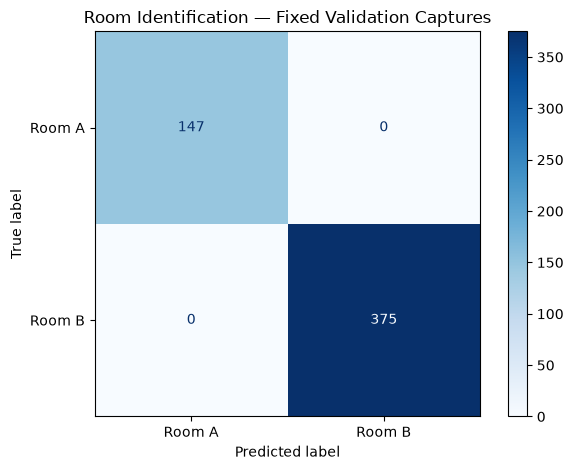

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Validation windows are already normalized in Section 13.
X_room_a_val = validation_datasets["Room B -> Room A"]["X"]
X_room_b_val = validation_datasets["Room A -> Room B"]["X"]

# Build a validation set using the same room-label convention:
# Room A = 0, Room B = 1.
X_room_val = np.concatenate([X_room_a_val, X_room_b_val], axis=0)
y_room_val = np.concatenate([
    np.zeros(len(X_room_a_val), dtype=np.int64),
    np.ones(len(X_room_b_val), dtype=np.int64),
])

# Validate inputs.
assert X_room_val.ndim == 3
assert X_room_val.shape[1:] == (150, 256)
assert np.isfinite(X_room_val).all()

# Use the exact same feature extraction and fitted model.
X_room_val_features = extract_room_features(X_room_val)
y_room_val_pred = room_classifier_model.predict(X_room_val_features)

val_accuracy = accuracy_score(y_room_val, y_room_val_pred)
val_balanced_accuracy = balanced_accuracy_score(
    y_room_val, y_room_val_pred
)

print("Validation windows:", len(y_room_val))
print("Room A validation windows:", int((y_room_val == 0).sum()))
print("Room B validation windows:", int((y_room_val == 1).sum()))
print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Validation balanced accuracy: {val_balanced_accuracy:.4f}")

print("\nValidation classification report:")
print(classification_report(
    y_room_val,
    y_room_val_pred,
    labels=[0, 1],
    target_names=["Room A", "Room B"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_room_val,
    y_room_val_pred,
    labels=[0, 1],
    display_labels=["Room A", "Room B"],
    cmap="Blues",
    values_format="d",
)
plt.title("Room Identification — Fixed Validation Captures")
plt.tight_layout()
plt.show()

**What we can conclude**

- The statistical-feature logistic regression baseline distinguishes the two rooms extremely well in the current dataset.
- The grouped development split avoided capture overlap.
- The same fitted model achieved perfect window-level results on the fixed validation data.
- The feature-distribution plots show clear room-specific differences, particularly in the global median and subcarrier variation.

*One remaining caution:* the Room B dataset contributes three windows per capture, so 375 validation windows do not represent 375 independent captures. Also, we have not yet tested generalization to new rooms or recording environments.

### 14.11: Prepare feature extraction for variable window lengths
Purpose: Test whether room identification can remain accurate when fewer than 150 CSI observations are used per window.

We'll evaluate lengths of 25, 50, 75, 100, and 125 observations, plus the official 150-observation window. For each length, we'll train a fresh classifier on the corresponding shortened development windows and evaluate it on equally shortened validation windows. This avoids comparing a model trained on one window length against inputs with a different length.

#### 14.11A — Update the reusable script
Update the extract_room_features() inside room_classifier.py to accept the multiple shape.


In [ ]:
import importlib
import scripts.room_classifier as room_classifier

# Reload the saved Python file.
importlib.reload(room_classifier)

<module 'scripts.room_classifier' from 'D:\\PhD_Courses\\Ubiquitous_Computing\\Assignment\\Hackathon-2\\App\\scripts\\room_classifier.py'>

In [ ]:
from scripts.room_classifier import extract_room_features

# Test the function on several lengths.
for length in [25, 50, 100, 150]:
    sample = X_room_train_norm[:5, :length, :]
    features = extract_room_features(sample)

    print(f"Length {length}: {features.shape}")
    assert features.shape == (5, 521)
    assert np.isfinite(features).all()

print("PASS: feature extraction supports variable window lengths.")

Length 25: (5, 521)
Length 50: (5, 521)
Length 100: (5, 521)
Length 150: (5, 521)
PASS: feature extraction supports variable window lengths.


#### 14.11B — Prepare shortened windows using consistent normalization
Purpose: Build comparable datasets for window lengths 25, 50, 75, 100, 125, and 150 observations. We will normalize each shortened window independently, using the same log1p_per_window_zscore() function. This avoids simply taking a slice of a 150-step normalized window, which would not be equivalent to normalizing the shorter window itself.

Firstly update the existing normalization function to process different time lengths while preserving the 256-subcarrier requirement and existing numerical checks.

In [ ]:
import importlib
import scripts.normalization as normalization_module

importlib.reload(normalization_module)


<module 'scripts.normalization' from 'D:\\PhD_Courses\\Ubiquitous_Computing\\Assignment\\Hackathon-2\\App\\scripts\\normalization.py'>

**Recover the raw validation windows**

Retrieve the validation windows from the original tensors and their metadata. The existing *room_a_window_metadata* and *room_b_window_metadata* csv files stored in the results directory contain the information.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

# Load metadata directly from CSV
room_a_metadata_path = OUTPUT_DIR / "room_a_window_metadata.csv"
room_b_metadata_path = OUTPUT_DIR / "room_b_window_metadata.csv"

# Load metadata directly from CSV
room_a_metadata_csv = pd.read_csv(room_a_metadata_path)
room_b_metadata_csv = pd.read_csv(room_b_metadata_path)

print("Room A metadata:", room_a_metadata_csv.shape)
print("Room B metadata:", room_b_metadata_csv.shape)
print("Room A columns:", room_a_metadata_csv.columns.tolist())
print("Room B columns:", room_b_metadata_csv.columns.tolist())

# Check that the metadata rows align with the original tensor rows
assert len(room_a_metadata_csv) == len(X_room_a), (
    f"Room A mismatch: {len(room_a_metadata_csv)} metadata rows "
    f"but {len(X_room_a)} tensor windows"
)
assert len(room_b_metadata_csv) == len(X_room_b), (
    f"Room B mismatch: {len(room_b_metadata_csv)} metadata rows "
    f"but {len(X_room_b)} tensor windows"
)

# Select validation rows using the CSV split column
assert "split" in room_a_metadata_csv.columns
assert "split" in room_b_metadata_csv.columns

room_a_val_mask = (
    room_a_metadata_csv["split"].astype(str).str.lower().eq("validation")
)
room_b_val_mask = (
    room_b_metadata_csv["split"].astype(str).str.lower().eq("validation")
)

# Recover validation tensors from the ORIGINAL raw amplitude arrays
X_room_a_val_raw = X_room_a[room_a_val_mask.to_numpy()]
X_room_b_val_raw = X_room_b[room_b_val_mask.to_numpy()]

print("\nRaw validation tensors")
print("Room A:", X_room_a_val_raw.shape)
print("Room B:", X_room_b_val_raw.shape)
print("Room A minimum:", float(X_room_a_val_raw.min()))
print("Room B minimum:", float(X_room_b_val_raw.min()))

# Validate shape, finiteness, and non-negative amplitudes
assert X_room_a_val_raw.shape == (147, 150, 256)
assert X_room_b_val_raw.shape == (375, 150, 256)

assert np.isfinite(X_room_a_val_raw).all()
assert np.isfinite(X_room_b_val_raw).all()
assert X_room_a_val_raw.min() >= 0
assert X_room_b_val_raw.min() >= 0

print("\nPASS: CSV metadata aligned with the tensors.")
print("PASS: Raw validation windows recovered successfully.")

Room A metadata: (1070, 8)
Room B metadata: (3603, 8)
Room A columns: ['window_id', 'capture_path', 'activity', 'split', 'intermediate_csv_path', 'window_index', 'start_observation', 'end_observation_exclusive']
Room B columns: ['window_id', 'capture_path', 'activity', 'split', 'intermediate_csv_path', 'window_index', 'start_observation', 'end_observation_exclusive']

Raw validation tensors
Room A: (147, 150, 256)
Room B: (375, 150, 256)
Room A minimum: 0.0
Room B minimum: 0.0

PASS: CSV metadata aligned with the tensors.
PASS: Raw validation windows recovered successfully.


In [ ]:

import numpy as np
import pandas as pd

from scripts.normalization import log1p_per_window_zscore

WINDOW_LENGTHS = [25, 50, 75, 100, 125, 150]

# Raw development windows, using the established capture-grouped split.
X_room_train_raw = X_room_dev[train_indices]
X_room_test_raw = X_room_dev[test_indices]

# Raw fixed-validation windows, in the established room order.
X_room_a_val = X_room_a_val_raw
X_room_b_val = X_room_b_val_raw

# Basic shape and label alignment checks.
assert X_room_train_raw.shape[0] == len(y_room_train)
assert X_room_test_raw.shape[0] == len(y_room_test)
assert X_room_a_val.shape[1:] == (150, 256)
assert X_room_b_val.shape[1:] == (150, 256)
assert all(2 <= length <= 150 for length in WINDOW_LENGTHS)

# Validation labels: Room A = 0, Room B = 1.
y_val_len = np.concatenate([
    np.zeros(len(X_room_a_val), dtype=np.int64),
    np.ones(len(X_room_b_val), dtype=np.int64),
])

X_room_val_raw = np.concatenate(
    [X_room_a_val, X_room_b_val],
    axis=0,
)

n_val = len(y_val_len)
window_length_datasets = {}

for length in WINDOW_LENGTHS:
    # Slice raw windows first, then normalize each shortened window.
    X_train_len = log1p_per_window_zscore(
        X_room_train_raw[:, :length, :]
    )
    X_test_len = log1p_per_window_zscore(
        X_room_test_raw[:, :length, :]
    )
    X_val_len = log1p_per_window_zscore(
        X_room_val_raw[:, :length, :]
    )

    assert X_train_len.shape == (len(y_room_train), length, 256)
    assert X_test_len.shape == (len(y_room_test), length, 256)
    assert X_val_len.shape == (n_val, length, 256)

    assert np.isfinite(X_train_len).all()
    assert np.isfinite(X_test_len).all()
    assert np.isfinite(X_val_len).all()

    window_length_datasets[length] = {
        "X_train": X_train_len,
        "y_train": y_room_train.copy(),
        "X_test": X_test_len,
        "y_test": y_room_test.copy(),
        "X_val": X_val_len,
        "y_val": y_val_len.copy(),
    }

    assert np.array_equal(
        np.unique(window_length_datasets[length]["y_train"]),
        np.array([0, 1]),
    )
    assert np.array_equal(
        np.unique(window_length_datasets[length]["y_test"]),
        np.array([0, 1]),
    )

    assert len(window_length_datasets[length]["y_val"]) == 522
    assert (window_length_datasets[length]["y_val"] == 0).sum() == 147
    assert (window_length_datasets[length]["y_val"] == 1).sum() == 375

    print(
        f"Length {length}: "
        f"train={X_train_len.shape}, "
        f"test={X_test_len.shape}, "
        f"validation={X_val_len.shape}"
    )

print("\nPASS: all window-length datasets prepared and validated.")


Length 25: train=(3321, 25, 256), test=(830, 25, 256), validation=(522, 25, 256)
Length 50: train=(3321, 50, 256), test=(830, 50, 256), validation=(522, 50, 256)
Length 75: train=(3321, 75, 256), test=(830, 75, 256), validation=(522, 75, 256)
Length 100: train=(3321, 100, 256), test=(830, 100, 256), validation=(522, 100, 256)
Length 125: train=(3321, 125, 256), test=(830, 125, 256), validation=(522, 125, 256)
Length 150: train=(3321, 150, 256), test=(830, 150, 256), validation=(522, 150, 256)

PASS: all window-length datasets prepared and validated.


### Findings from Steps 14.11A and 14.11B
1. Variable-length feature extraction works. The reusable extract_room_features() function successfully accepts windows of different time lengths while consistently producing 521 numerical features per window.
2. Raw validation data were recovered successfully. The metadata CSVs aligned with the original tensor row counts. The raw validation tensors contain 147 Room A windows and 375 Room B windows, each originally shaped (150, 256).
3. Six window-length datasets were prepared successfully. Lengths of 25, 50, 75, 100, 125, and 150 observations were created for training, held-out testing, and fixed validation.

- Dataset,	Number of windows,	Window shape
- Training	3,321	(length, 256)
- Held-out test	830	(length, 256)
- Fixed validation	522	(length, 256)

4. Preprocessing is consistent across lengths. Each window is sliced from the raw amplitude data first and then independently transformed using log1p_per_window_zscore(). The same normalization function is applied to training, test, and validation windows.
5. The experimental splits remain consistent. The existing capture-grouped training/test split is preserved across all six lengths, and the fixed validation labels remain Room A = 0 and Room B = 1.

**Conclusion:** Section 14.11 successfully prepares the data and verifies that feature extraction supports variable window lengths. However, it does not yet establish how window length affects room-identification accuracy. That requires training and evaluating a separate classifier at each length in Section 14.12.

### 14.12 — Train and Evaluate Room Classifiers Across Window Lengths
Purpose: Measure how the number of CSI observations affects room-identification performance. We will train a fresh logistic regression classifier for each window length and evaluate it on both the capture-disjoint held-out test set and the fixed validation set.

#### 14.12A — Run the window-length experiment
What this cell does
- Extracts 521 features from each window at each length.
- Fits a new StandardScaler + balanced logistic regression pipeline using only the training features.
- Evaluates accuracy and balanced accuracy on the held-out test and fixed validation sets.
- Records the results in a DataFrame and plots accuracy against window length.

The model is refitted separately for each length; we do not reuse the 150-observation classifier.


Evaluating window length: 25
Test accuracy:              1.0000
Test balanced accuracy:     1.0000
Validation accuracy:       1.0000
Validation balanced acc.:  1.0000

Evaluating window length: 50
Test accuracy:              1.0000
Test balanced accuracy:     1.0000
Validation accuracy:       1.0000
Validation balanced acc.:  1.0000

Evaluating window length: 75
Test accuracy:              1.0000
Test balanced accuracy:     1.0000
Validation accuracy:       1.0000
Validation balanced acc.:  1.0000

Evaluating window length: 100
Test accuracy:              1.0000
Test balanced accuracy:     1.0000
Validation accuracy:       1.0000
Validation balanced acc.:  1.0000

Evaluating window length: 125
Test accuracy:              1.0000
Test balanced accuracy:     1.0000
Validation accuracy:       1.0000
Validation balanced acc.:  1.0000

Evaluating window length: 150
Test accuracy:              1.0000
Test balanced accuracy:     1.0000
Validation accuracy:       1.0000
Validation balanced acc

,window_length,test_accuracy,test_balanced_accuracy,validation_accuracy,validation_balanced_accuracy,test_errors,validation_errors
0,25,1.0,1.0,1.0,1.0,0,0
1,50,1.0,1.0,1.0,1.0,0,0
2,75,1.0,1.0,1.0,1.0,0,0
3,100,1.0,1.0,1.0,1.0,0,0
4,125,1.0,1.0,1.0,1.0,0,0
5,150,1.0,1.0,1.0,1.0,0,0


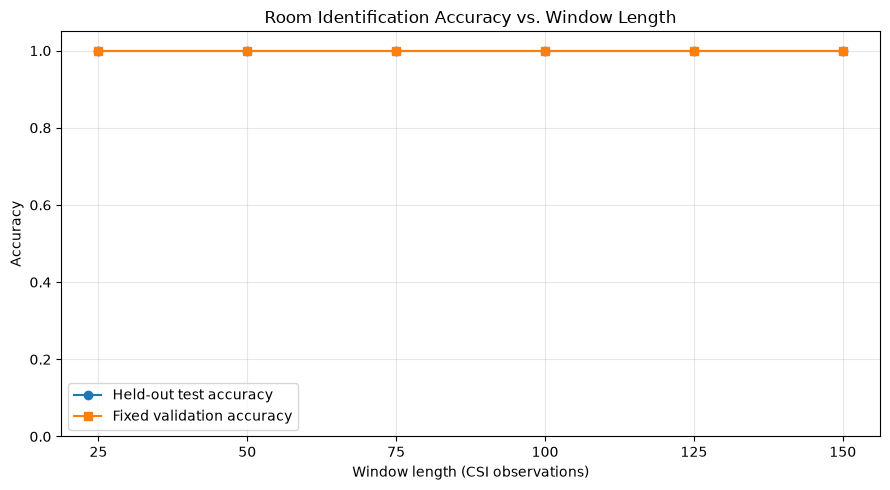

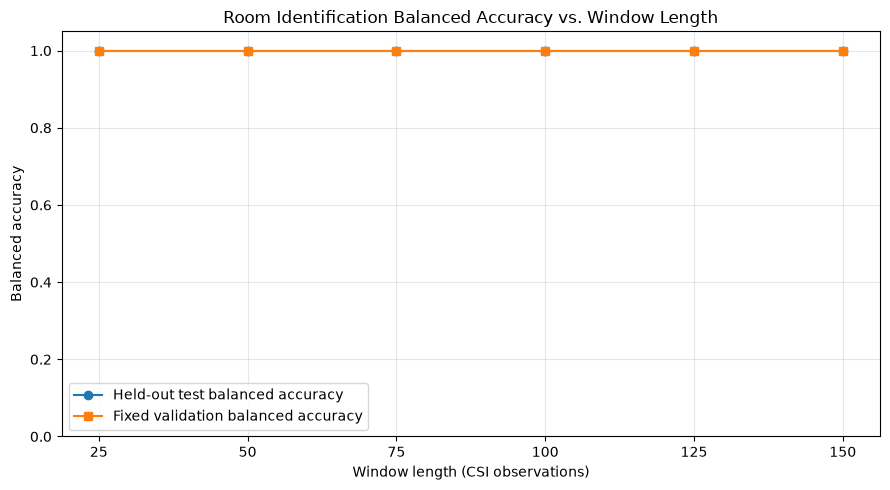


PASS: all window lengths have been trained and evaluated.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score

from scripts.room_classifier import extract_room_features

window_length_results = []
window_length_models = {}

for length in WINDOW_LENGTHS:
    print(f"\nEvaluating window length: {length}")

    data = window_length_datasets[length]

    # Extract features from each split separately.
    X_train_features = extract_room_features(data["X_train"])
    X_test_features = extract_room_features(data["X_test"])
    X_val_features = extract_room_features(data["X_val"])

    y_train = data["y_train"]
    y_test = data["y_test"]
    y_val = data["y_val"]

    # Fit preprocessing and classifier on training data only.
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42,
        ),
    )

    model.fit(X_train_features, y_train)

    # Evaluate on the capture-disjoint held-out development test set.
    y_test_pred = model.predict(X_test_features)

    test_accuracy = accuracy_score(y_test, y_test_pred)
    test_balanced_accuracy = balanced_accuracy_score(
        y_test, y_test_pred
    )

    # Evaluate on the fixed validation captures.
    y_val_pred = model.predict(X_val_features)

    val_accuracy = accuracy_score(y_val, y_val_pred)
    val_balanced_accuracy = balanced_accuracy_score(
        y_val, y_val_pred
    )

    window_length_models[length] = model

    window_length_results.append({
        "window_length": length,
        "test_accuracy": test_accuracy,
        "test_balanced_accuracy": test_balanced_accuracy,
        "validation_accuracy": val_accuracy,
        "validation_balanced_accuracy": val_balanced_accuracy,
        "test_errors": int(np.sum(y_test != y_test_pred)),
        "validation_errors": int(np.sum(y_val != y_val_pred)),
    })

    print(f"Test accuracy:              {test_accuracy:.4f}")
    print(f"Test balanced accuracy:     {test_balanced_accuracy:.4f}")
    print(f"Validation accuracy:       {val_accuracy:.4f}")
    print(f"Validation balanced acc.:  {val_balanced_accuracy:.4f}")

window_length_results_df = pd.DataFrame(window_length_results)

print("\nWindow-length experiment summary:")
display(
    window_length_results_df.round(4)
)

# Plot 1: Accuracy across window lengths.
plt.figure(figsize=(9, 5))
plt.plot(
    window_length_results_df["window_length"],
    window_length_results_df["test_accuracy"],
    marker="o",
    label="Held-out test accuracy",
)
plt.plot(
    window_length_results_df["window_length"],
    window_length_results_df["validation_accuracy"],
    marker="s",
    label="Fixed validation accuracy",
)
plt.xlabel("Window length (CSI observations)")
plt.ylabel("Accuracy")
plt.title("Room Identification Accuracy vs. Window Length")
plt.xticks(WINDOW_LENGTHS)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: Balanced accuracy across window lengths.
plt.figure(figsize=(9, 5))
plt.plot(
    window_length_results_df["window_length"],
    window_length_results_df["test_balanced_accuracy"],
    marker="o",
    label="Held-out test balanced accuracy",
)
plt.plot(
    window_length_results_df["window_length"],
    window_length_results_df["validation_balanced_accuracy"],
    marker="s",
    label="Fixed validation balanced accuracy",
)
plt.xlabel("Window length (CSI observations)")
plt.ylabel("Balanced accuracy")
plt.title("Room Identification Balanced Accuracy vs. Window Length")
plt.xticks(WINDOW_LENGTHS)
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nPASS: all window lengths have been trained and evaluated.")

**Key findings**

1. Very short windows are sufficient for this dataset. Using 25 observations—one-sixth of the full 150-observation window—still produced perfect room classification.
2. Performance remained stable across all tested lengths. There was no observed accuracy decrease as the window length shortened.
3. The held-out test split is capture-grouped, reducing the risk of the same capture appearing in both training and test sets.
4. Interpret the result within this experiment’s scope. Perfect performance does not guarantee the classifier will generalize to new recording sessions, devices, or environments. Also, the Room B validation set contains multiple windows per capture, so its window-level scores should not be interpreted as independent-capture scores.

#### 14.12B — Verify the results table
Purpose: Confirm the result table has the intended columns and values, then create a clean report-ready table.

In [ ]:
# Step 14.12B — Validate and format the window-length results

expected_columns = [
    "window_length",
    "test_accuracy",
    "test_balanced_accuracy",
    "validation_accuracy",
    "validation_balanced_accuracy",
    "test_errors",
    "validation_errors",
]

assert list(window_length_results_df.columns) == expected_columns, (
    f"Unexpected columns: {list(window_length_results_df.columns)}"
)

assert window_length_results_df["window_length"].tolist() == WINDOW_LENGTHS

metric_columns = [
    "test_accuracy",
    "test_balanced_accuracy",
    "validation_accuracy",
    "validation_balanced_accuracy",
]

assert np.isfinite(
    window_length_results_df[metric_columns].to_numpy(dtype=float)
).all()

assert (
    window_length_results_df[metric_columns].to_numpy(dtype=float) >= 0
).all()

assert (
    window_length_results_df[metric_columns].to_numpy(dtype=float) <= 1
).all()

assert (window_length_results_df["test_errors"] == 0).all()
assert (window_length_results_df["validation_errors"] == 0).all()

report_window_length_results = window_length_results_df.copy()

for column in metric_columns:
    report_window_length_results[column] = (
        report_window_length_results[column].map(lambda value: f"{value:.3f}")
    )

display(report_window_length_results)

print("PASS: Results table columns, lengths, metrics, and error counts verified.")

,window_length,test_accuracy,test_balanced_accuracy,validation_accuracy,validation_balanced_accuracy,test_errors,validation_errors
0,25,1.000,1.000,1.000,1.000,0,0
1,50,1.000,1.000,1.000,1.000,0,0
2,75,1.000,1.000,1.000,1.000,0,0
3,100,1.000,1.000,1.000,1.000,0,0
4,125,1.000,1.000,1.000,1.000,0,0
5,150,1.000,1.000,1.000,1.000,0,0


PASS: Results table columns, lengths, metrics, and error counts verified.


### Task 1 Conclusion: Room Identification and Environment Fingerprinting

The room-identification experiment successfully distinguished Room A from Room B using features extracted from CSI windows. A Logistic Regression classifier with feature standardization achieved **100% accuracy and 100% balanced accuracy** on the capture-grouped held-out test set. It correctly classified all 830 test windows, with no misclassifications. The fixed validation set also achieved 100% accuracy, correctly classifying all 522 windows.

To investigate the effect of observation-window length, separate classifiers were trained and evaluated using windows containing 25, 50, 75, 100, 125, and 150 CSI observations. Both held-out test accuracy and fixed validation accuracy remained at 100% for every window length, with zero errors in all experiments. Therefore, within this dataset and experimental setup, room identification remained highly reliable even when using only 25 observations, one-sixth of the full window length.

These results indicate that the two rooms have distinguishable CSI characteristics and that the extracted features capture useful environmental information. The accuracy-versus-window-length plot provides an environment-fingerprinting comparison across the tested observation lengths.

**Limitations:** These results demonstrate performance on the available data and evaluation splits; they do not establish perfect generalization to unseen recording sessions, devices, or environments. In addition, the validation set contains multiple windows from some Room B captures, so window-level validation results should not be interpreted as independent-capture performance.

**Overall conclusion:** Task 1 establishes a strong room-identification baseline. Since the classifier maintains perfect observed accuracy even with short windows, the next task can focus on self-supervised representation learning and whether learned representations help with cross-room activity recognition and few-shot adaptation.